In [17]:
import numpy as np
from matplotlib import pyplot as plt
import imutils
import ipywidgets as widgets
from IPython.display import display, clear_output,Image
from skimage import data
import glob
import open3d as o3d
import copy
from mpl_toolkits.mplot3d import Axes3D
from math import *
from scipy import ndimage, signal
import sklearn as sk
import pandas as pd
import time
import datetime as dt
import ssl
from tqdm import tqdm
import cv2
from Final_Functions import load_and_undistort_images, CalibrateStereoCamera, robot_masking_MOG2
calibration = np.load("calibration_maps.npz")
Q = calibration["Q"]
fps=30

# Working functions

In [ ]:
def CalibrateStereoCamera():

    # -----
    img = cv2.imread("0_calib/left/000.png")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    h, w = img.shape[:2]
    image_size = (w,h)

    # -----
    nb_vertical = 5
    nb_horizontal = 7

    image_range = 37
    def get_filename(idx: int):
        return f"0_calib/left/{idx:03d}.png", f"0_calib/right/{idx:03d}.png"

    # Prepare object points, like (0, 0, 0), (1, 0, 0), (2, 0, 0) ....,(6, 5, 0).
    objp = np.zeros((nb_horizontal * nb_vertical, 3), np.float32)
    objp[:, :2] = np.mgrid[0:nb_vertical, 0:nb_horizontal].T.reshape(-1, 2)

    # Arrays to store object points and image points from all the images.
    objpoints = []  # 3D point in real world space.
    imgpoints_left = []  # 2D points in image plane.
    imgpoints_right = []  # 2D points in image plane.

    skip_images = [4,6,7,14,17]

    for image_idx in range(image_range):

        if image_idx in skip_images:
            continue

        fname_left, fname_right = get_filename(image_idx)

        img_left = cv2.imread(fname_left)
        img_right = cv2.imread(fname_right)

        ret_left, corners_left = cv2.findChessboardCornersSB(
            img_left, (nb_vertical, nb_horizontal), None
        )

        ret_right, corners_right = cv2.findChessboardCornersSB(
            img_right, (nb_vertical, nb_horizontal), None
        )

        # If found, add object points, image points (after refining them).
        if not (ret_left and ret_right):
            continue

        objpoints.append(objp.copy())
        imgpoints_left.append(corners_left)
        imgpoints_right.append(corners_right)

    

    rms_left, K_left, dist_left, rvecs_left, tvecs_left = cv2.calibrateCamera(
        objpoints, imgpoints_left, image_size, None, None
    )

    rms_right, K_right, dist_right, rvecs_right, tvecs_right = cv2.calibrateCamera(
        objpoints, imgpoints_right, image_size, None, None
    )

    rms_stereo, K_left, dist_left, K_right, dist_right, R, T, E, F = cv2.stereoCalibrate(
        objpoints,
        imgpoints_left, imgpoints_right,
        K_left, dist_left,
        K_right, dist_right,
        image_size,
        flags=cv2.CALIB_FIX_INTRINSIC
    )

    R1, R2, P1, P2, Q, roi1, roi2 = cv2.stereoRectify(
        K_left, dist_left,
        K_right, dist_right,
        image_size,
        R, T,
        flags=cv2.CALIB_ZERO_DISPARITY,
        alpha=0
    )

    mapLx, mapLy = cv2.initUndistortRectifyMap(K_left, dist_left, R1, P1, (w,h), cv2.CV_32FC1)
    mapRx, mapRy = cv2.initUndistortRectifyMap(K_right, dist_right, R2, P2, (w,h), cv2.CV_32FC1)

    np.savez_compressed("calibration_maps.npz",
        mapLx=mapLx,
        mapLy=mapLy,
        mapRx=mapRx,
        mapRy=mapRy,
        Q=Q,
    )
    display(f"Stereo calibration completed. RMS error: {rms_stereo:.4f}")
    return True

In [7]:
def load_and_undistort_images(image_folder, format=cv2.COLOR_BGR2RGB):
    """
    Loads and undistorts images from the specified folder using precomputed calibration maps.
    
    Parameters:
    - image_folder: Path to the folder containing 'left' and 'right' subfolders with images.
    - format: cv2.COLOR_BGR2* format to convert the images to (default is cv2.COLOR_BGR2RGB).

    Returns:
    - undistorted_images_left: List of undistorted left camera images, in chosen format.
    - undistorted_images_right: List of undistorted right camera images, in chosen format.
    - undistorted_images_left_gray: List of undistorted left camera images in grayscale.
    - undistorted_images_right_gray: List of undistorted right camera images in grayscale
    """
    calibration_maps = np.load("calibration_maps.npz")

    mapLx = calibration_maps["mapLx"]
    mapLy = calibration_maps["mapLy"]
    mapRx = calibration_maps["mapRx"]
    mapRy = calibration_maps["mapRy"]
    # Load all images from the specified folder
    image_files_left = sorted(glob.glob(f"{image_folder}/left/*.png"))
    image_files_right = sorted(glob.glob(f"{image_folder}/right/*.png"))    

    undistorted_images_left = []

    for image_file in image_files_left:
        # Read the image
        img = cv2.imread(image_file)
        if img is None:
            print(f"Warning: Could not read image {image_file}. Skipping.")
            continue

        # Undistort the image using the provided maps
        undistorted_img = cv2.remap(img, mapLx, mapLy, interpolation=cv2.INTER_LINEAR)
        undistorted_images_left.append(undistorted_img)

    undistorted_images_right = []
    
    for image_file in image_files_right:
        # Read the image
        img = cv2.imread(image_file)
        if img is None:
            print(f"Warning: Could not read image {image_file}. Skipping.")
            continue

        # Undistort the image using the provided maps
        undistorted_img = cv2.remap(img, mapRx, mapRy, interpolation=cv2.INTER_LINEAR)
        undistorted_images_right.append(undistorted_img)

    
    undistorted_images_left_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in undistorted_images_left]
    undistorted_images_right_gray = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in undistorted_images_right]
    undistorted_images_left = [cv2.cvtColor(img, format) for img in undistorted_images_left]
    undistorted_images_right = [cv2.cvtColor(img, format) for img in undistorted_images_right]

    return undistorted_images_left, undistorted_images_right, undistorted_images_left_gray, undistorted_images_right_gray


In [8]:

def robot_masking_MOG2(left_images, history=100, var_threshold=16):
    """
    Apply MOG2 background subtraction to a list of left images and return foreground masks.
    """
    mog = cv2.createBackgroundSubtractorMOG2(
        history=history,
        varThreshold=var_threshold,
        detectShadows=False
    )

    foreground_masks = []

    kernel = np.ones((3, 3), np.uint8)

    for i, img in enumerate(left_images):
        if i < 2:
            mog.apply(img)  # Learn the background
            foreground_masks.append(
                np.zeros(img.shape[:2], dtype=np.uint8)
            )
            continue

        mask = mog.apply(img)


        mask = cv2.morphologyEx(
            mask, cv2.MORPH_OPEN, kernel
        )

        mask = cv2.morphologyEx(
            mask, cv2.MORPH_CLOSE, kernel
        )

        num_labels, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(mask)
        )

        if num_labels > 1:
            largest = 1 + np.argmax(
                stats[1:, cv2.CC_STAT_AREA]
            )
            mask = np.uint8(labels == largest) * 255

        foreground_masks.append(mask)

    return foreground_masks

In [19]:

def filter_robot_positions_jerk(
    robot_positions,
    dt,
    measurement_std,
    jerk_std,
    initial_velocity_std,
    initial_acceleration_std
):
    """
    parameters:
    - robot_positions: List of 3D positions (x, y, z) of the robot over time.
    - dt: Time step between measurements.
    - measurement_std: Standard deviation of the measurement noise.
    - jerk_std: Standard deviation of the jerk (third derivative of position).
    - initial_velocity_std: Standard deviation of the initial velocity estimate.
    - initial_acceleration_std: Standard deviation of the initial acceleration estimate.

    Output:
    - filtered: List of filtered 3D positions (x, y, z) of the robot over time, after applying the Kalman filter with jerk modeling.

    """

    measurements = np.asarray(robot_positions, dtype=float)
    filtered = np.full_like(measurements, np.nan)

    I = np.eye(3)
    kf = cv2.KalmanFilter(9, 3, 0, cv2.CV_64F)

    F = np.eye(9)
    F[0:3, 3:6] = dt * I
    F[0:3, 6:9] = 0.5 * dt**2 * I
    F[3:6, 6:9] = dt * I
    kf.transitionMatrix = F

    # Measurements still contain position only: x, y, z.
    H = np.zeros((3, 9))
    H[:, :3] = I
    kf.measurementMatrix = H

    # Measurement uncertainty.
    R = measurement_std**2 * np.eye(3)
    kf.measurementNoiseCov = R  

    G = np.vstack([
        (dt**3 / 6) * I,
        (dt**2 / 2) * I,
        dt * I,
    ])

    kf.processNoiseCov = jerk_std**2 * (G @ G.T)

    initialized = False

    for i, position in enumerate(measurements):
        valid = np.isfinite(position).all()

        if not initialized:
            if not valid:
                continue

            kf.statePost = np.concatenate([
                position, np.zeros(6)
            ]).reshape(9, 1)

            kf.errorCovPost = np.diag(
                [measurement_std**2] * 3
                + [initial_velocity_std**2] * 3
                + [initial_acceleration_std**2] * 3
            )

            filtered[i] = position
            initialized = True
            continue

        prediction = kf.predict()

        if valid:
            estimate = kf.correct(position.reshape(3, 1))
        else:
            estimate = prediction

        filtered[i] = estimate[:3, 0]

    return filtered

In [10]:
def create_stereo_matchers(min_disparity=0, num_disparities=5*16, block_size=3):
    left_matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        # Start searching at disparity 0, so far points can still match.
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8*block_size**2,
        P2=32*block_size**2,
        disp12MaxDiff=1,
        # Drop a pixel when the left-right and right-left disparities differ by more than 1.
        preFilterCap=31,
        # Clip the image gradient so bright spots do not dominate the match cost.
        uniquenessRatio=20,
        # Keep a match only when it beats the second-best cost by xx percent.
        speckleWindowSize=80,
        # Remove connected disparity blobs smaller than 80 pixels.
        speckleRange=2,
        # Pixels in one blob may differ by at most 2 disparity levels.
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
        # Match along horizontal, vertical, and diagonal paths.
    )
    wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
    wls.setLambda(2000)
    wls.setSigmaColor(0.8)
    right_matcher = cv2.ximgproc.createRightMatcher(left_matcher)

    return left_matcher, right_matcher, wls

In [11]:

def calculate_disparity_map(left_matcher, right_matcher, wls, left_image_gray, right_image_gray,test=False):

    disp_left = left_matcher.compute(left_image_gray, right_image_gray)
    disp_right = right_matcher.compute(right_image_gray, left_image_gray)

    # Spread reliable disparity into flat pixels, but stop at a color edge
    disparity_map = wls.filter(disp_left, left_image_gray, None, disp_right).astype(np.float32) / 16
    
    # Invalid pixels are -2048. Keep them out of the color scale.
    disparity_map[disparity_map < 0] = np.nan

    ### TEMP ###
    raw_disparity = disp_left.astype(np.float32) / 16.0
    filtered_disparity = (
        wls.filter(disp_left, left_image_gray, None, disp_right)
        .astype(np.float32) / 16.0
    )
    confidence = wls.getConfidenceMap()
    ### TEMP END ### 
    if test:
        return disparity_map, raw_disparity , confidence
    return disparity_map

In [12]:
def point_cloud_from_disparity(disparity_map, left_image, Q, min_disparity=3, ):   

    points_3D = cv2.reprojectImageTo3D(disparity_map, Q)

    mask = ((disparity_map > min_disparity) & np.isfinite(points_3D).all(axis=2))

    points = points_3D[mask]
    colors = left_image[mask] / 255.0

    pcd = o3d.geometry.PointCloud()

    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(colors)
    
    pcd, ind = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

    return pcd

In [13]:
def reconstruct_robot_trajectory(left_images, left_images_gray, right_images_gray, foreground_masks, left_matcher, right_matcher, wls, Q):
    """Return robot point clouds and centroid positions for all frames."""

    robot_pcds = []
    robot_positions = []

    frames = zip(left_images, left_images_gray, right_images_gray, foreground_masks, strict=True)

    for left_image, left_gray, right_gray, foreground_mask in frames:
        disparity_map = calculate_disparity_map(
            left_matcher, right_matcher, wls, left_gray, right_gray
        )

        # Preserve pixel coordinates while excluding the background.
        robot_disparity = disparity_map.copy()
        robot_disparity[foreground_mask <= 0] = np.nan

        robot_pcd = point_cloud_from_disparity(
            robot_disparity, left_image, Q
        )
        robot_pcds.append(robot_pcd)

        points = np.asarray(robot_pcd.points)
        center = (
            points.mean(axis=0)
            if len(points) > 0
            else np.full(3, np.nan)
        )
        robot_positions.append(center)

    return robot_pcds, np.asarray(robot_positions)

In [14]:
def visualize_robot_trajectory(scene_pcd, robot_positions):
    """Show robot centroids and trajectory within the reconstructed scene."""
    positions = np.asarray(robot_positions, dtype=float)
    valid = np.isfinite(positions).all(axis=1)

    if not valid.any():
        raise ValueError("No valid robot positions to visualize.")

    # Map original frame indices to the filtered point indices.
    point_indices = np.full(len(positions), -1, dtype=int)
    point_indices[valid] = np.arange(valid.sum())

    # Connect consecutive frames only, preserving gaps in tracking.
    consecutive = np.flatnonzero(valid[:-1] & valid[1:])
    lines = np.column_stack((
        point_indices[consecutive],
        point_indices[consecutive + 1],
    ))

    trajectory_points = positions[valid]

    centroids = o3d.geometry.PointCloud()
    centroids.points = o3d.utility.Vector3dVector(trajectory_points)
    centroids.paint_uniform_color([1.0, 0.0, 0.0])

    trajectory = o3d.geometry.LineSet()
    trajectory.points = o3d.utility.Vector3dVector(trajectory_points)
    trajectory.lines = o3d.utility.Vector2iVector(lines)
    trajectory.paint_uniform_color([1.0, 0.6, 0.0])

    o3d.visualization.draw_geometries(
        [scene_pcd, centroids, trajectory],
        window_name="Robot trajectory",
        width=1280,
        height=720,
    )

# Working area

In [ ]:
calibration_success = CalibrateStereoCamera()
display(calibration_success)

720 1280


True

In [ ]:
# undistL, undistR, undistLg, undistRg = load_and_undistort_images('1_no_obstacle')
undistL, undistR, undistLg, undistRg = load_and_undistort_images('4_circle')

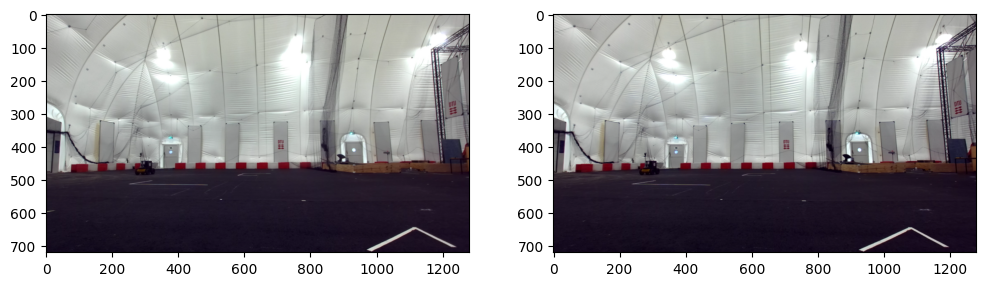

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(undistL[100])
ax[1].imshow(undistR[100])

### optical flow to track 

In [73]:
undistL, undistR, undistLg, undistRg = load_and_undistort_images('2_obstacle')

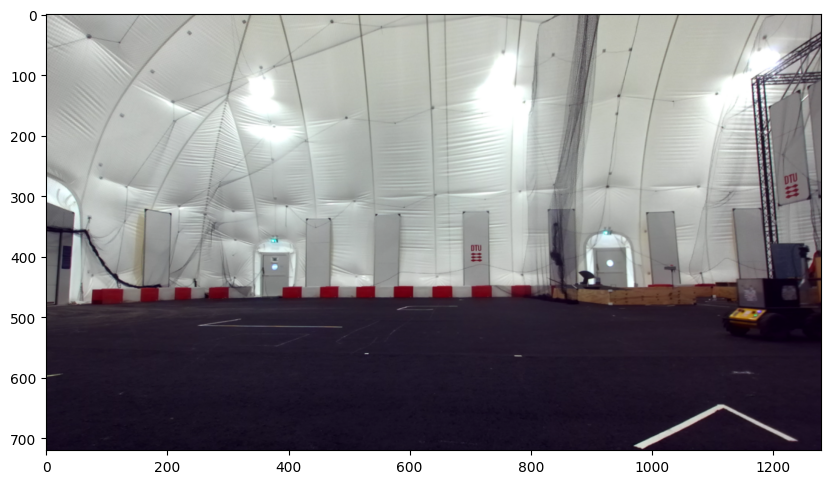

In [71]:
plt.figure(figsize=(10, 6))
plt.imshow(undistL[350])

In [ ]:
def detect_robot_dense_optical(undistL, undistLg, undistR, undistRg):
    '''
    Detects the robot in a sequence of undistorted grayscale images
    by computing optical flow and generating masks based on the magnitude of the flow.

    parameters:
    - folder: Path to the folder containing the images. as string

    returns:
    - masks: List of masks only indicating the detected robot regions in each frame.
    '''
    
    flows = []
    magnitudes = []
    shape = undistLg[0].shape
    ROIy = [300, 600]
    ROIx = [0, 1280]

    foreground_masks = []

    # loop through the undistorted grayscale images to compute optical flow
    # for i in range(len(undistLg) - 1):
    start_frame = 70
    end_frame = 255
    for i in range(start_frame, end_frame):
        gray1 = undistLg[i]
        gray2 = undistLg[i + 1]

        gray1 = gray1[ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]]
        gray2 = gray2[ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]]

        # get Optical flow
        flow = cv2.calcOpticalFlowFarneback(
            gray1, gray2,
            None,
            0.5, 3, 15, 3, 5, 1.5, 0
        )

        # convert flow to polar coordinates to get magnitude and angle
        mag,theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

        flows.append(flow)
        magnitudes.append(mag)

        # threshold = 20
        # # get region of interest (ROI) for the robot based on the magnitude of the flow
        # roi = (mag > threshold).astype(np.uint8) * 255
        # kernel2 = np.ones((3, 3), np.uint8)
        # roi = cv2.morphologyEx(roi, cv2.MORPH_OPEN, kernel2)


    # Create masks based on the magnitude of the optical flow
    threshold = 3.0
    open_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    
    
    masks = [
        (magnitude > threshold).astype(np.uint8) * 255
        for magnitude in magnitudes
    ]

    # do opening and closing to remove noise and fill gaps in the masks
    masks = [cv2.morphologyEx(mask, cv2.MORPH_OPEN, open_kernel) for mask in masks]
    masks = [cv2.morphologyEx(mask, cv2.MORPH_CLOSE, close_kernel, iterations=3) for mask in masks]
    

    #expand the masks to the original image size
    expanded_masks = []
    for mask in masks:
        expanded_mask = np.zeros(shape, dtype=np.uint8)
        expanded_mask[ROIy[0]:ROIy[1], ROIx[0]:ROIx[1]] = mask
        expanded_masks.append(expanded_mask)
    
    num_labels, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(mask)
        )

    if num_labels > 1:
        largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )
        mask = np.uint8(labels == largest) * 255

    foreground_masks.append(mask)

    return 

In [ ]:

def calculate_disparity_map(left_matcher, right_matcher, wls, left_image_gray, right_image_gray,test=False):

    disp_left = left_matcher.compute(left_image_gray, right_image_gray)
    disp_right = right_matcher.compute(right_image_gray, left_image_gray)

    # Spread reliable disparity into flat pixels, but stop at a color edge
    disparity_map = wls.filter(disp_left, left_image_gray, None, disp_right).astype(np.float32) / 16
    
    # Invalid pixels are -2048. Keep them out of the color scale.
    disparity_map[disparity_map < 0] = np.nan

    ### TEMP ###
    raw_disparity = disp_left.astype(np.float32) / 16.0
    filtered_disparity = (
        wls.filter(disp_left, left_image_gray, None, disp_right)
        .astype(np.float32) / 16.0
    )
    confidence = wls.getConfidenceMap()
    ### TEMP END ### 
    if test:
        return disparity_map, raw_disparity , confidence
    return disparity_map

In [ ]:
def point_cloud_from_disparity(disparity_map, left_image, Q, min_disparity=3, ):   

    points_3D = cv2.reprojectImageTo3D(disparity_map, Q)

    mask = ((disparity_map > min_disparity) & np.isfinite(points_3D).all(axis=2))

    points = points_3D[mask]
    colors = left_image[mask] / 255.0

    pcd = o3d.geometry.PointCloud()

    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(colors)
    
    pcd, ind = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

    return pcd

In [ ]:
def reconstruct_robot_trajectory(left_images, left_images_gray, right_images_gray, foreground_masks, left_matcher, right_matcher, wls, Q):
    """Return robot point clouds and centroid positions for all frames."""

    robot_pcds = []
    robot_positions = []

    frames = zip(left_images, left_images_gray, right_images_gray, foreground_masks, strict=True)

    for left_image, left_gray, right_gray, foreground_mask in frames:
        disparity_map = calculate_disparity_map(
            left_matcher, right_matcher, wls, left_gray, right_gray
        )

        # Preserve pixel coordinates while excluding the background.
        robot_disparity = disparity_map.copy()
        robot_disparity[foreground_mask <= 0] = np.nan

        robot_pcd = point_cloud_from_disparity(
            robot_disparity, left_image, Q
        )
        robot_pcds.append(robot_pcd)

        points = np.asarray(robot_pcd.points)
        center = (
            points.mean(axis=0)
            if len(points) > 0
            else np.full(3, np.nan)
        )
        robot_positions.append(center)

    return robot_pcds, np.asarray(robot_positions)

In [ ]:
def visualize_robot_trajectory(scene_pcd, robot_positions):
    """Show robot centroids and trajectory within the reconstructed scene."""
    positions = np.asarray(robot_positions, dtype=float)
    valid = np.isfinite(positions).all(axis=1)

    if not valid.any():
        raise ValueError("No valid robot positions to visualize.")

    # Map original frame indices to the filtered point indices.
    point_indices = np.full(len(positions), -1, dtype=int)
    point_indices[valid] = np.arange(valid.sum())

    # Connect consecutive frames only, preserving gaps in tracking.
    consecutive = np.flatnonzero(valid[:-1] & valid[1:])
    lines = np.column_stack((
        point_indices[consecutive],
        point_indices[consecutive + 1],
    ))

    trajectory_points = positions[valid]

    centroids = o3d.geometry.PointCloud()
    centroids.points = o3d.utility.Vector3dVector(trajectory_points)
    centroids.paint_uniform_color([1.0, 0.0, 0.0])

    trajectory = o3d.geometry.LineSet()
    trajectory.points = o3d.utility.Vector3dVector(trajectory_points)
    trajectory.lines = o3d.utility.Vector2iVector(lines)
    trajectory.paint_uniform_color([1.0, 0.6, 0.0])

    o3d.visualization.draw_geometries(
        [scene_pcd, centroids, trajectory],
        window_name="Robot trajectory",
        width=1280,
        height=720,
    )

C:\Users\emil\AppData\Local\Temp\ipykernel_50200\465051056.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 6))


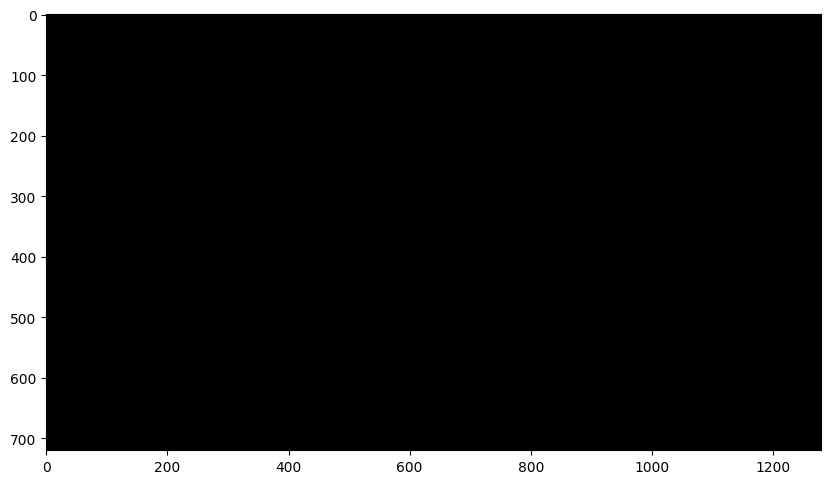

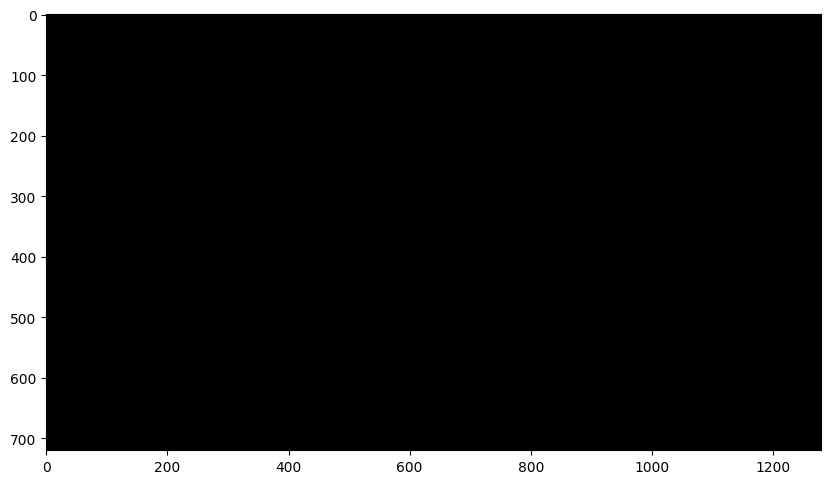

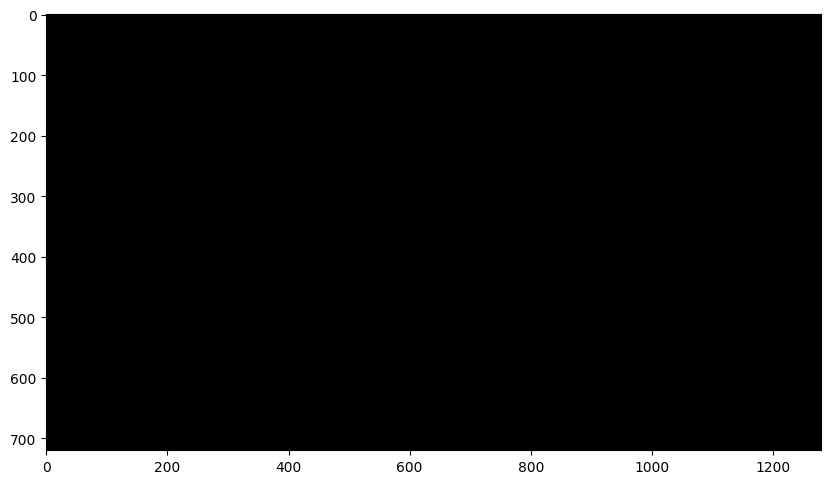

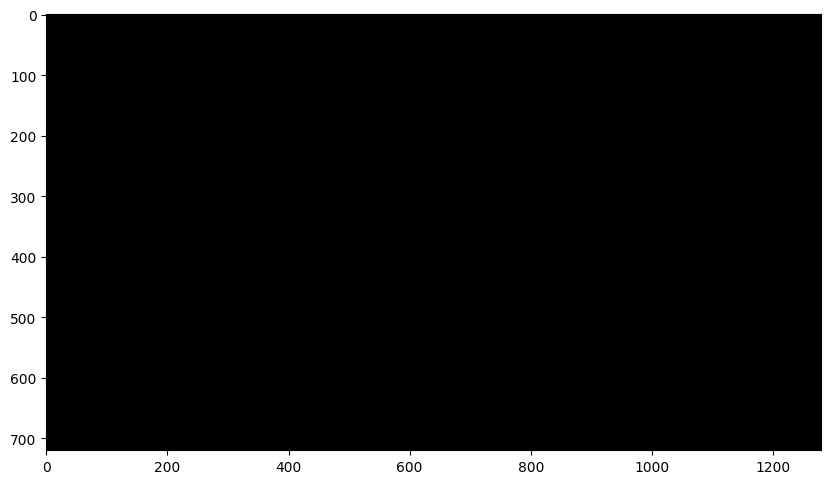

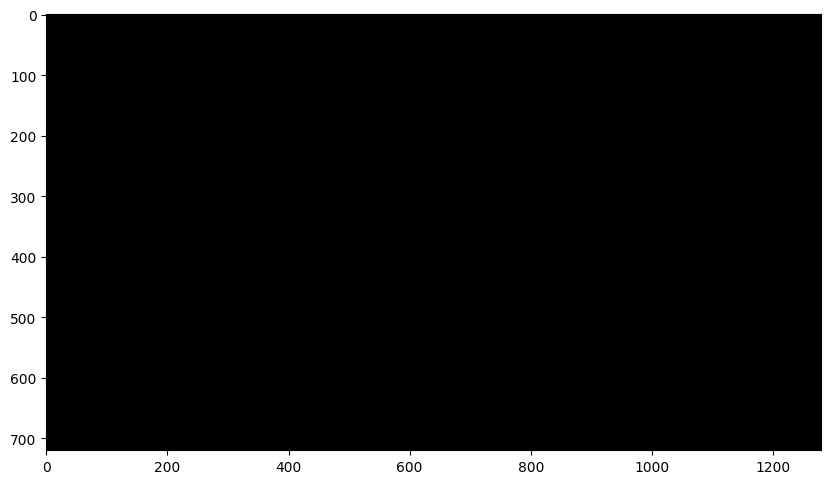

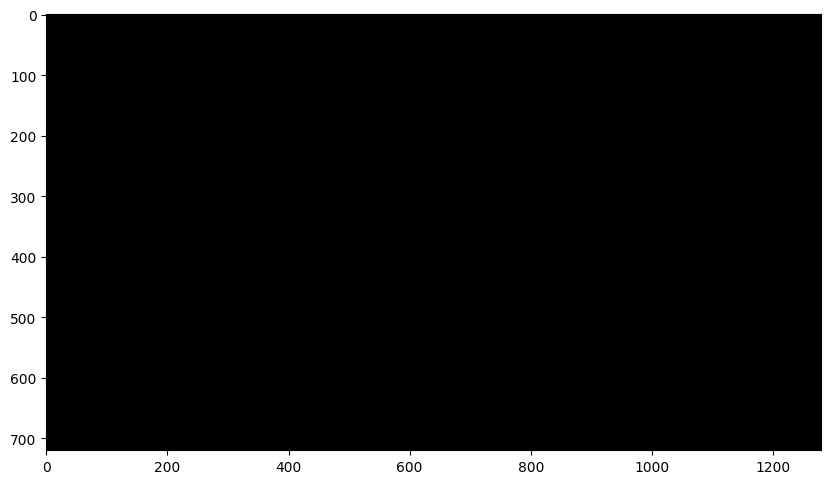

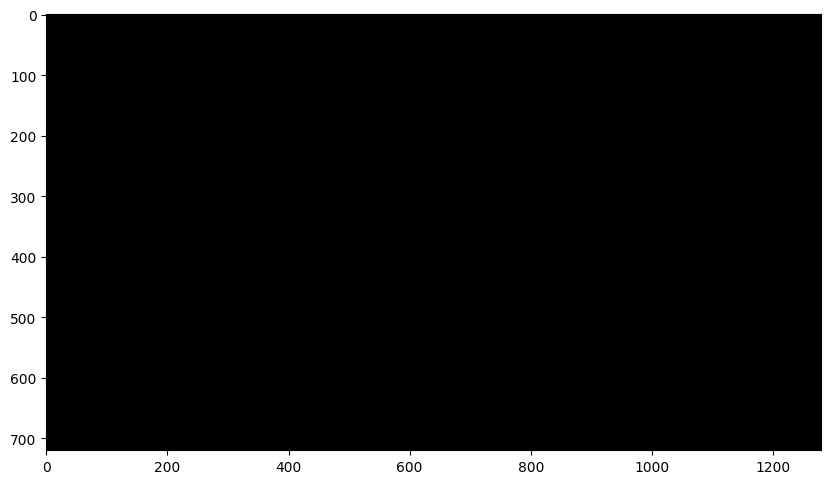

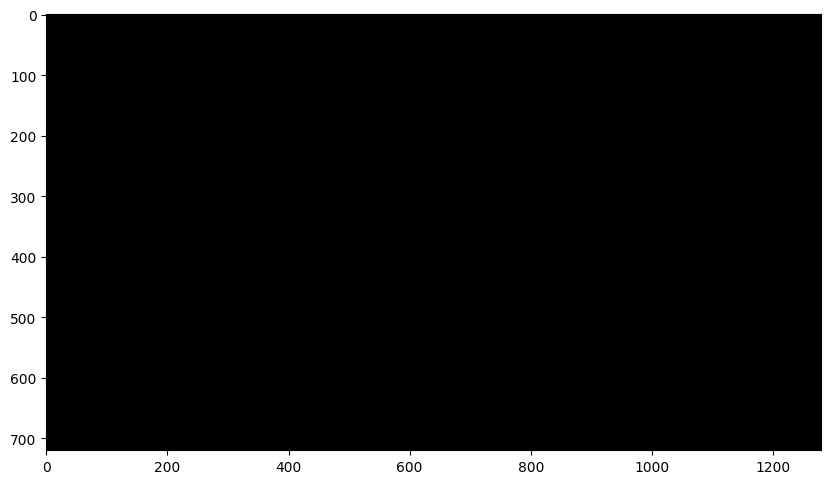

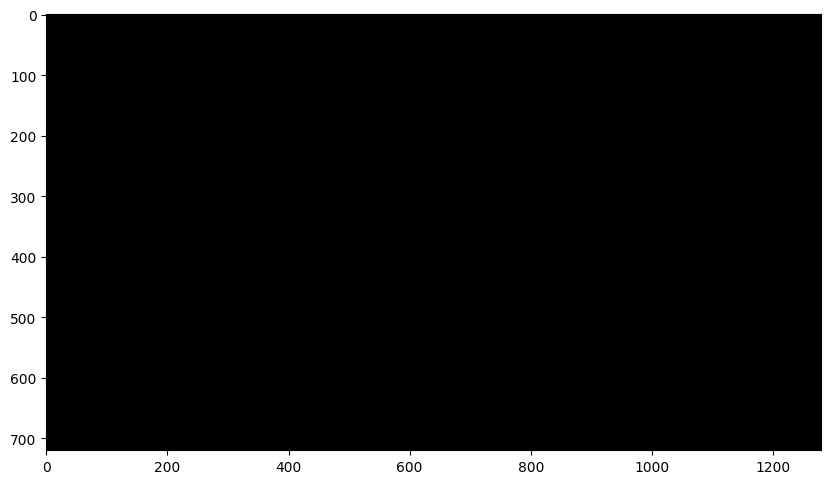

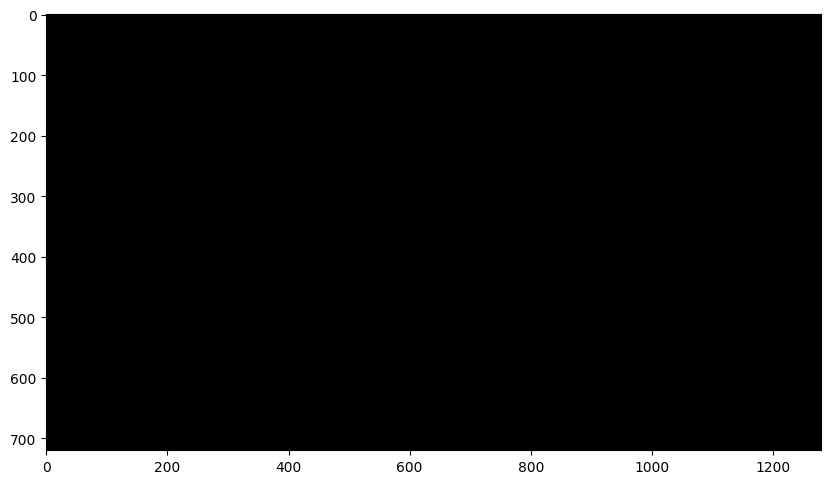

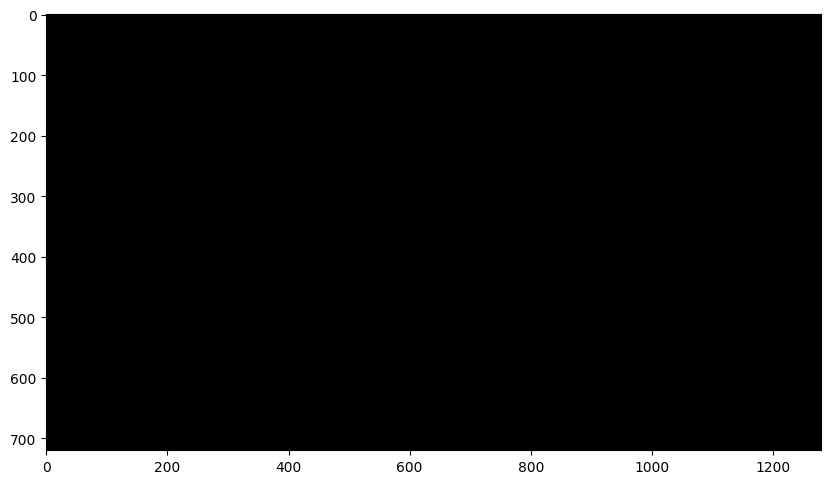

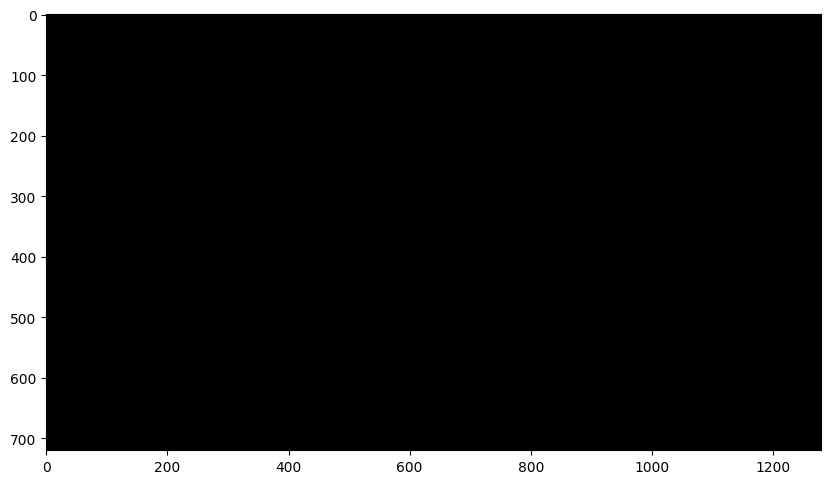

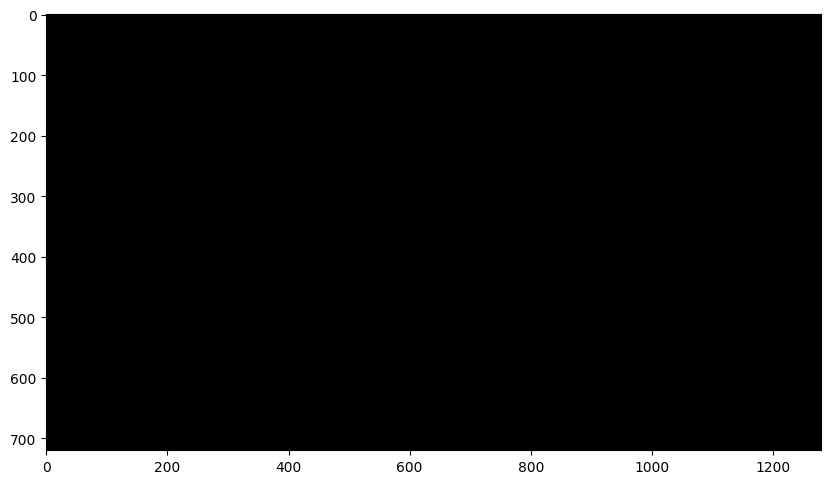

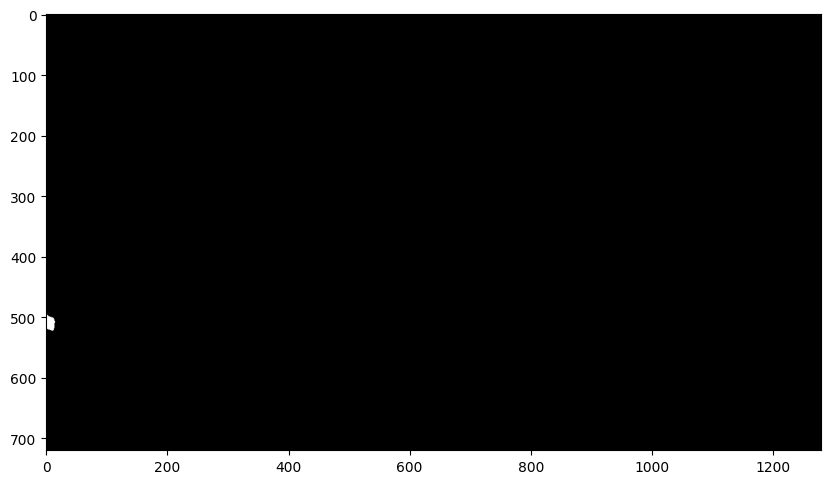

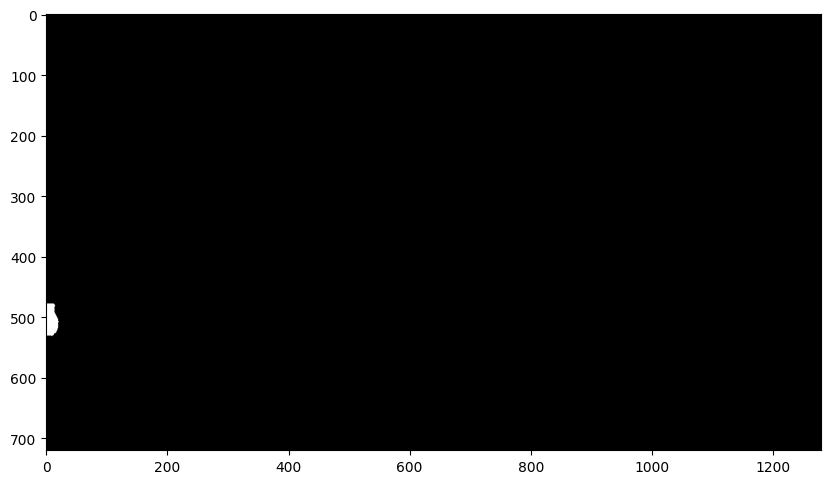

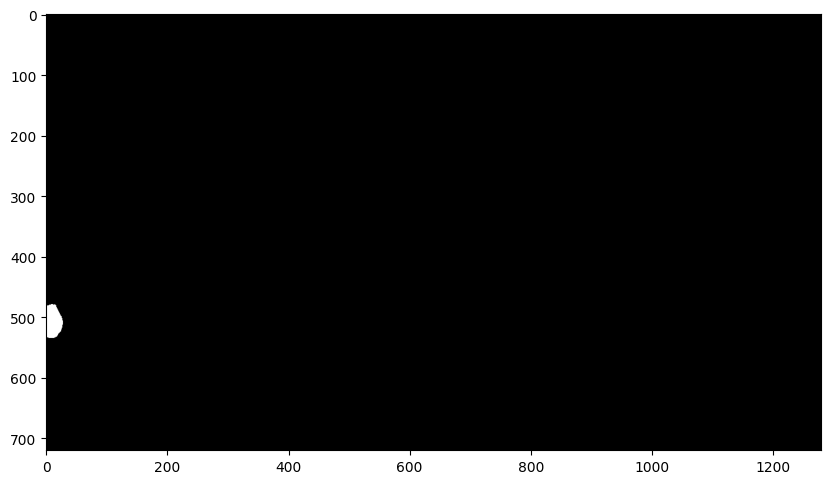

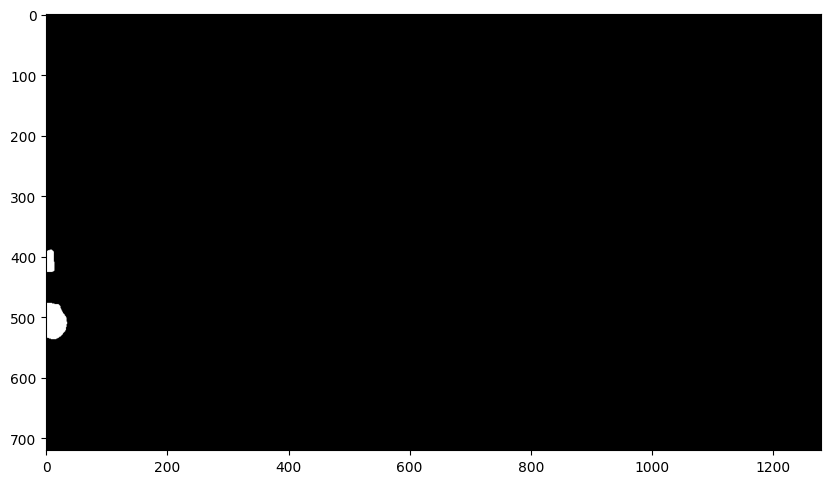

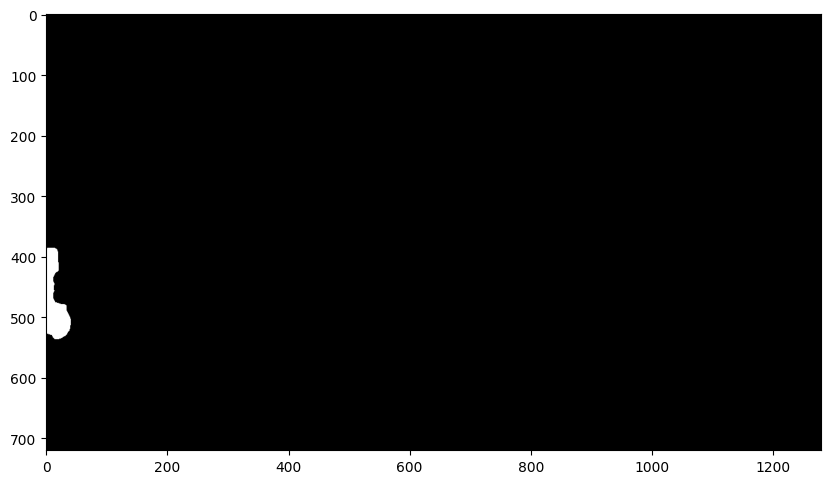

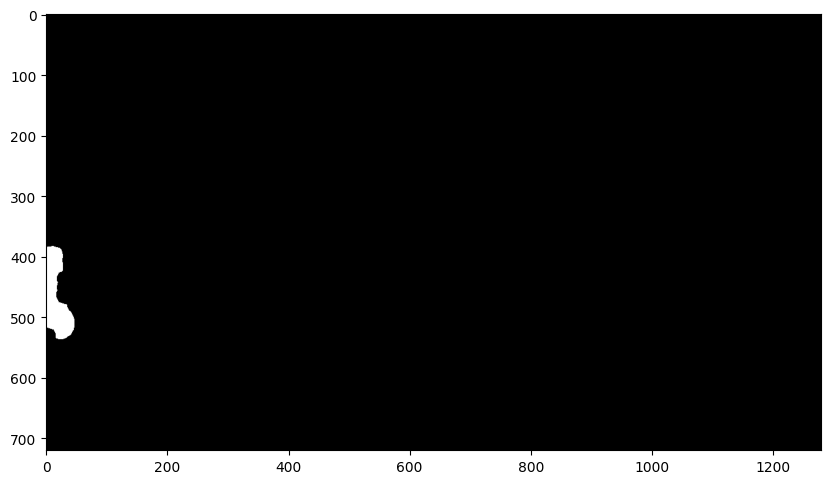

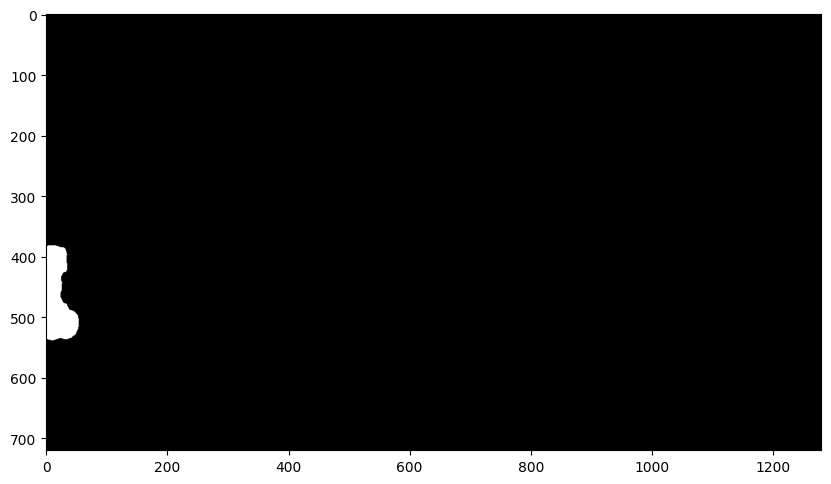

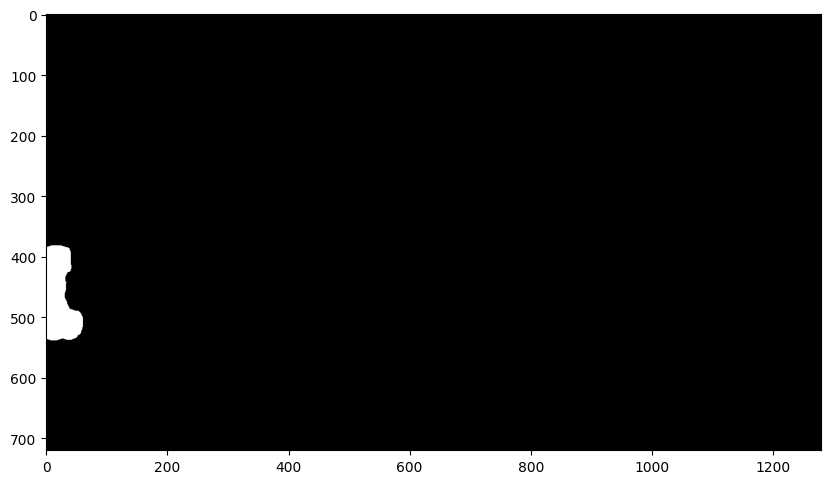

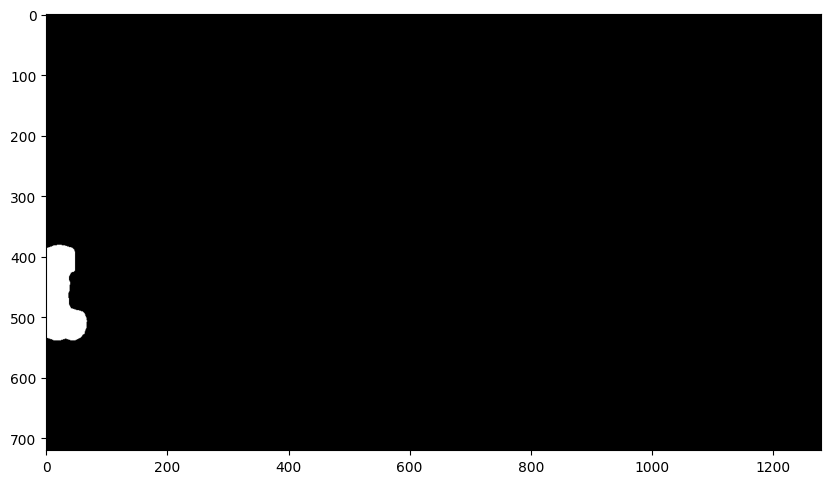

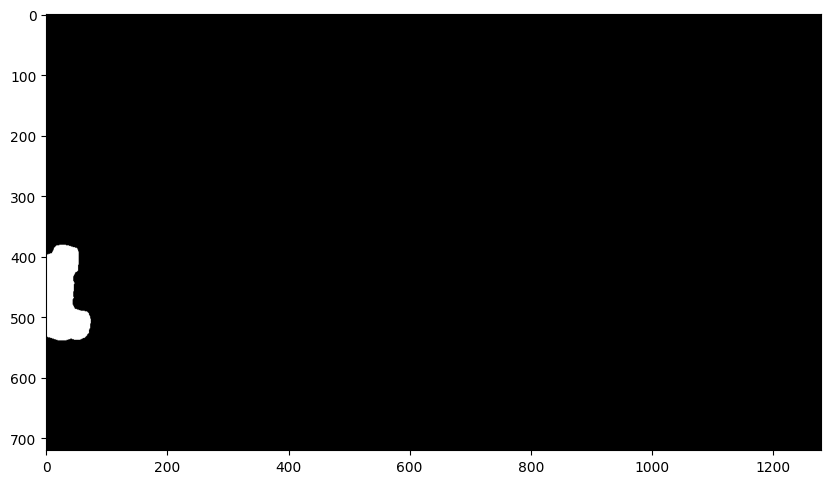

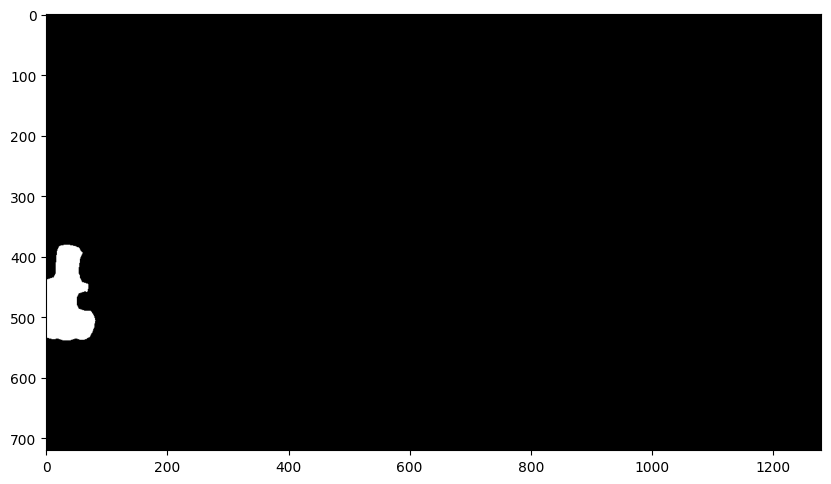

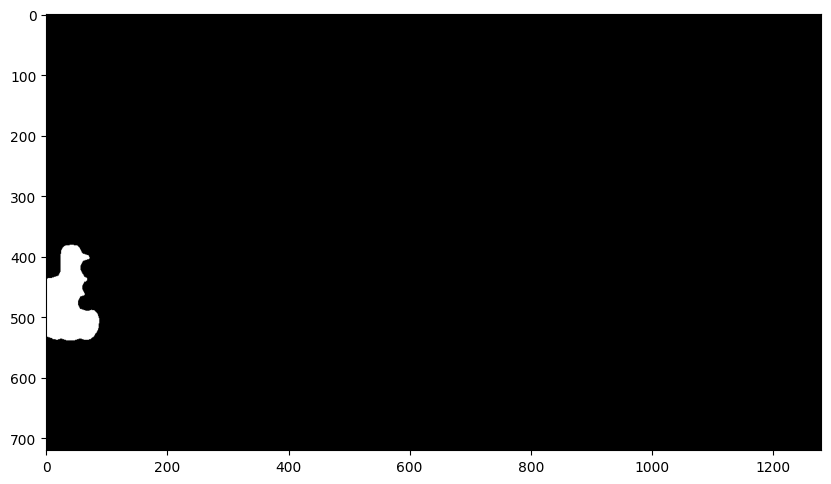

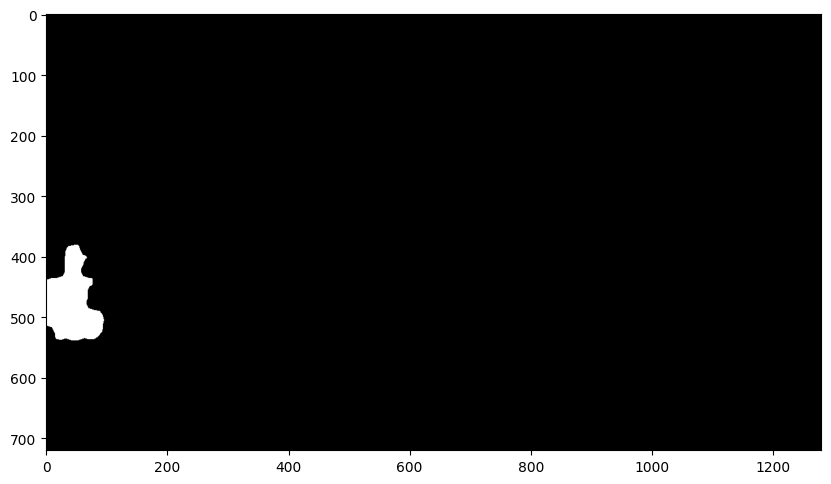

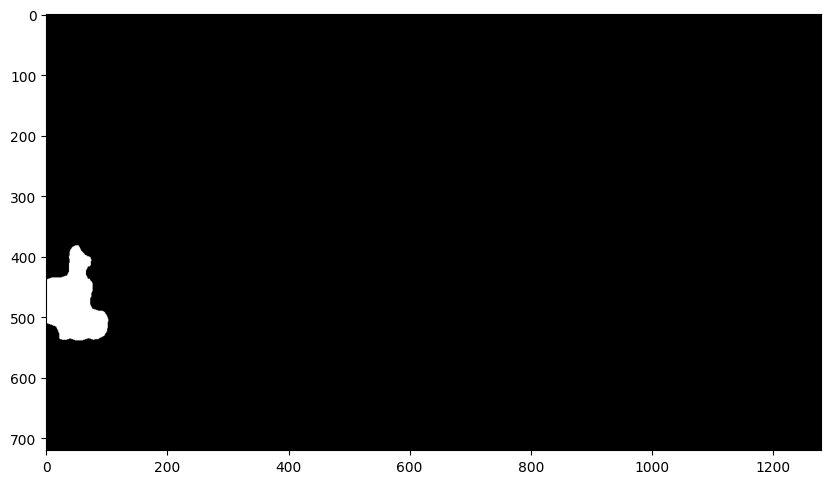

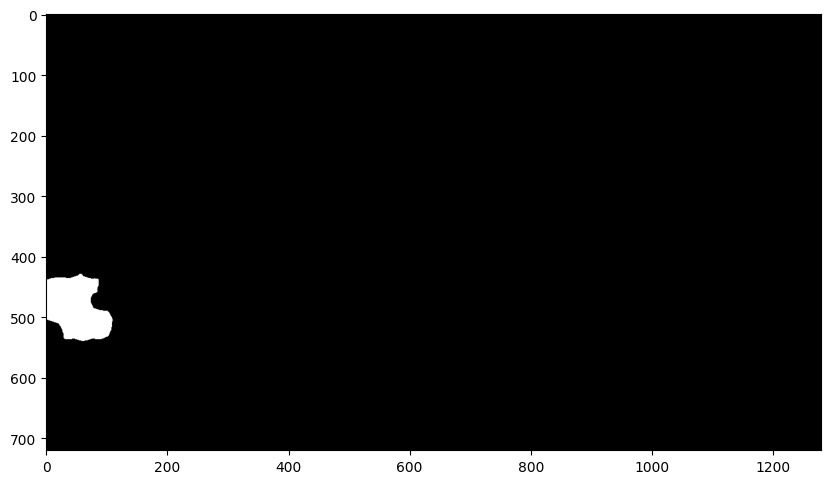

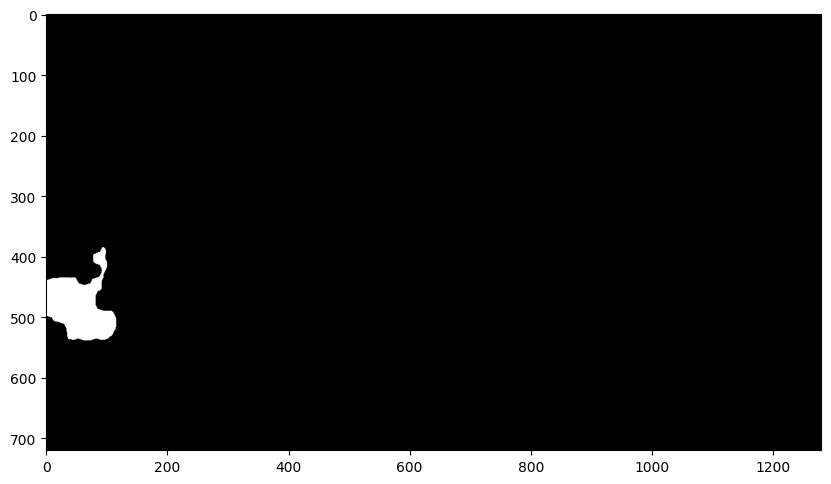

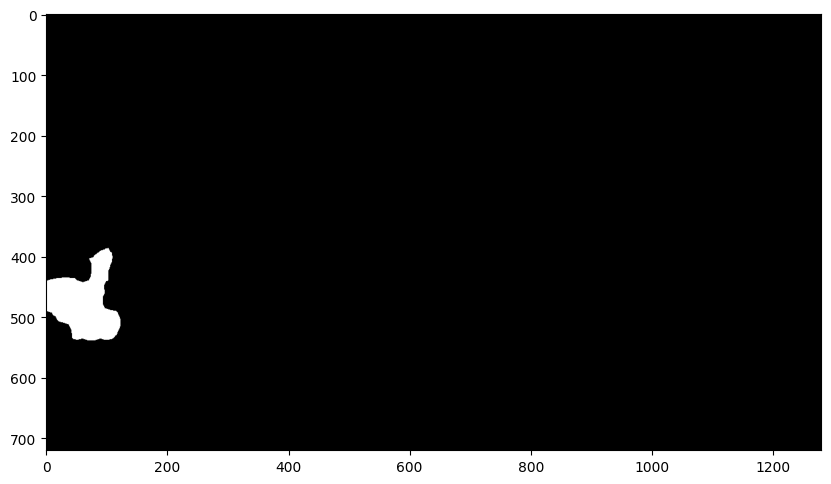

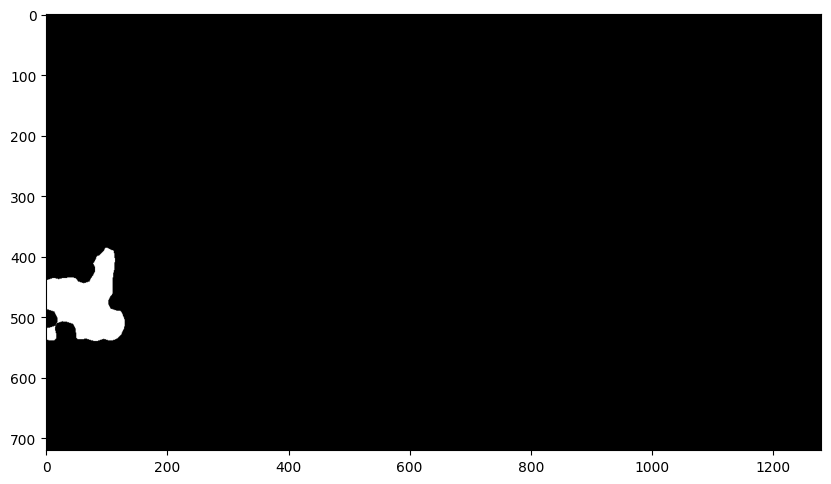

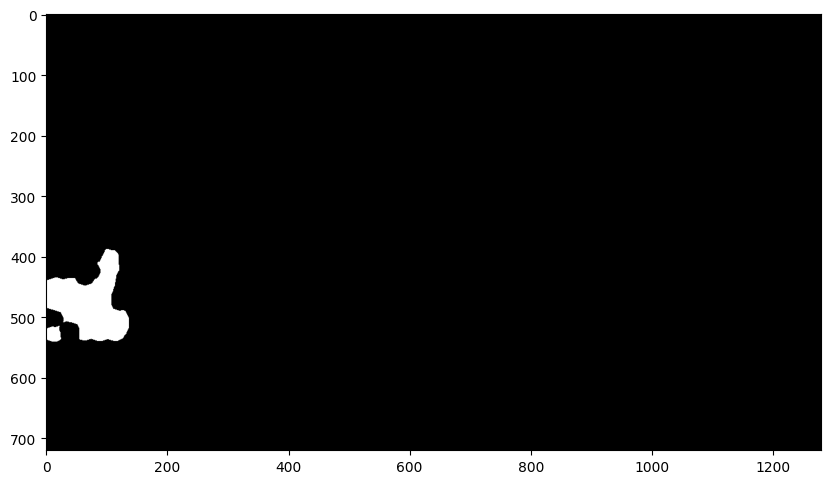

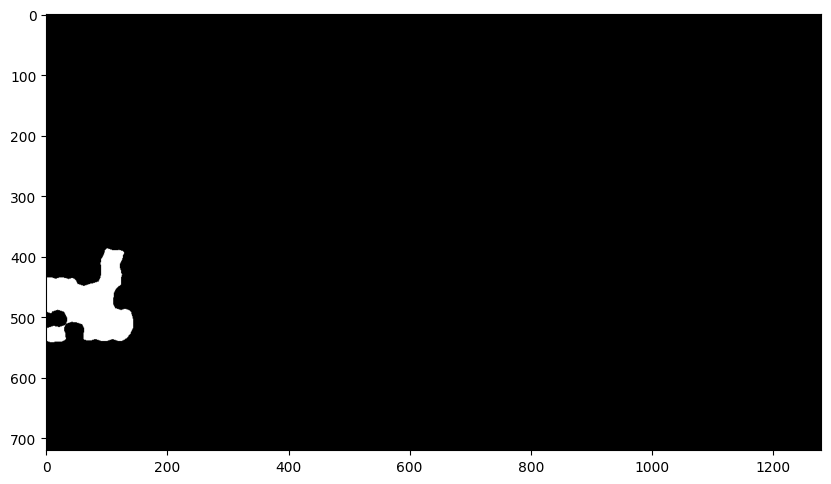

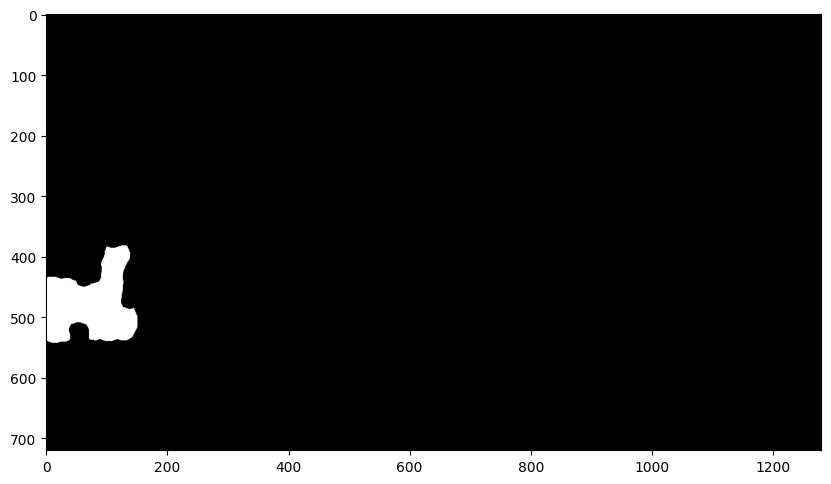

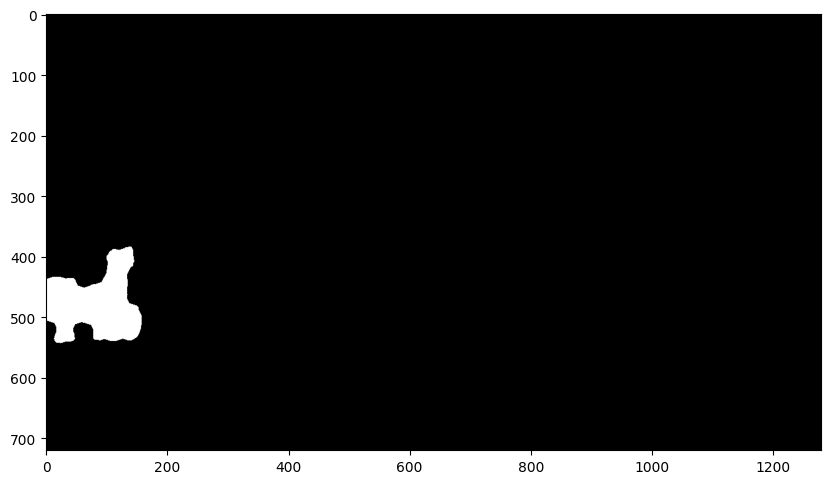

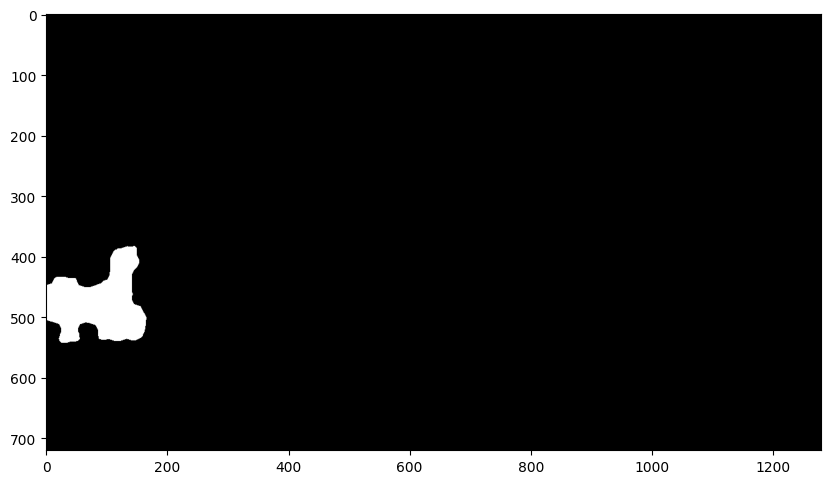

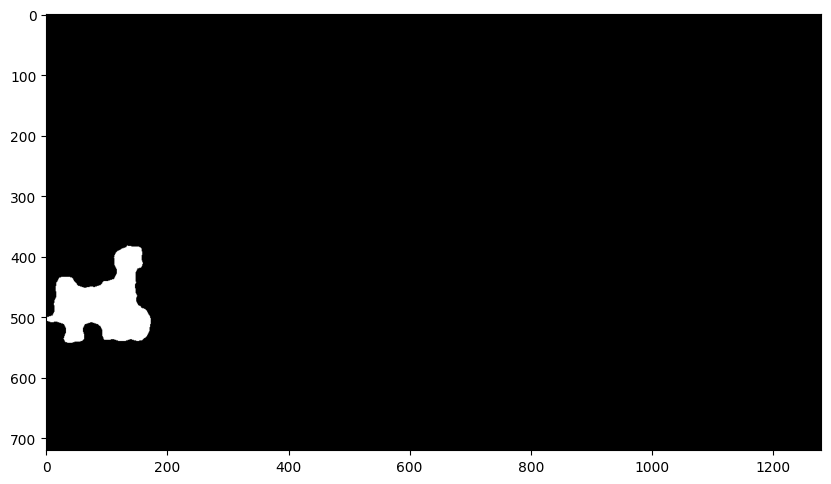

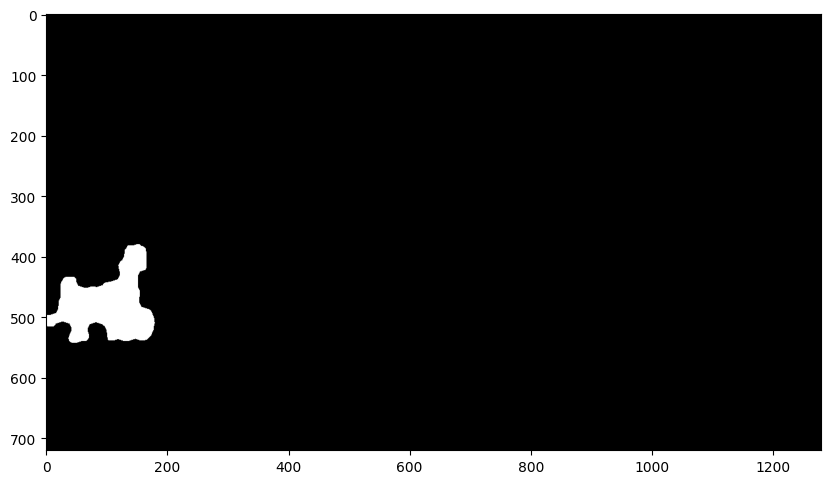

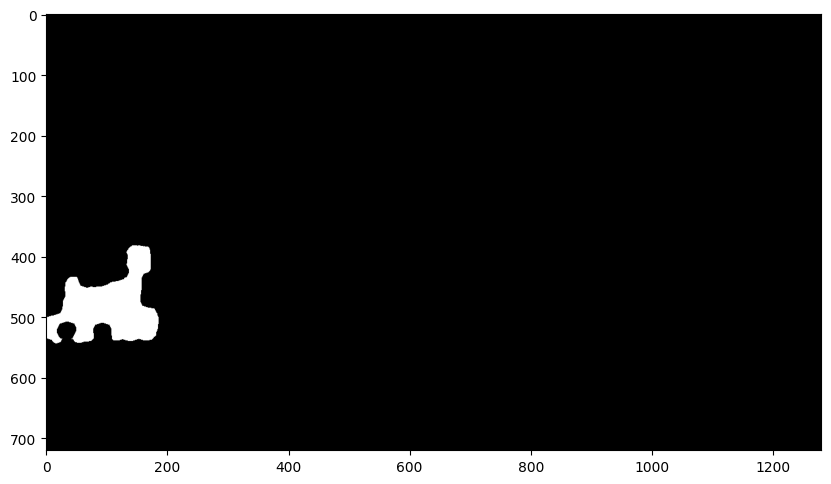

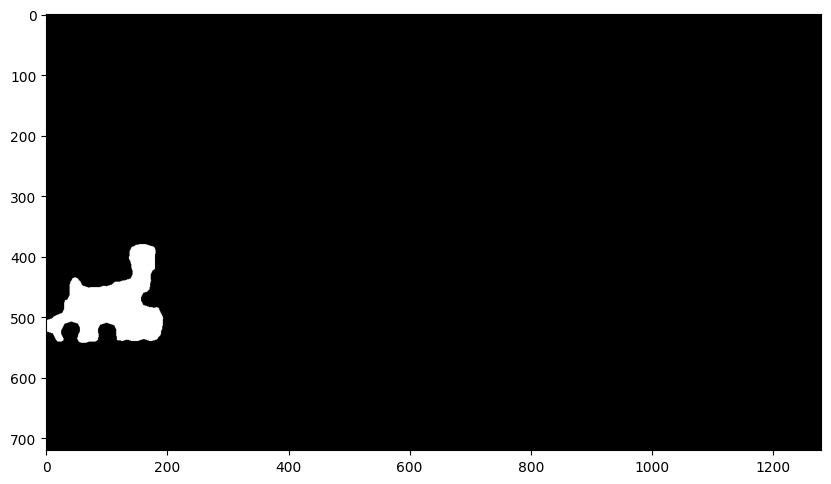

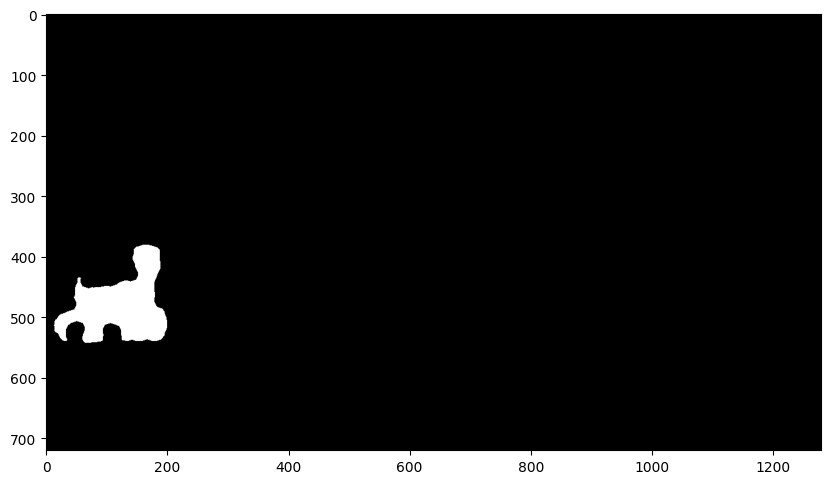

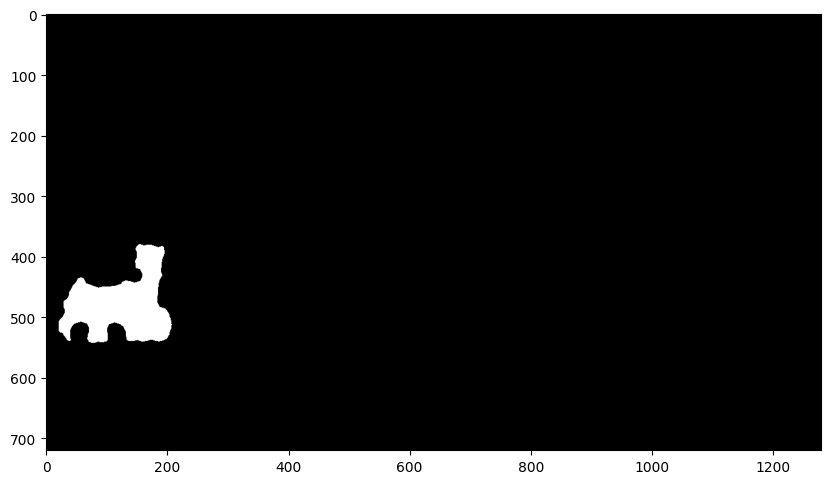

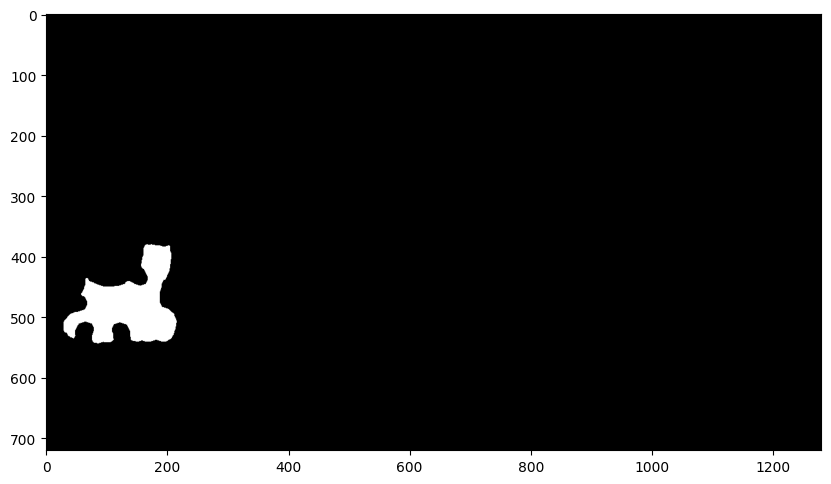

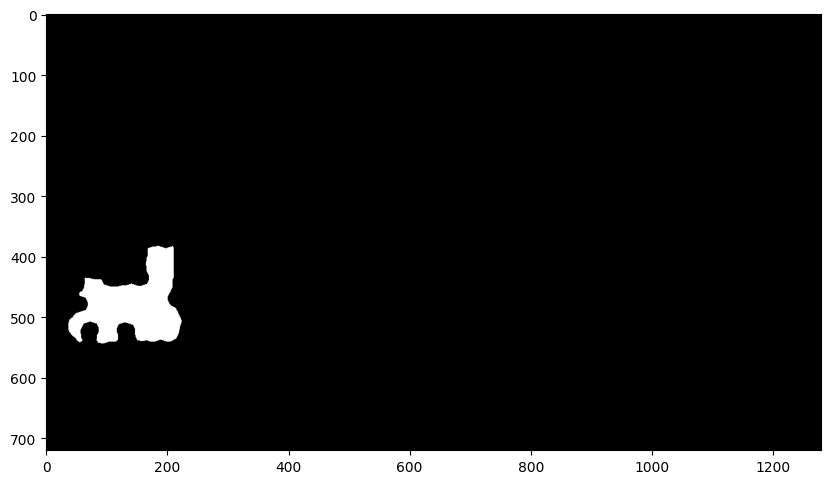

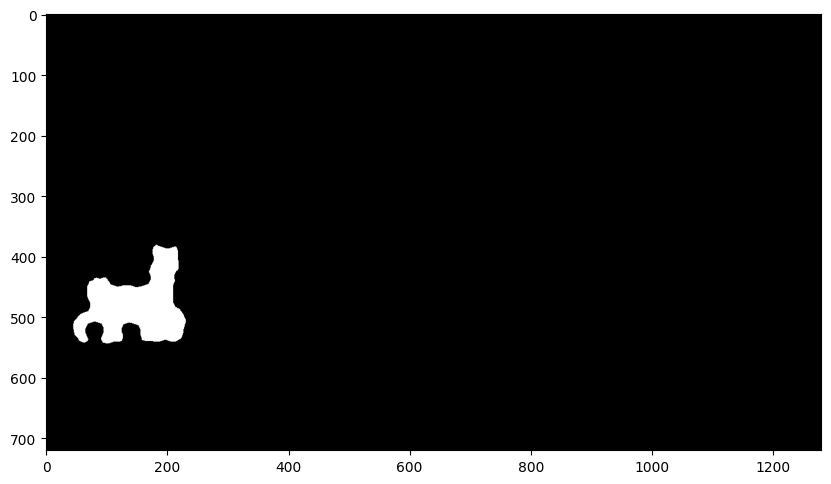

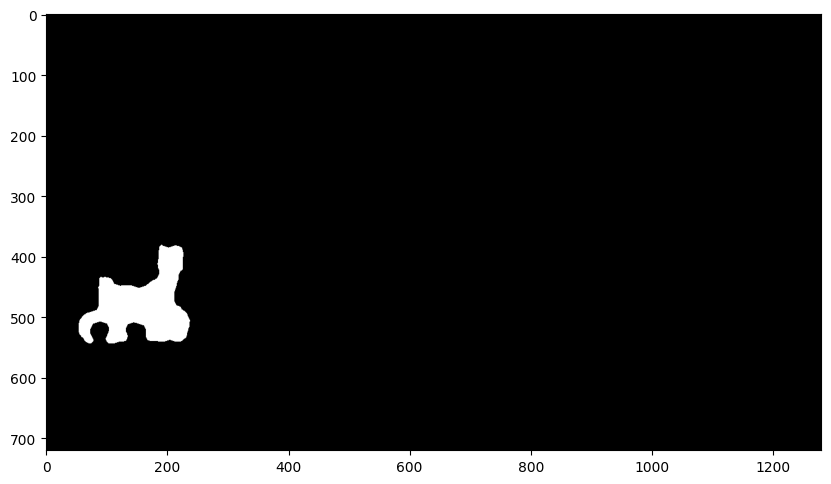

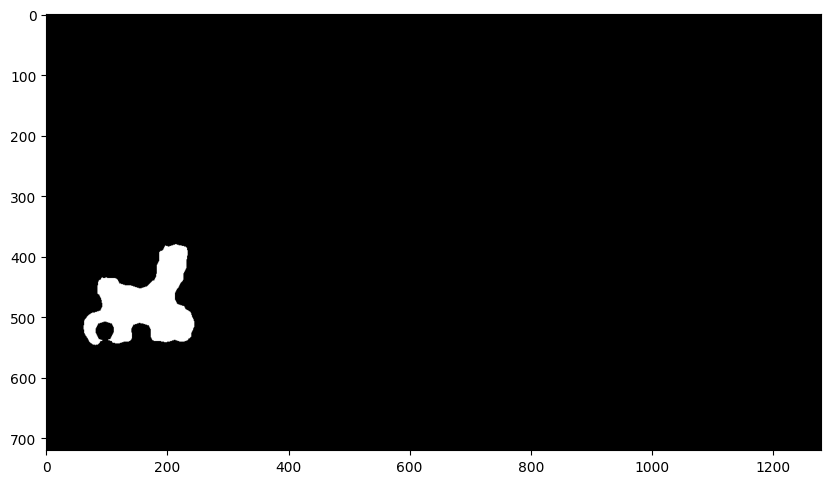

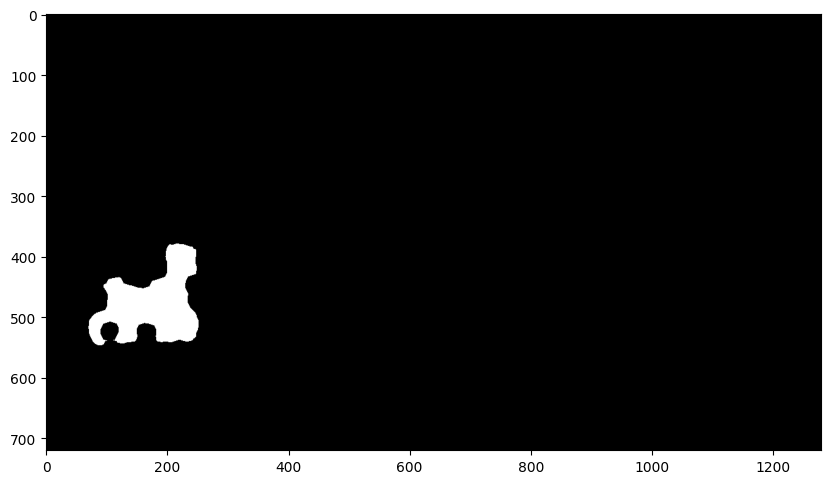

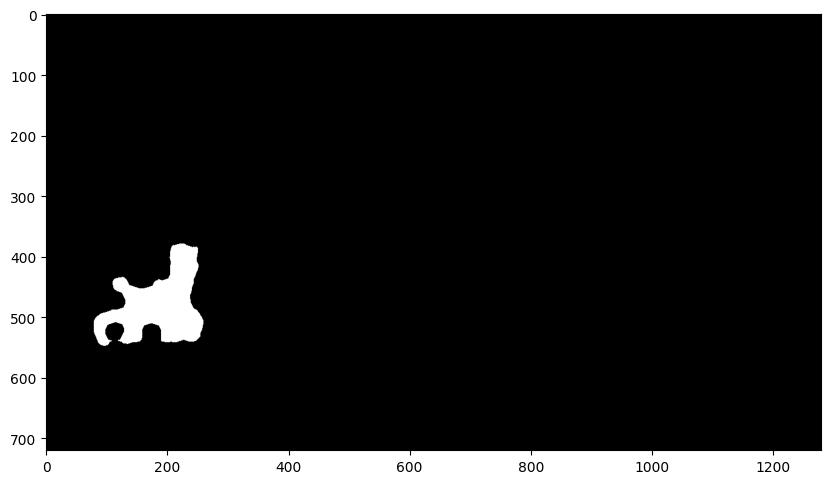

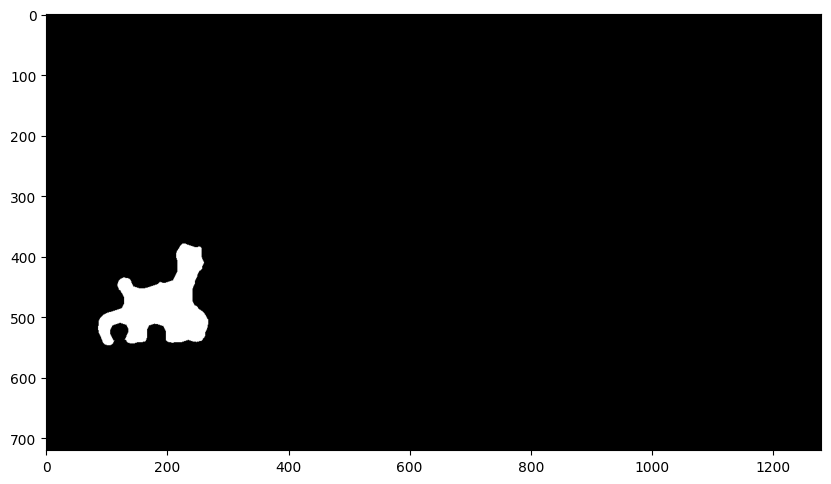

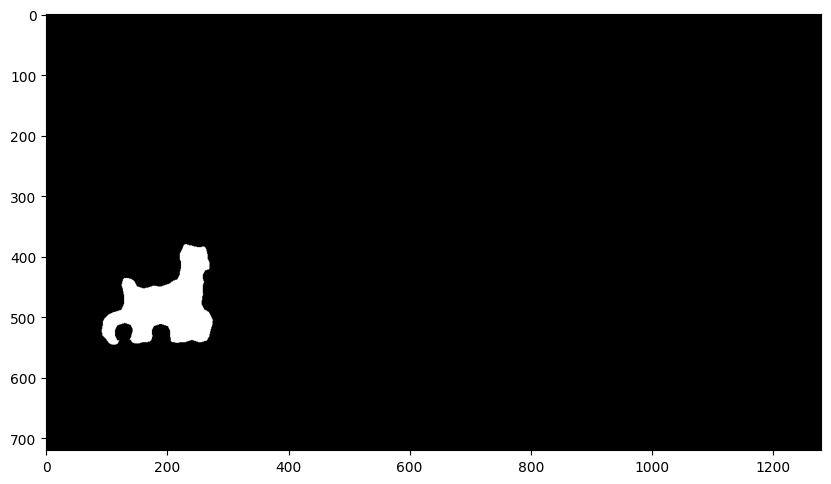

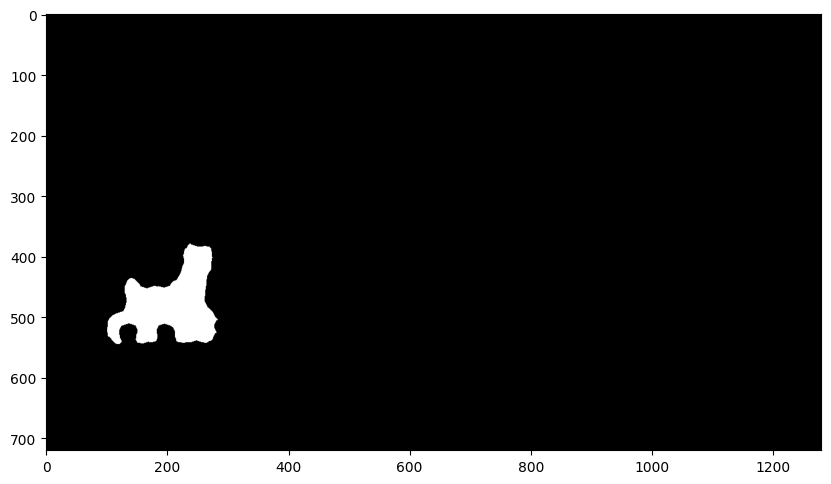

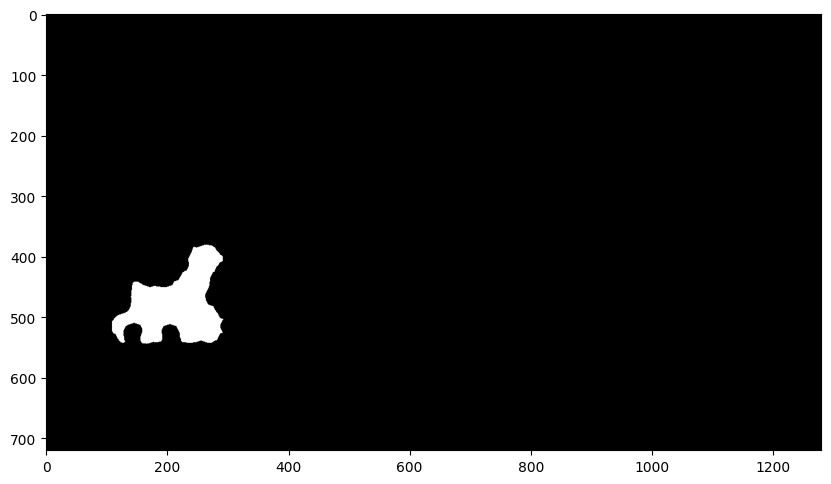

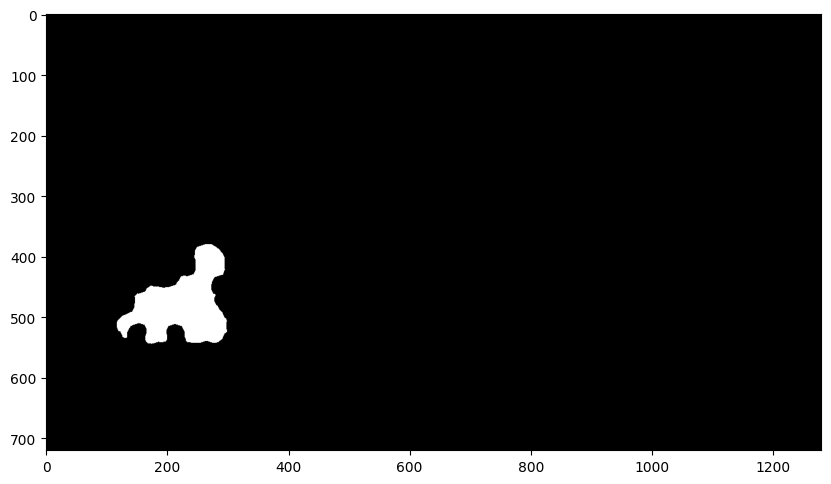

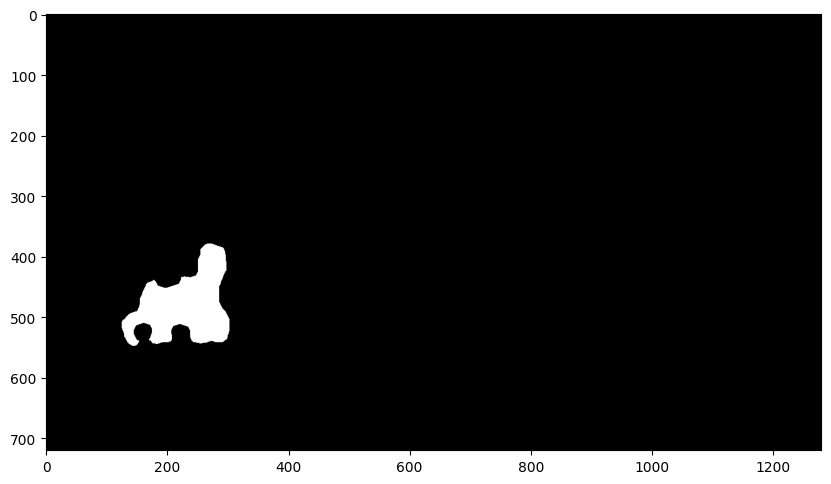

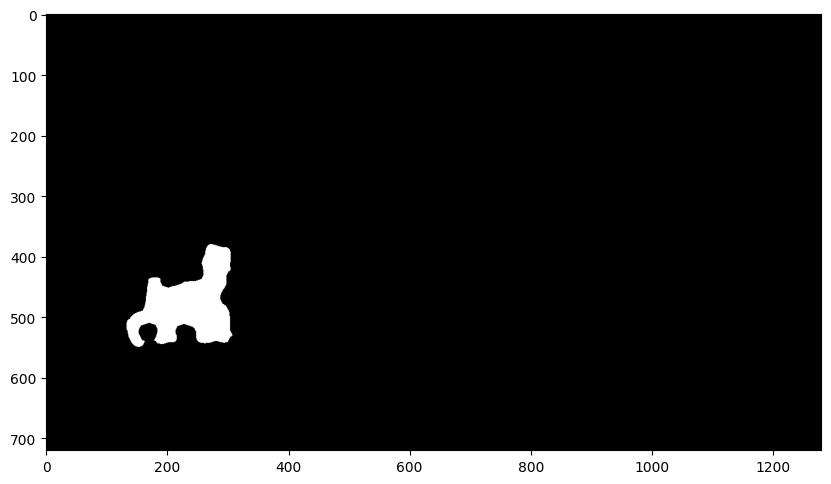

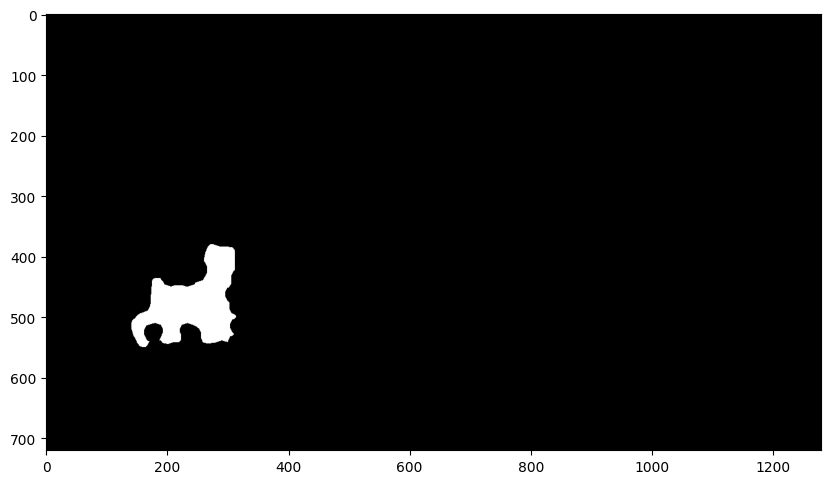

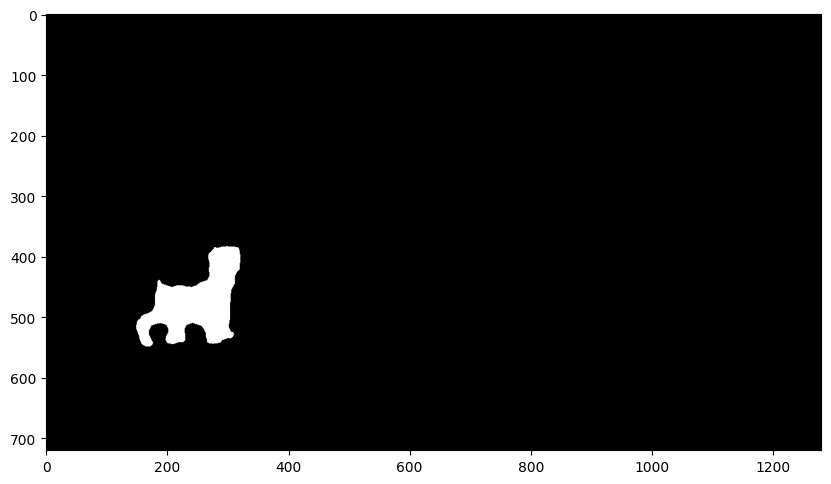

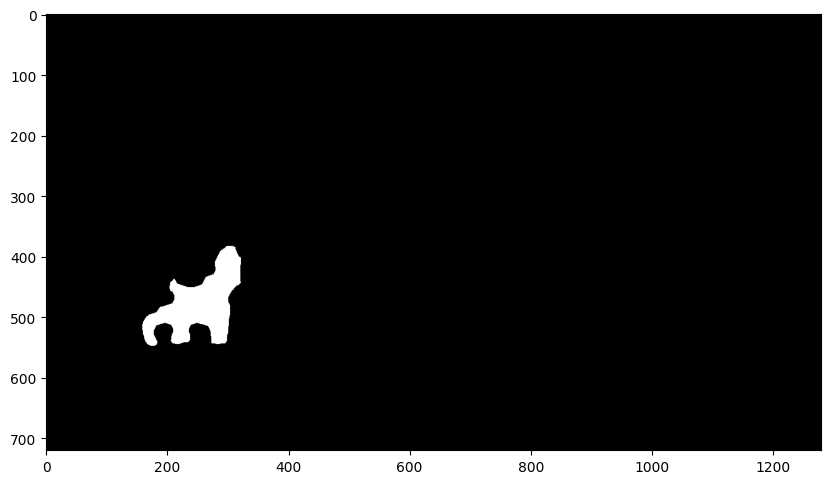

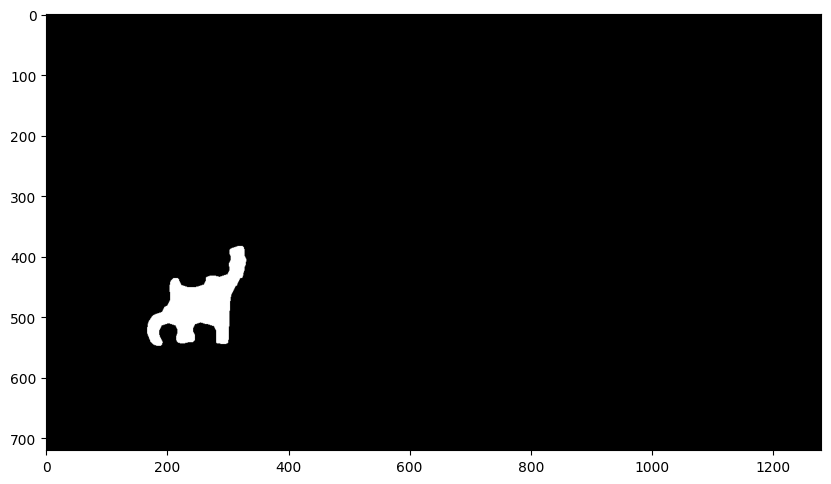

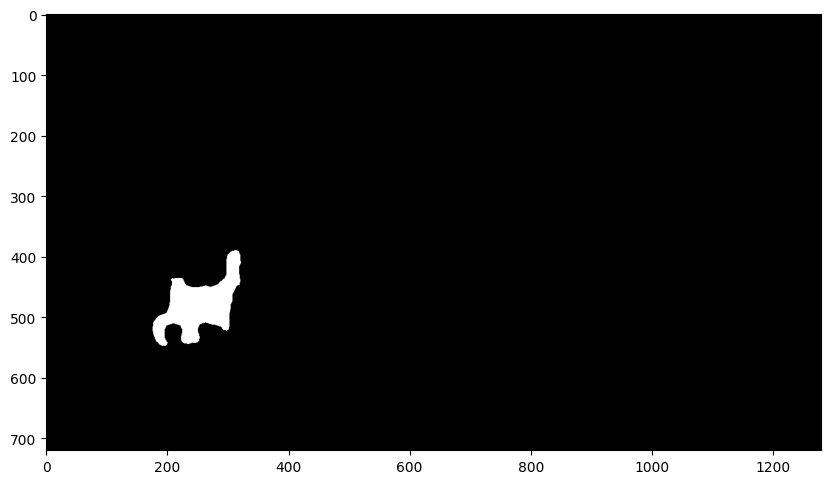

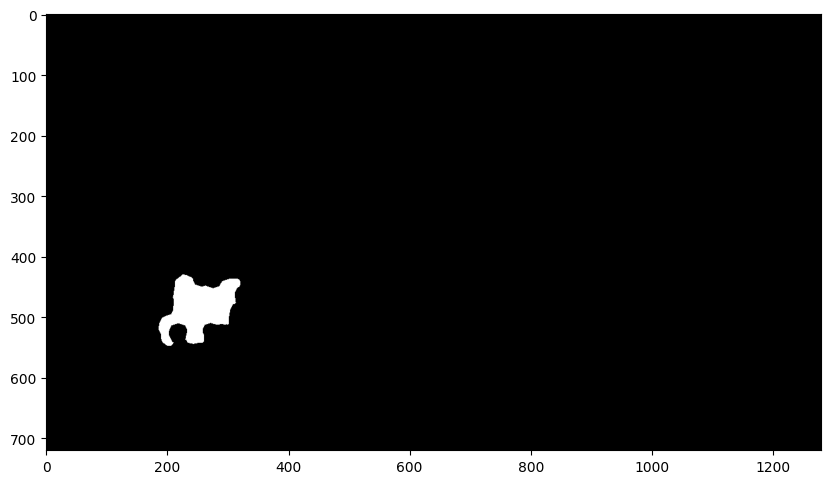

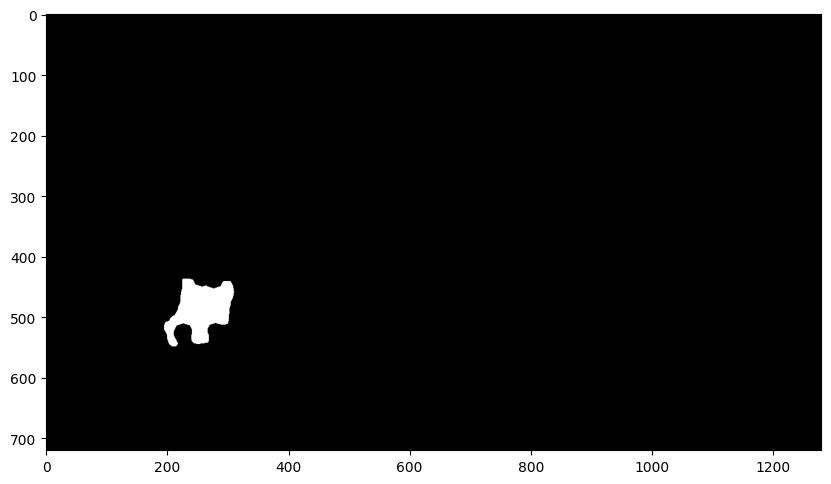

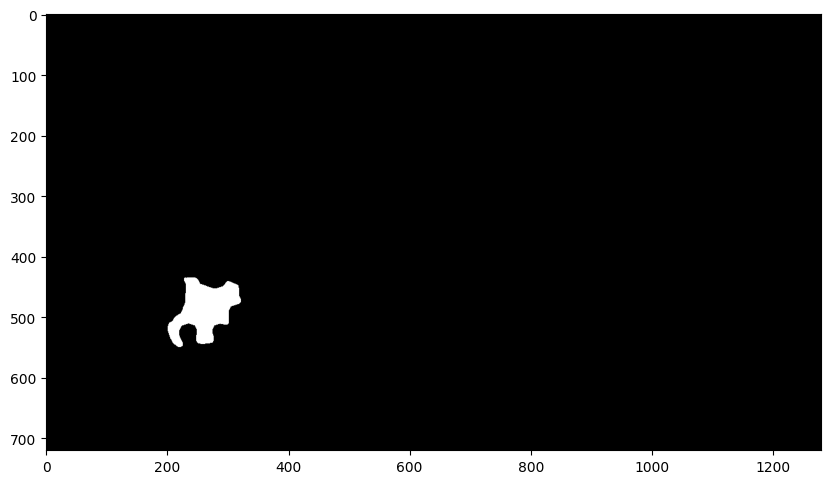

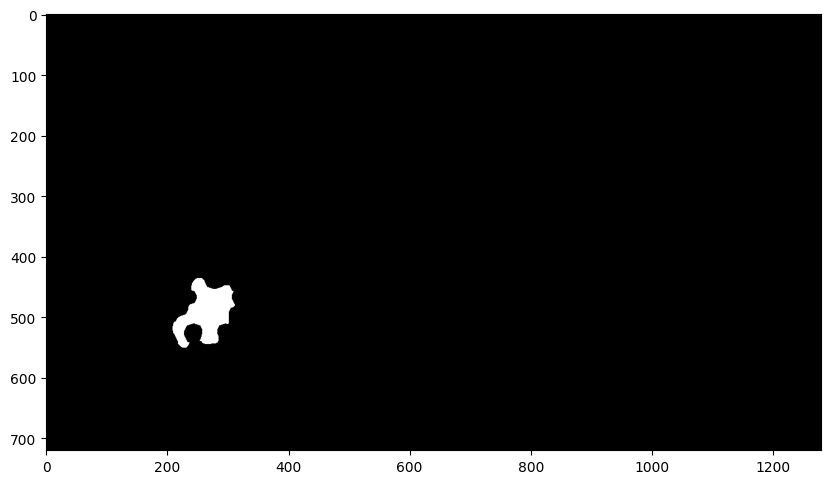

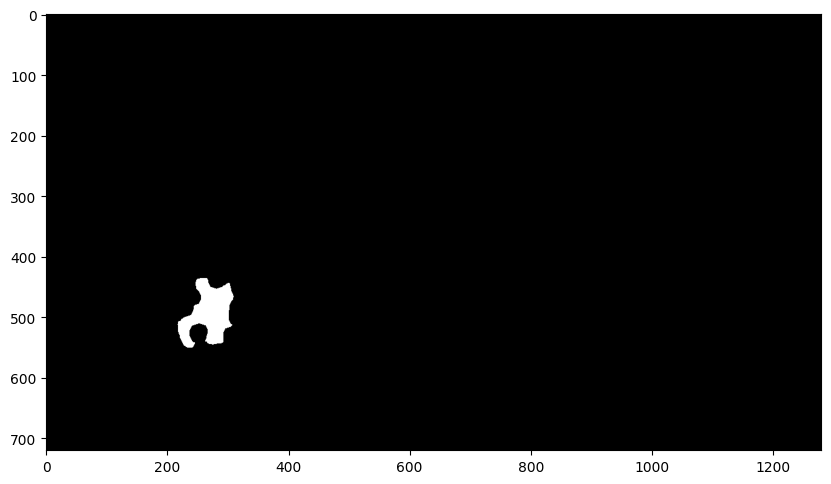

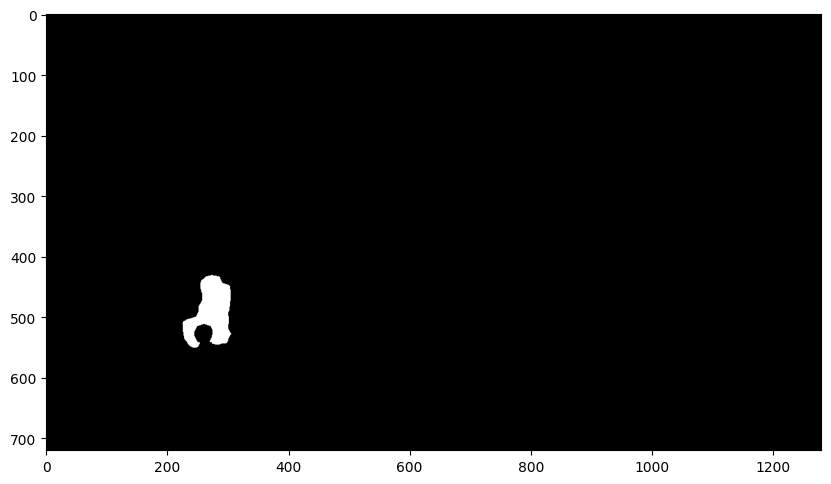

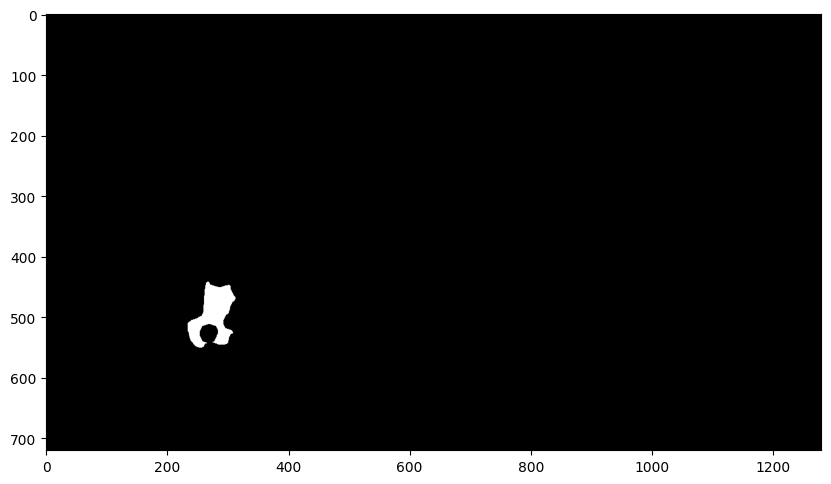

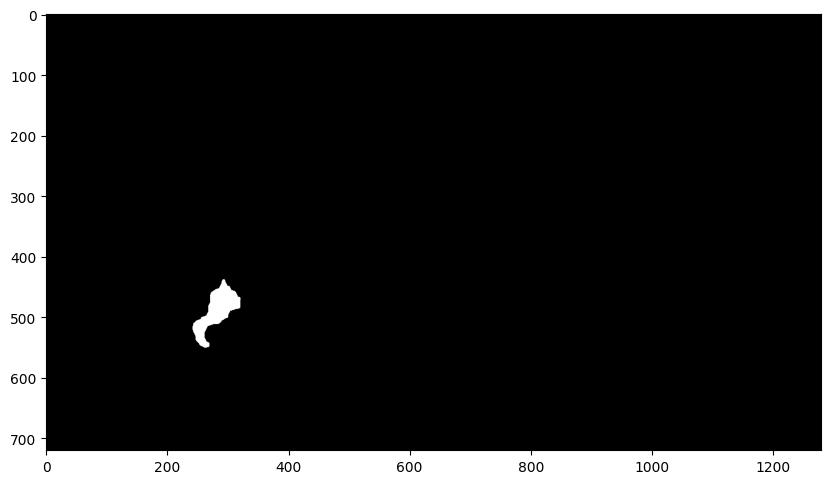

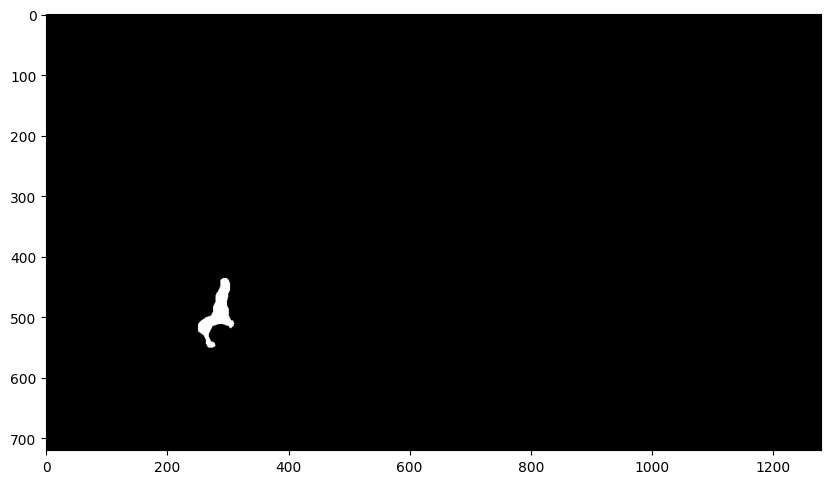

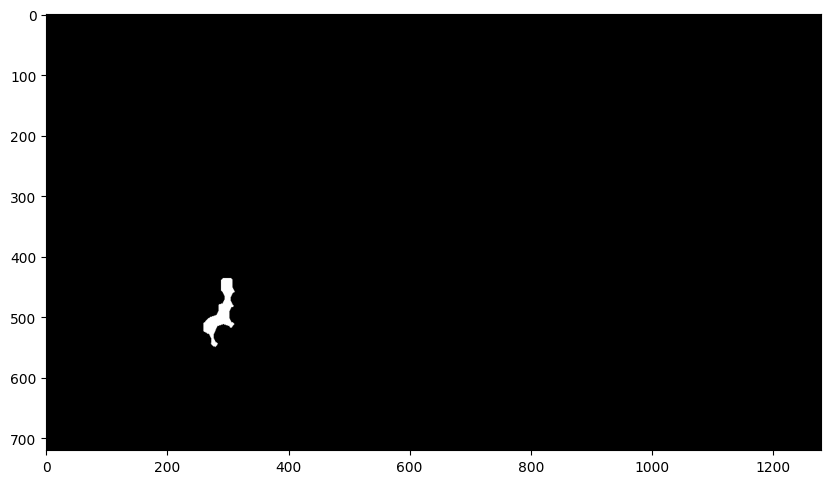

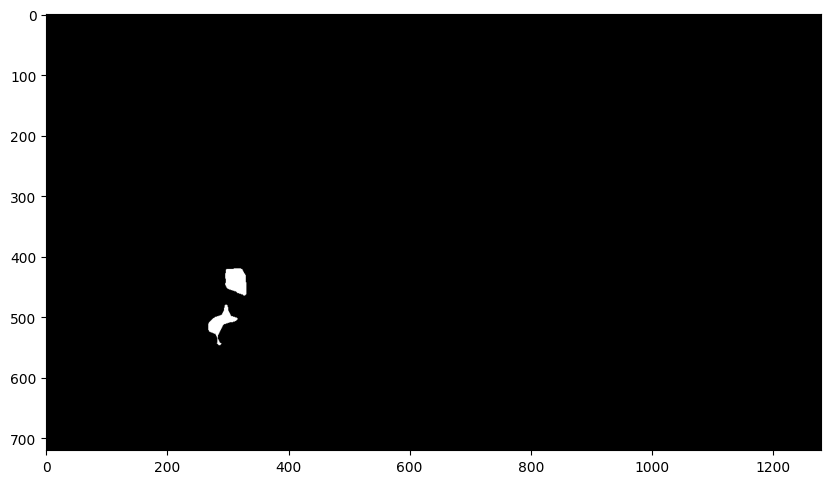

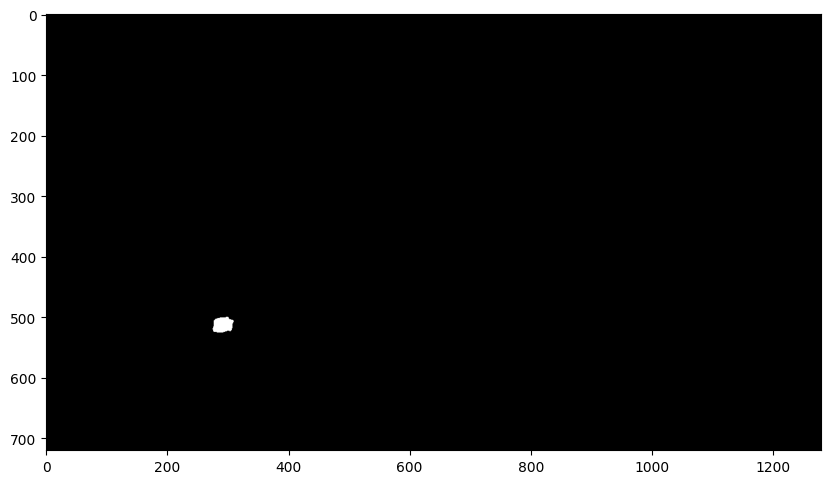

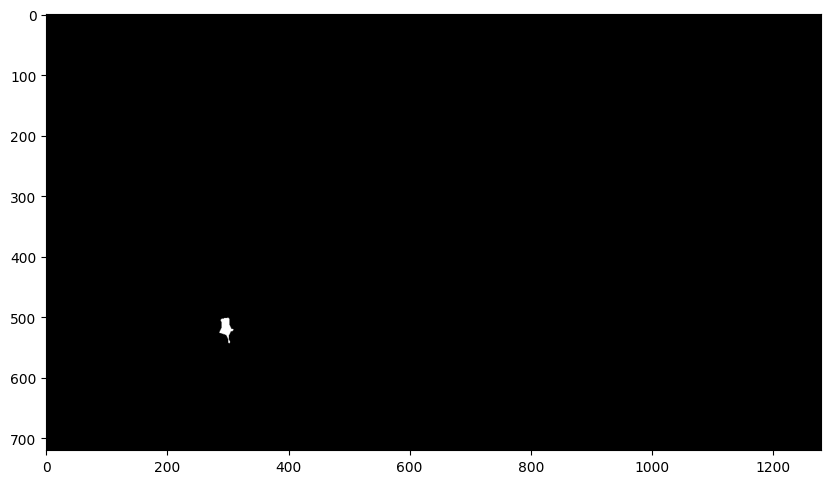

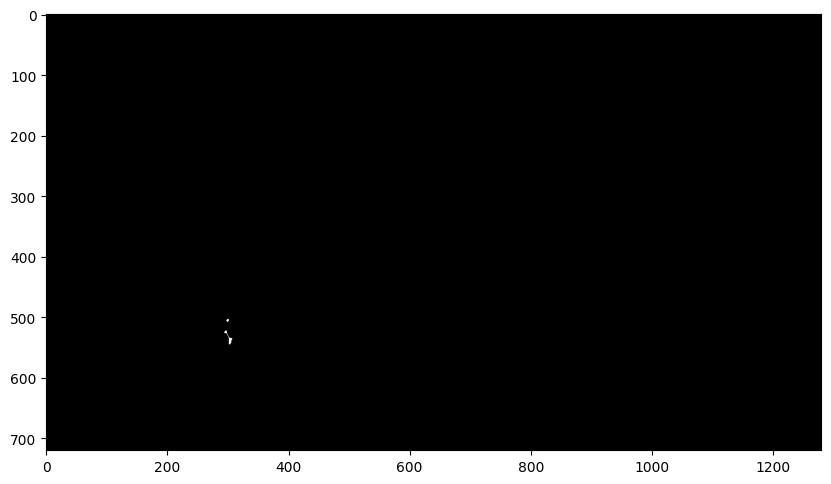

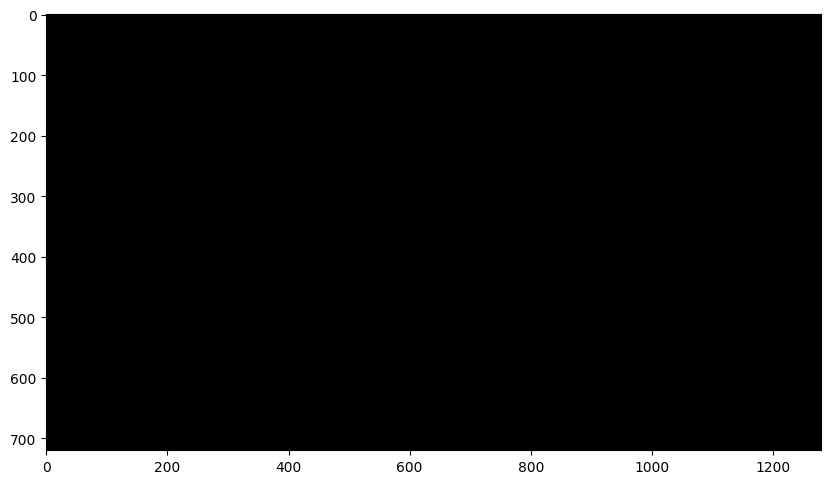

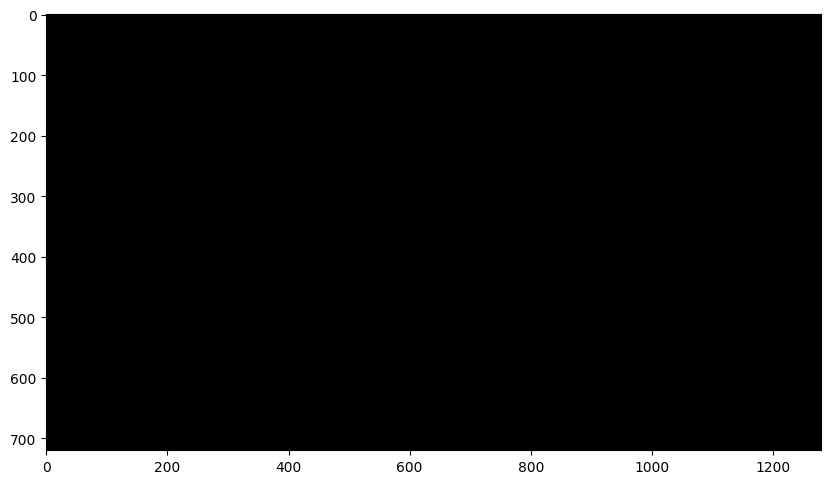

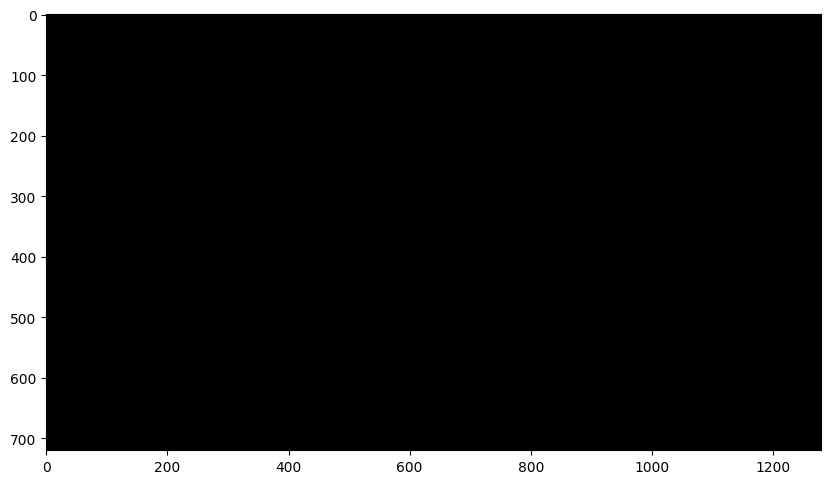

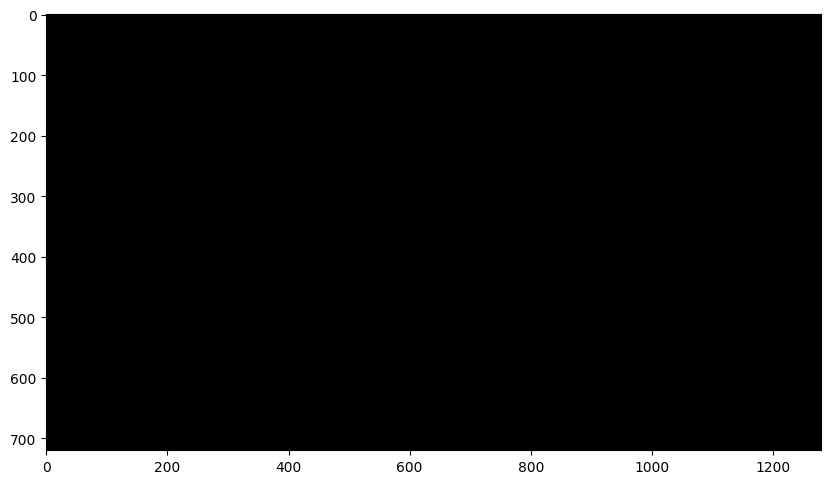

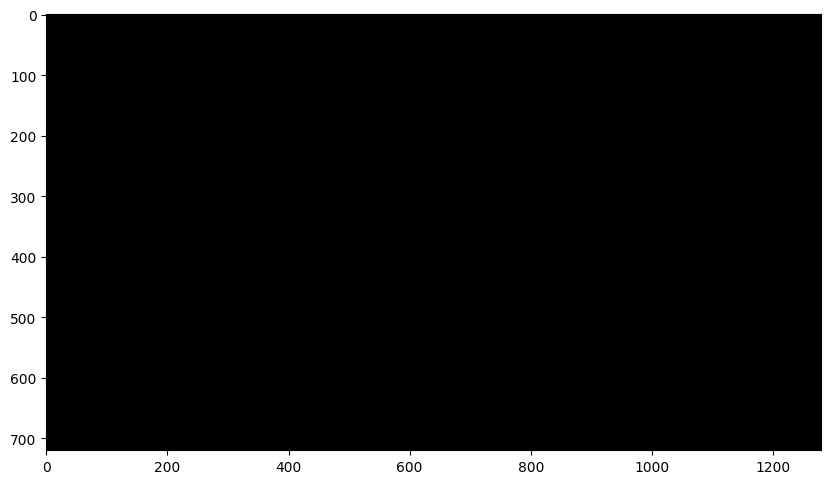

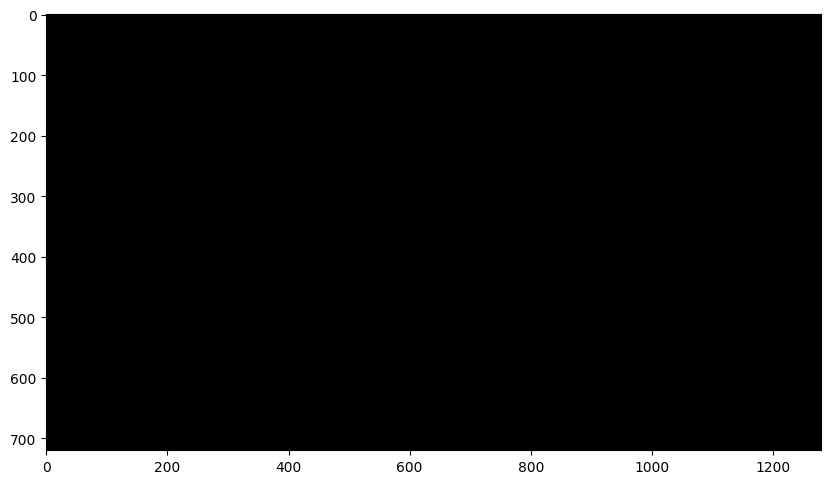

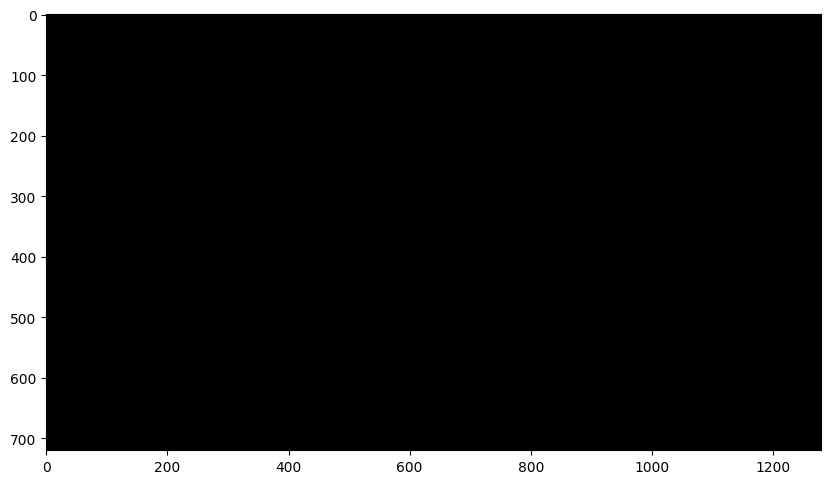

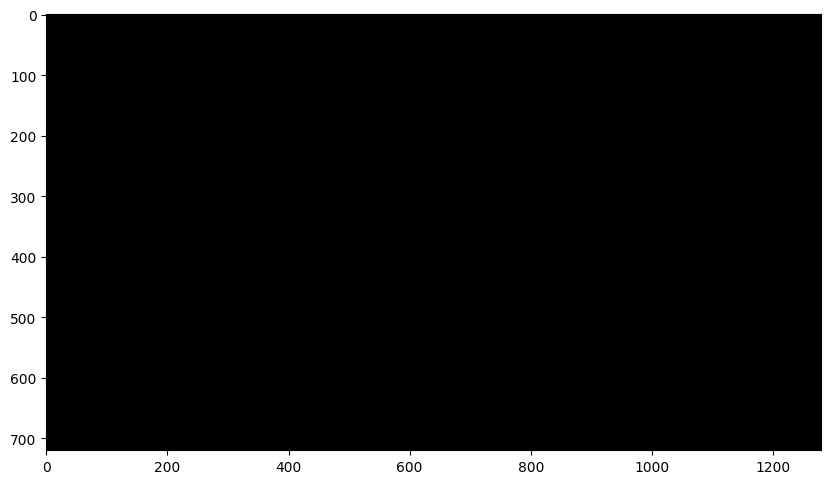

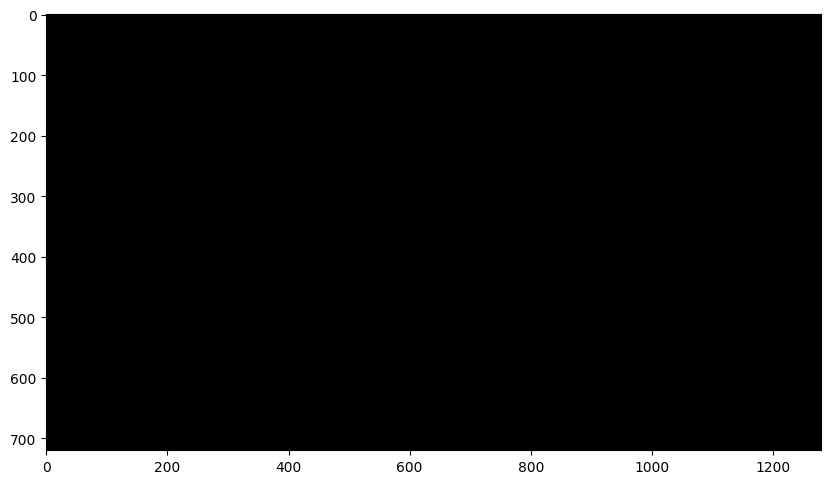

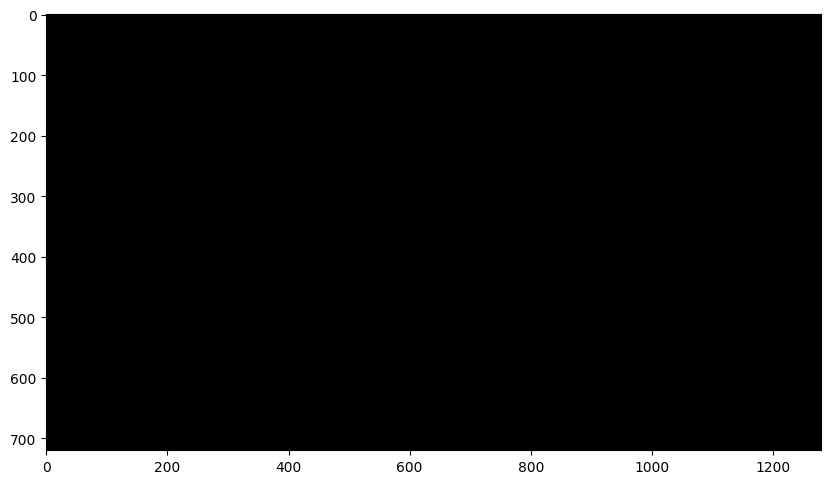

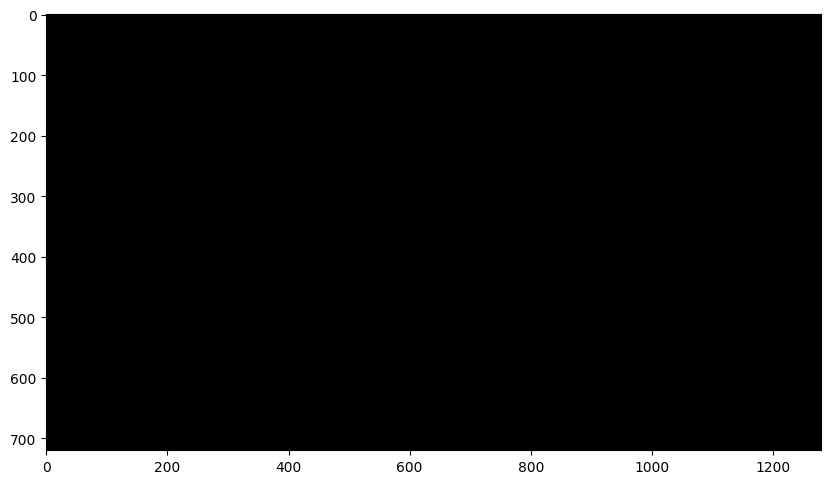

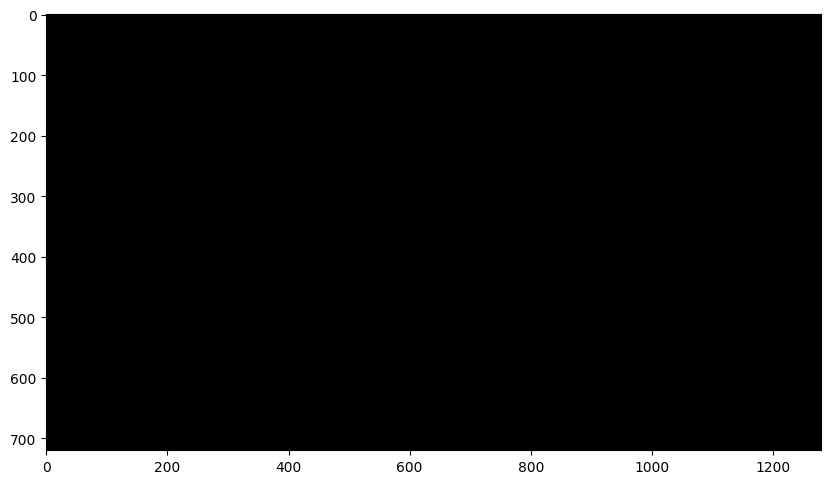

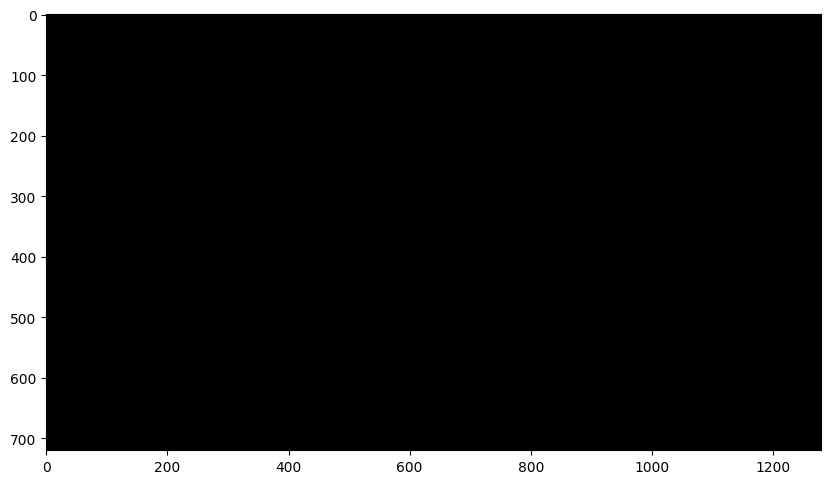

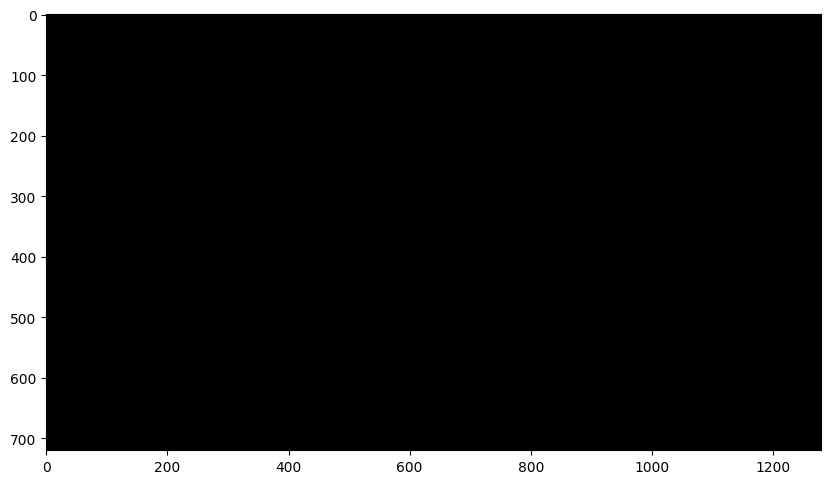

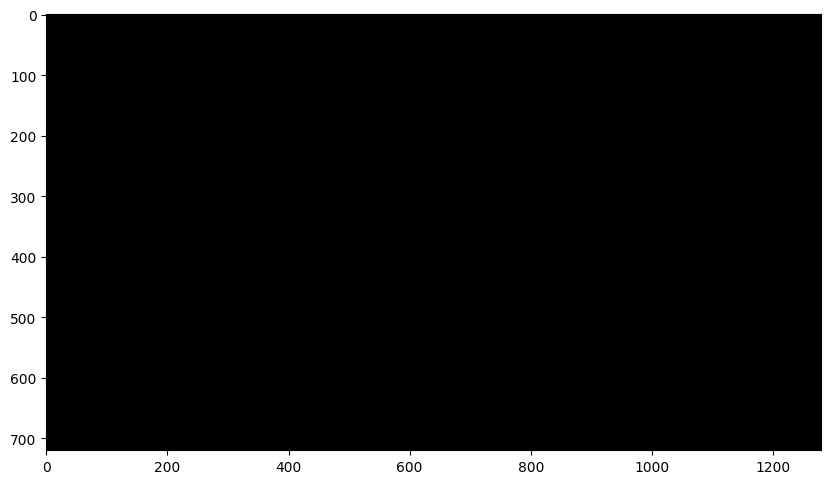

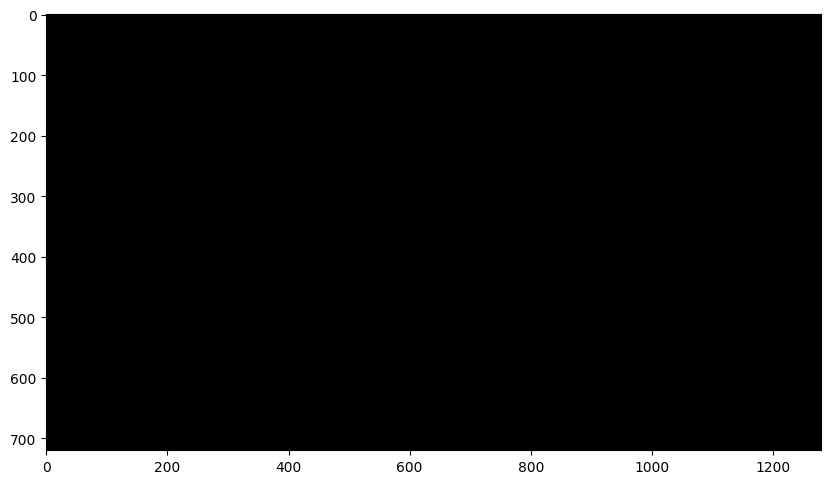

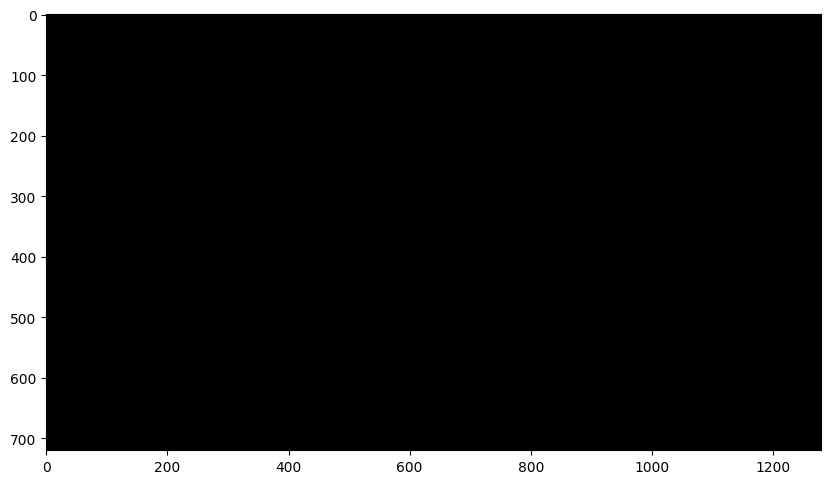

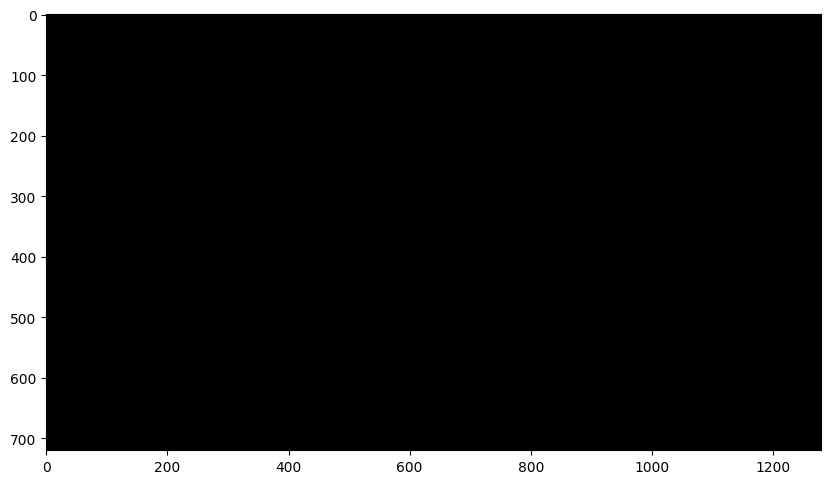

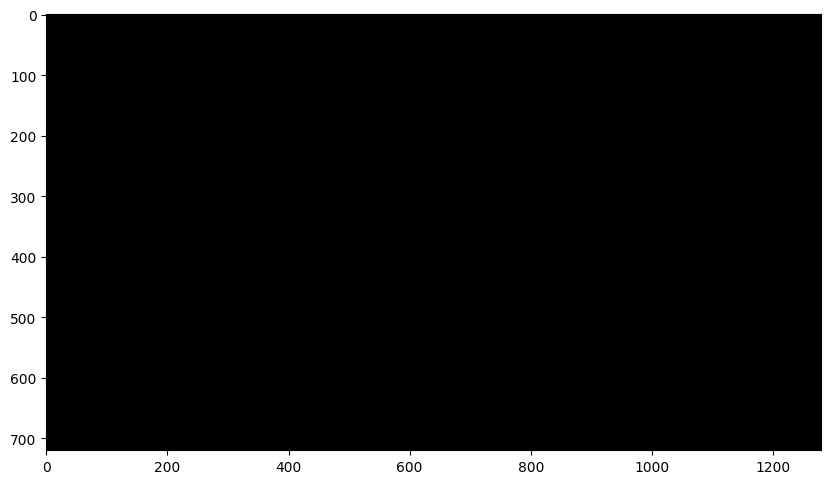

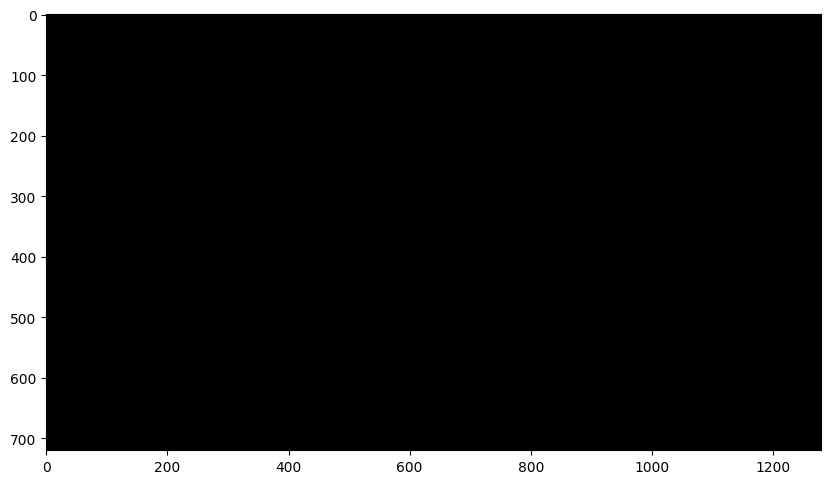

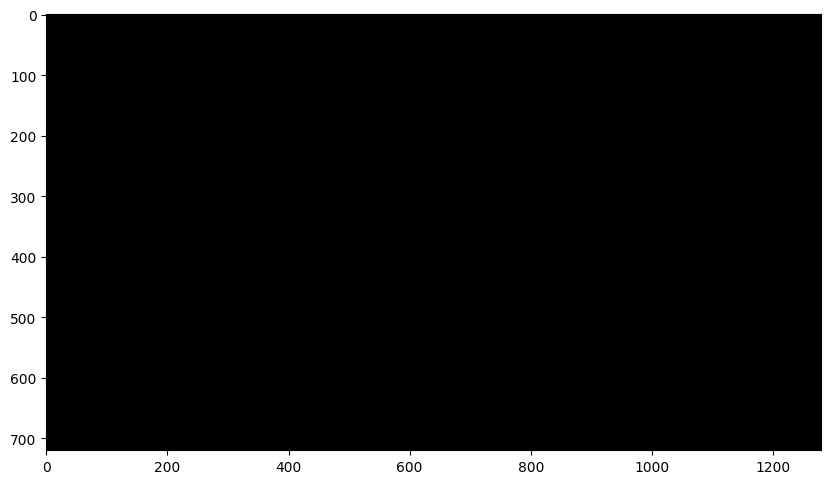

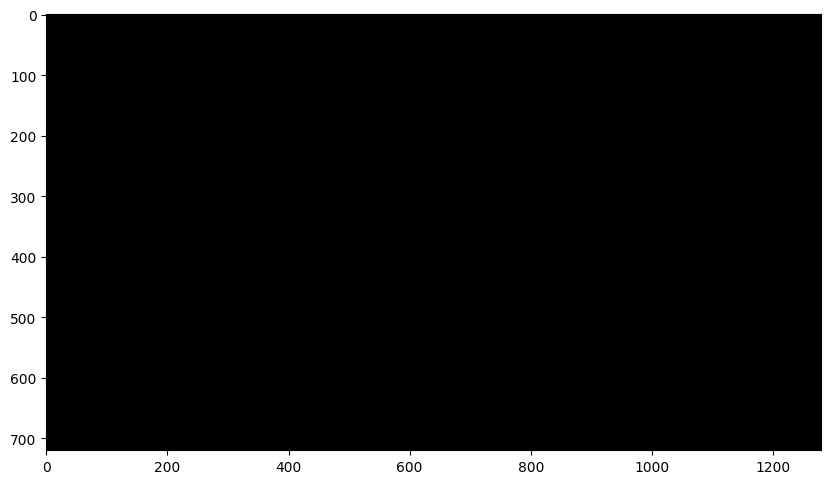

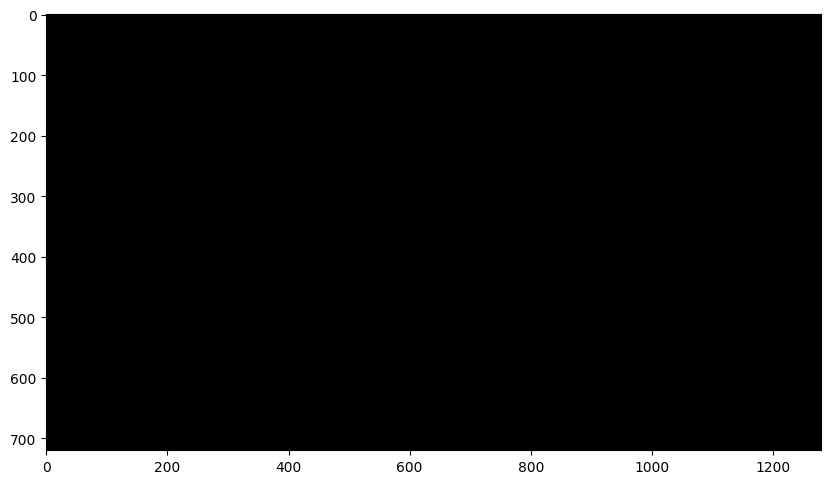

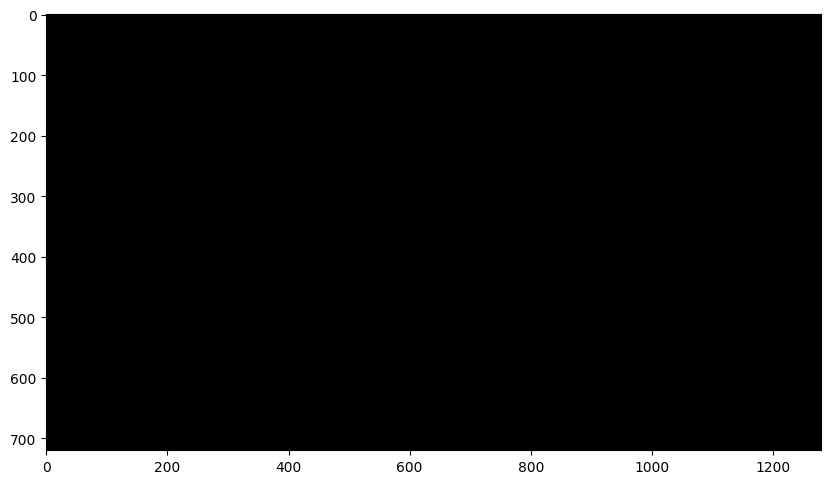

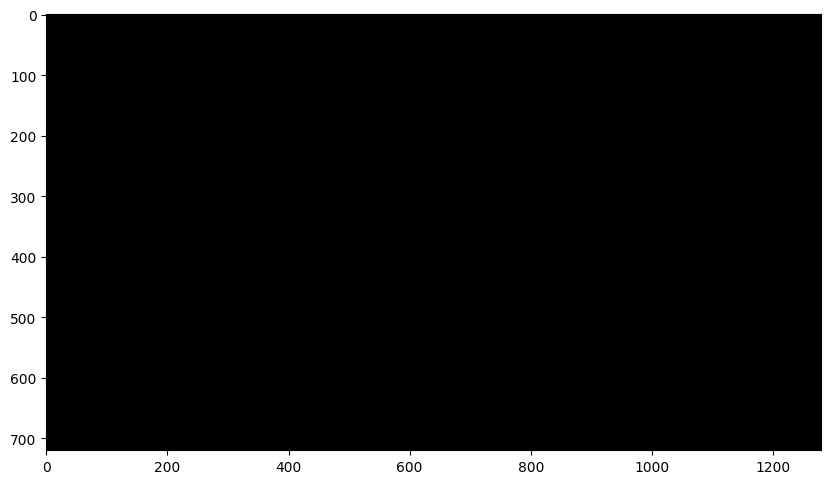

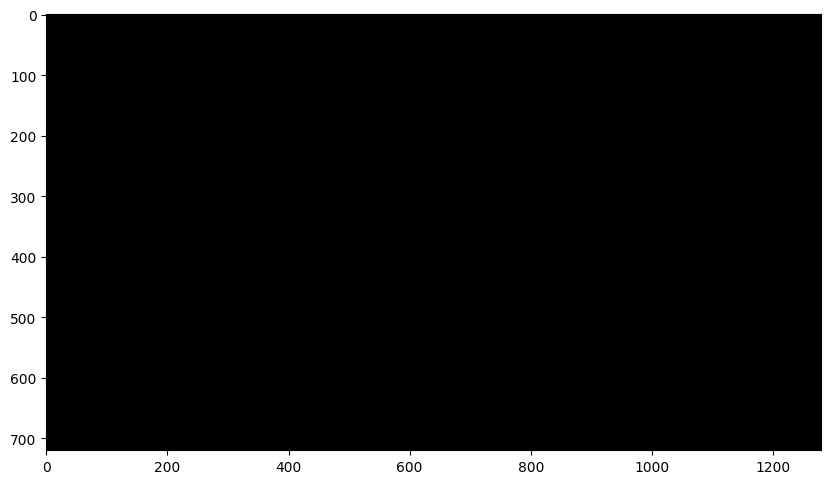

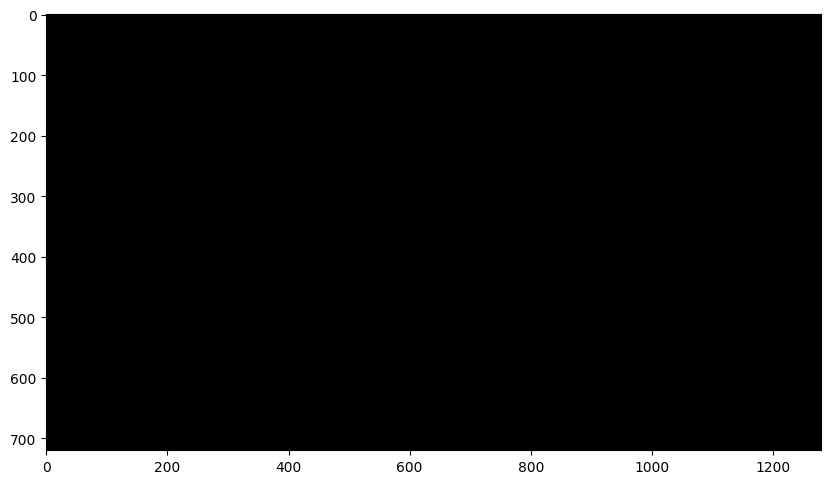

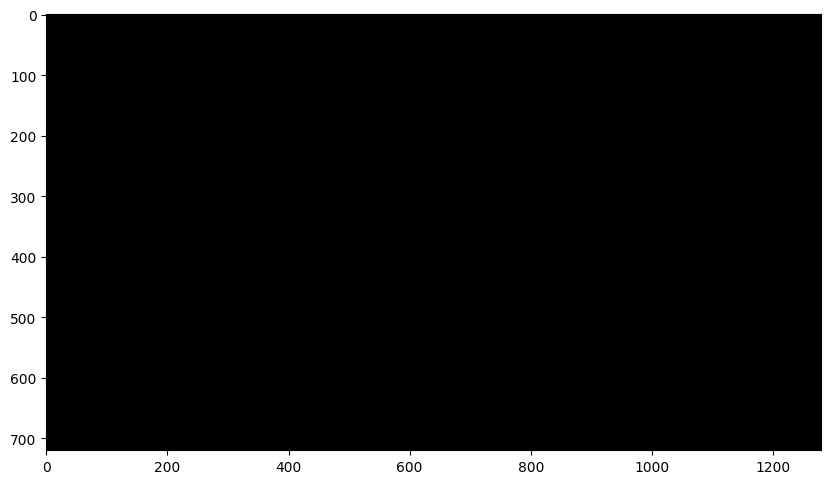

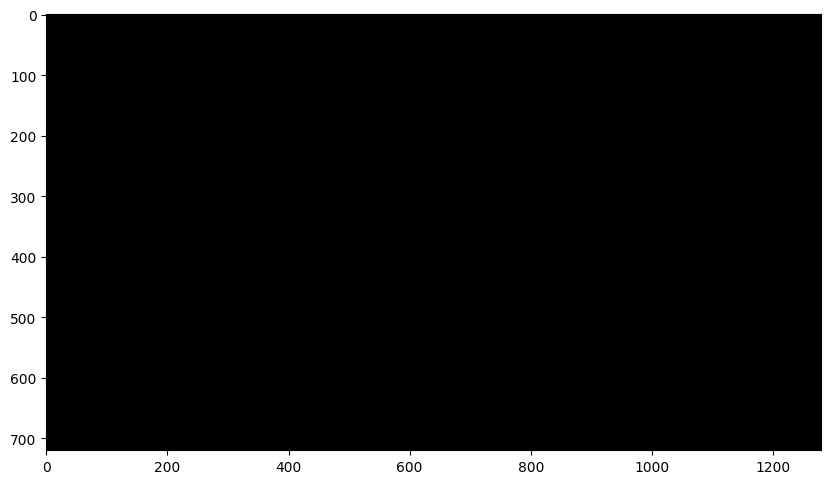

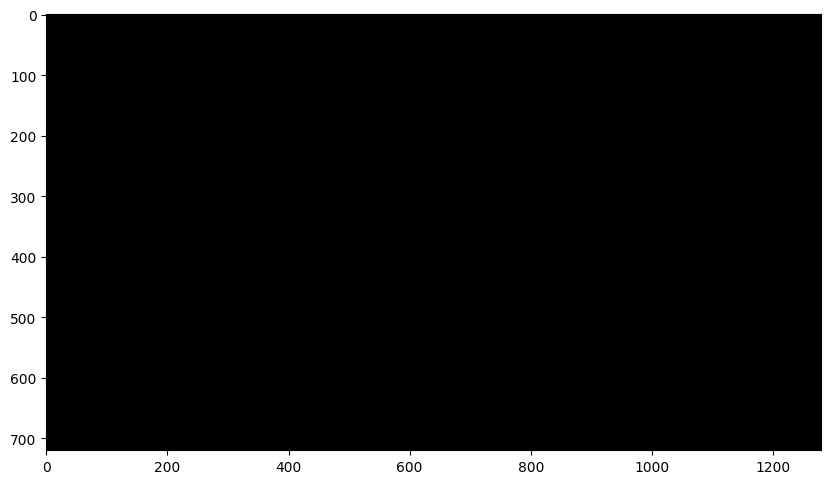

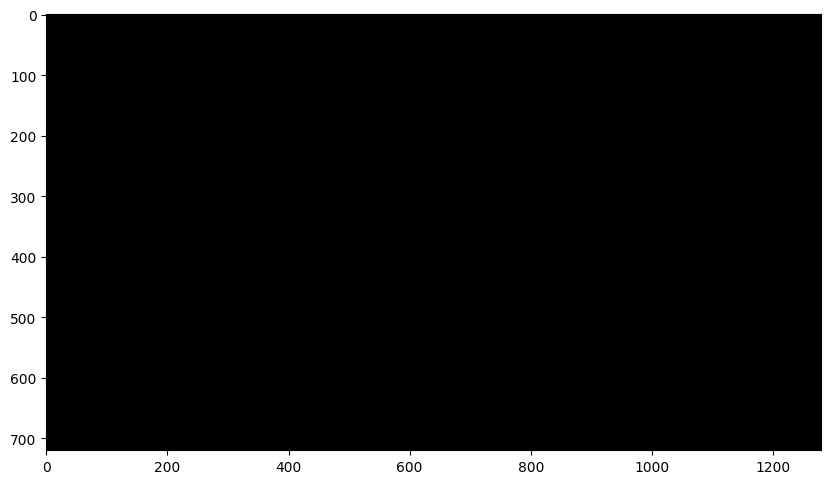

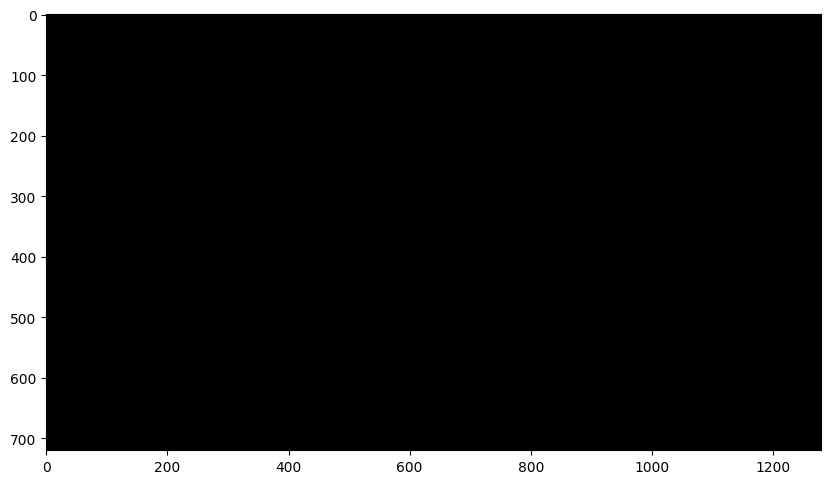

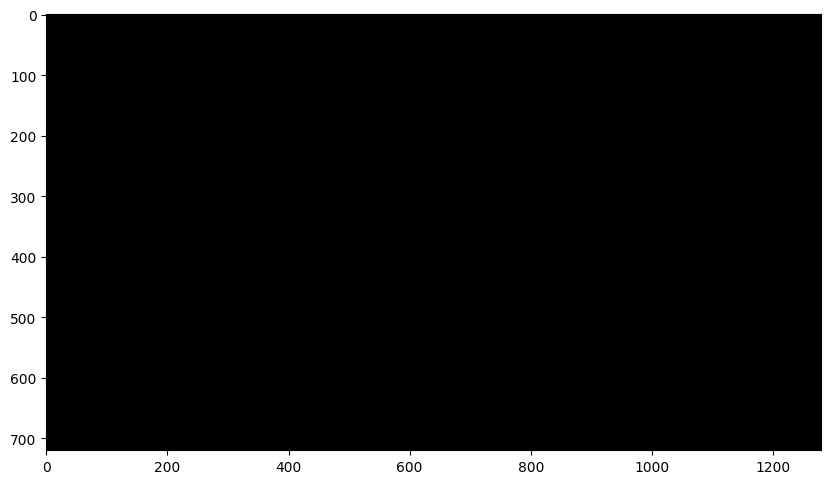

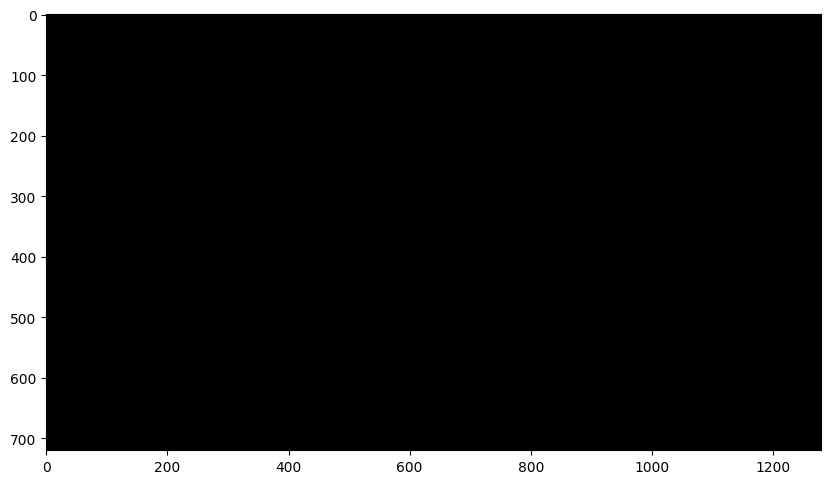

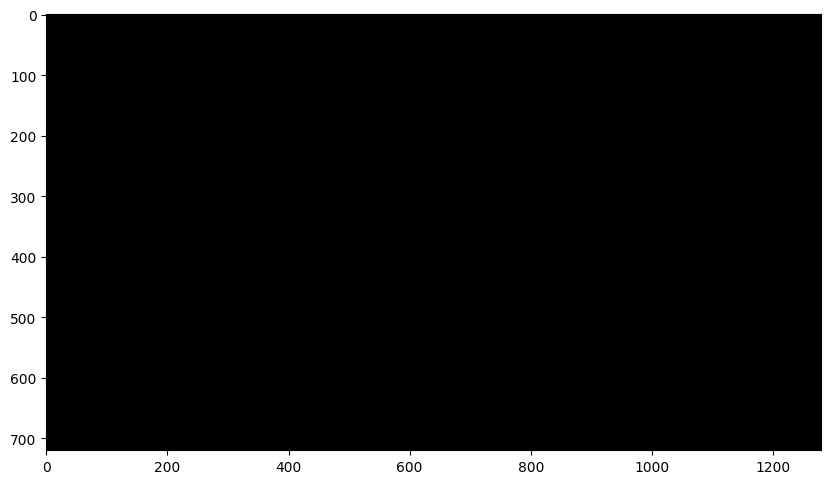

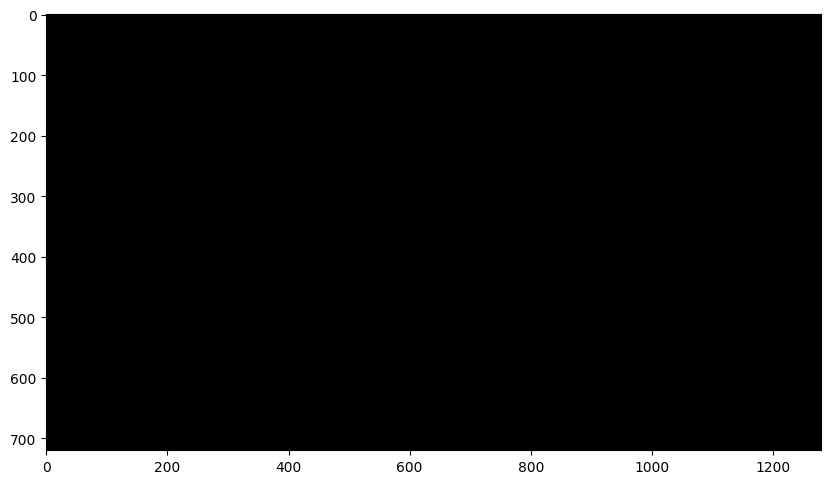

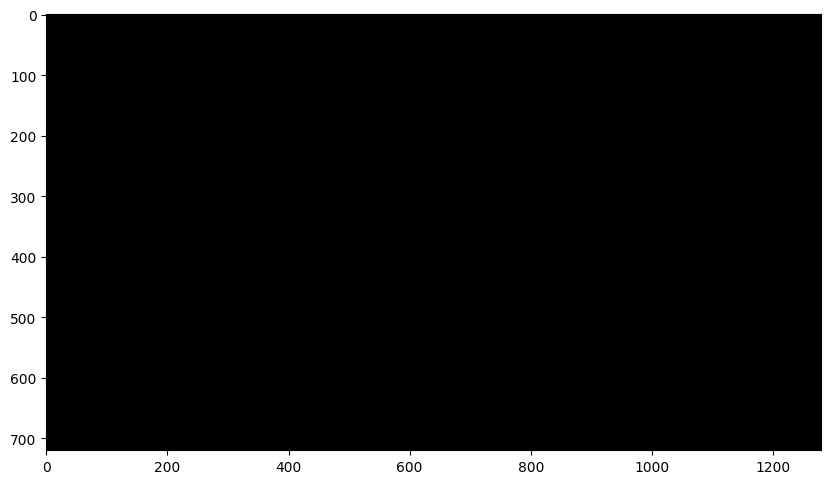

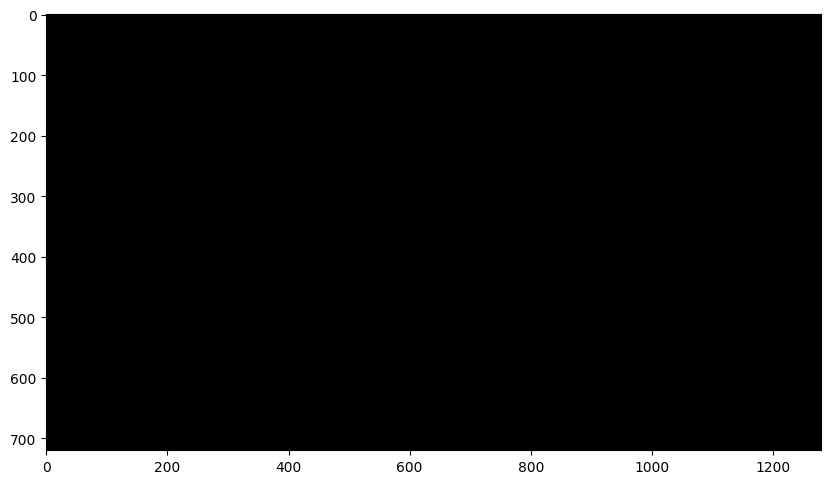

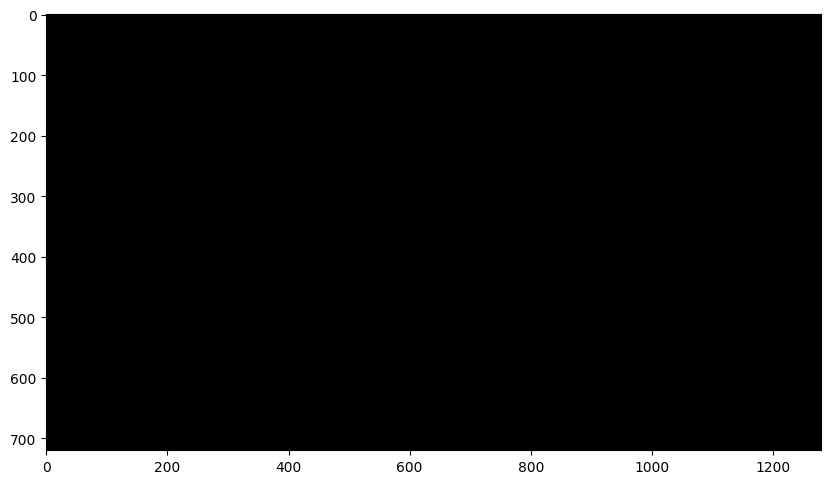

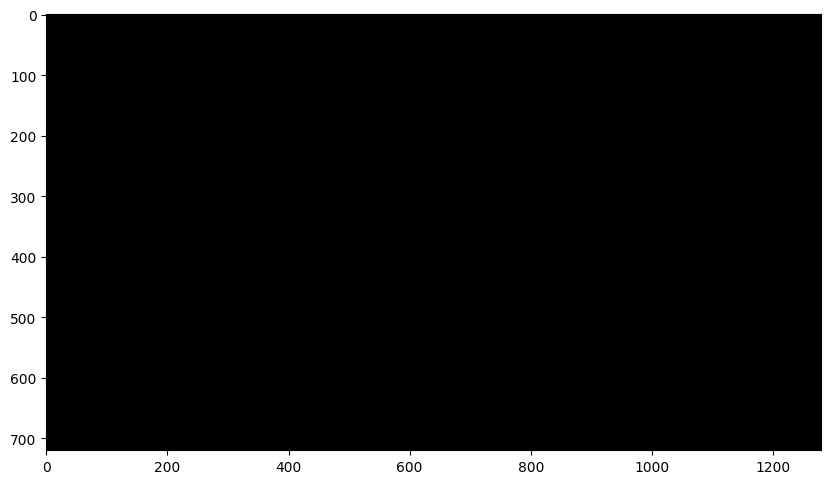

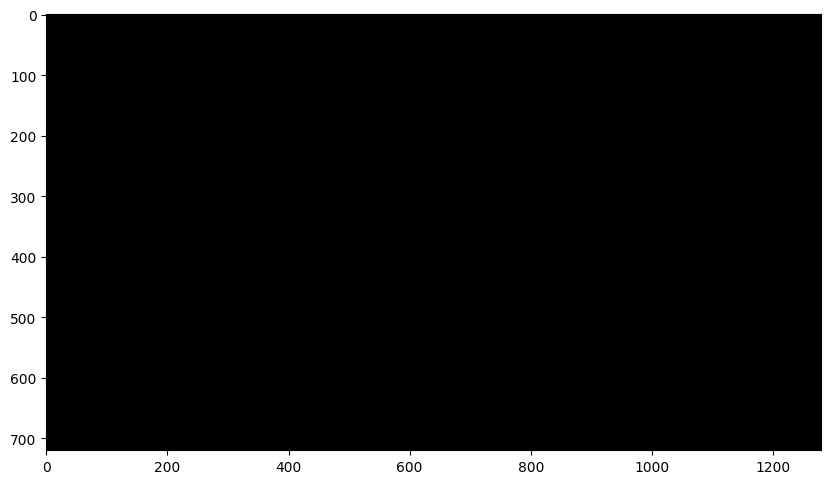

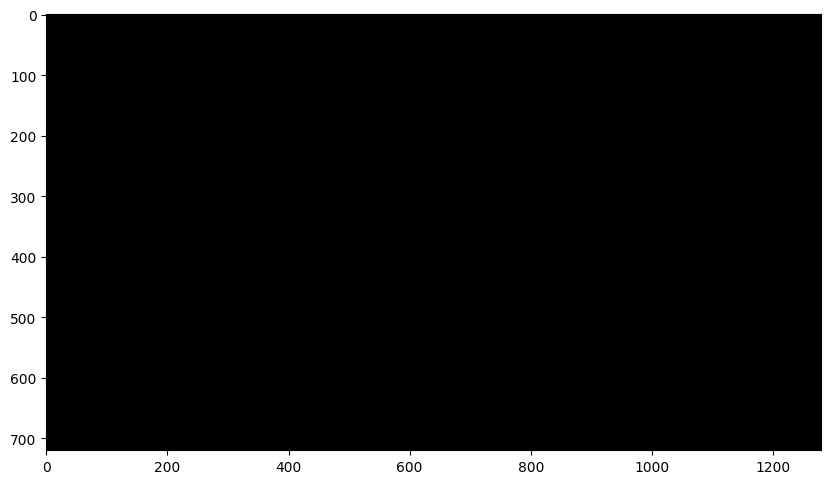

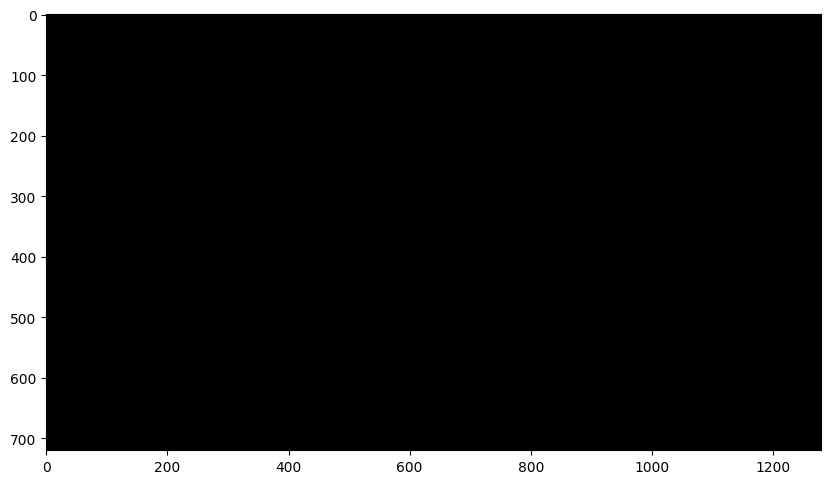

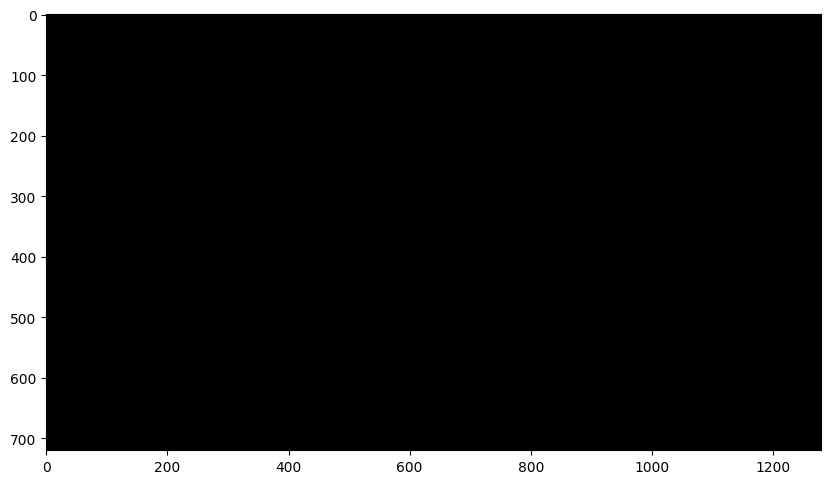

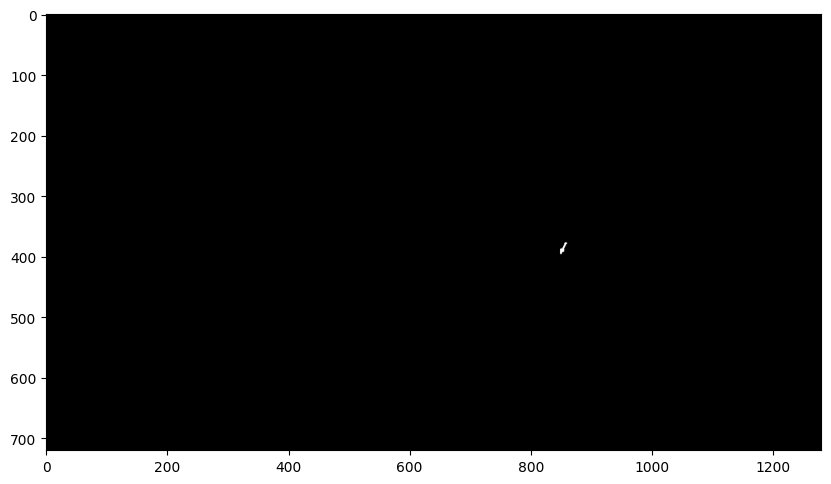

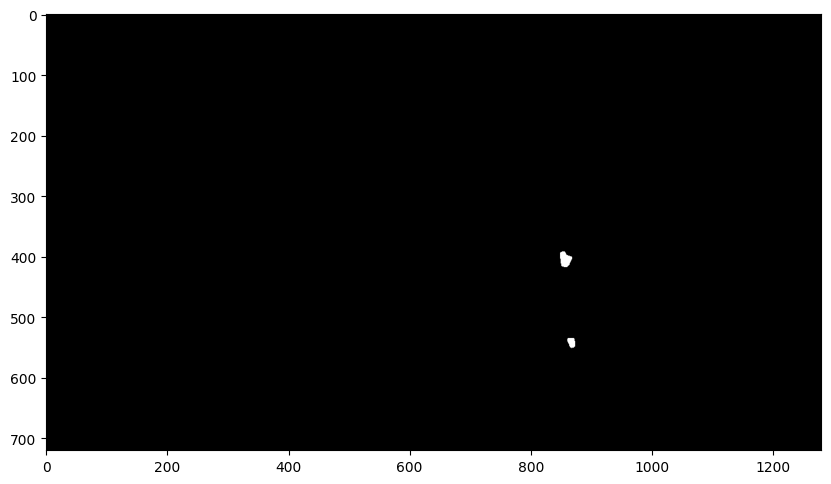

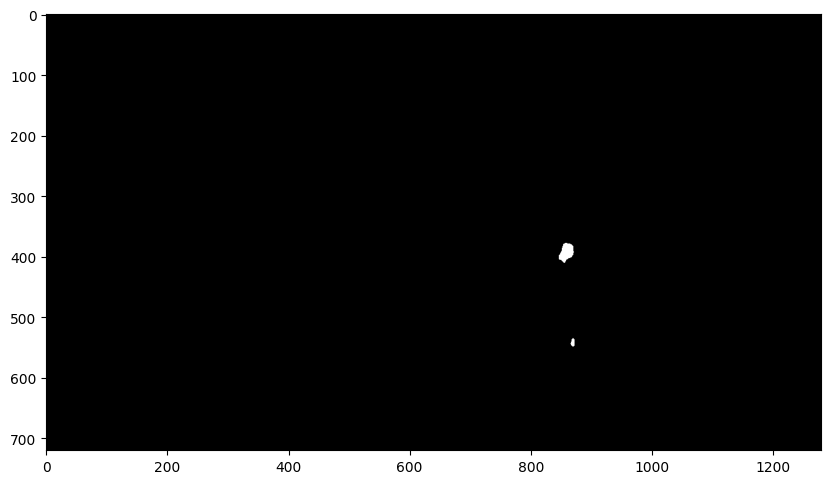

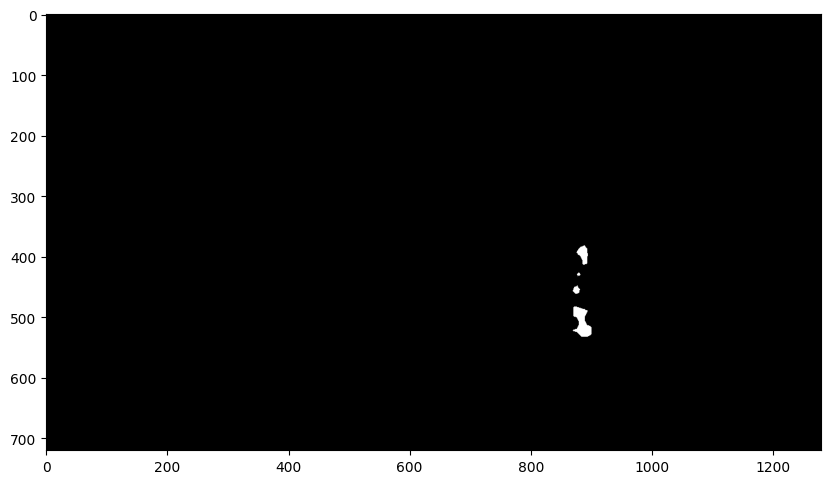

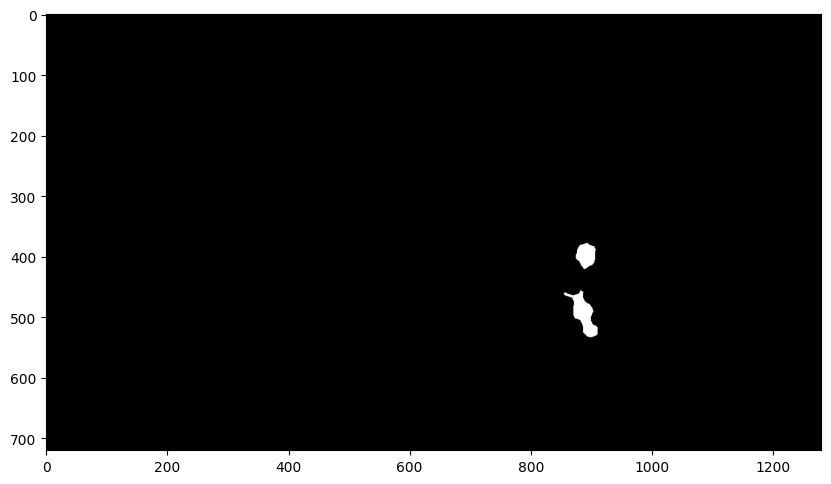

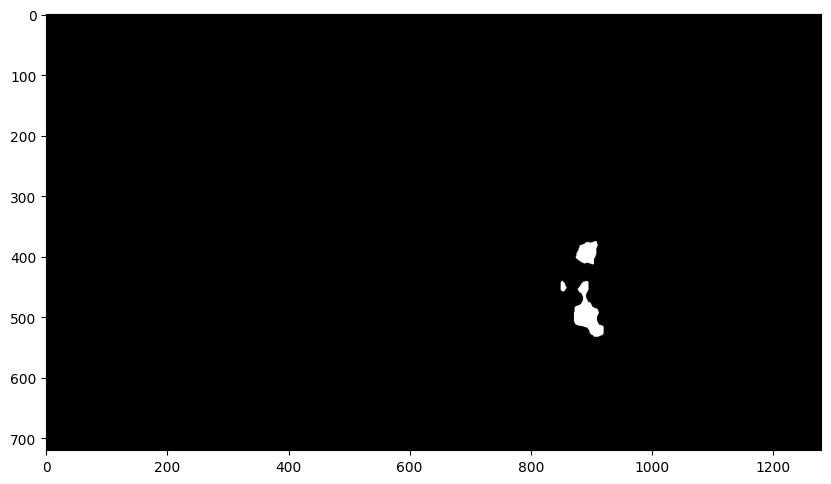

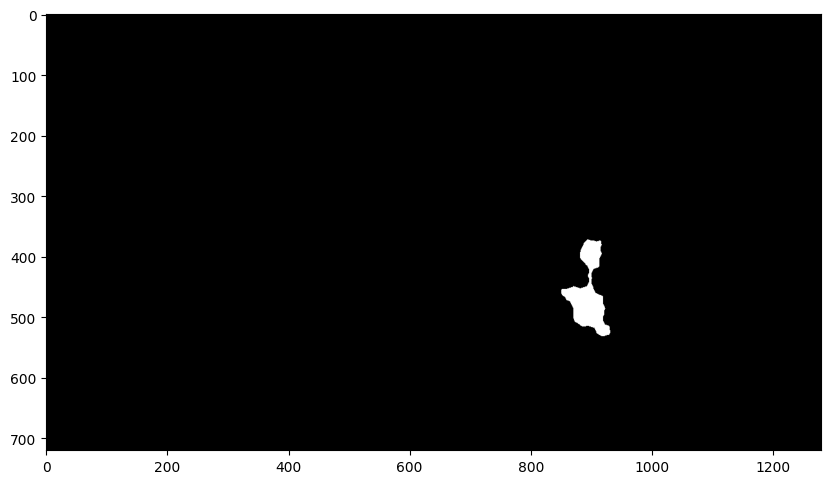

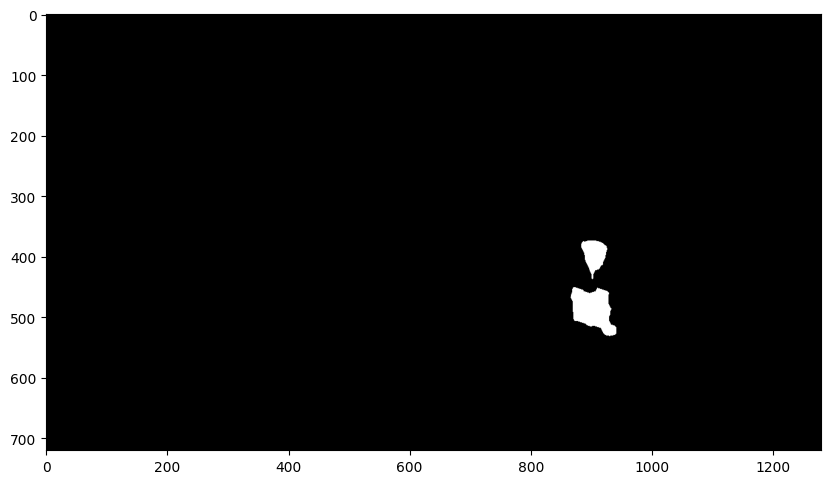

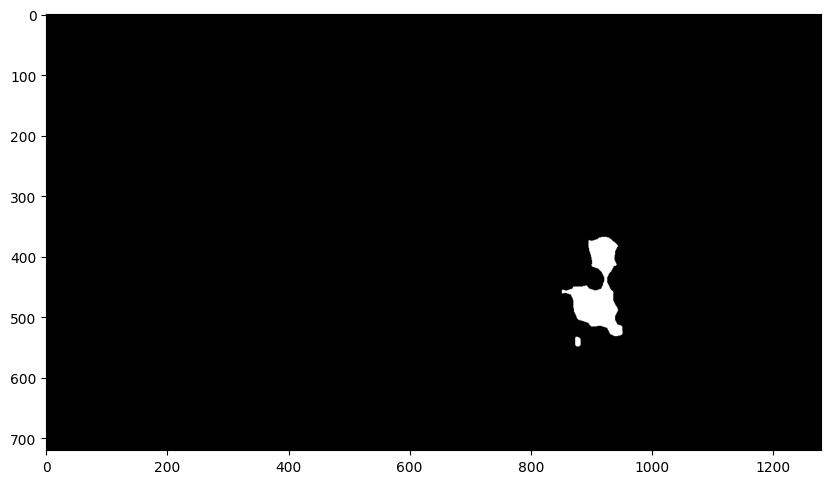

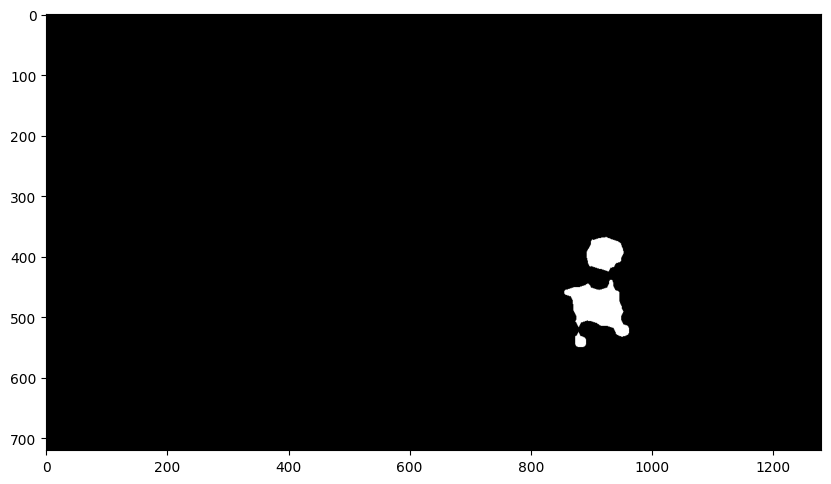

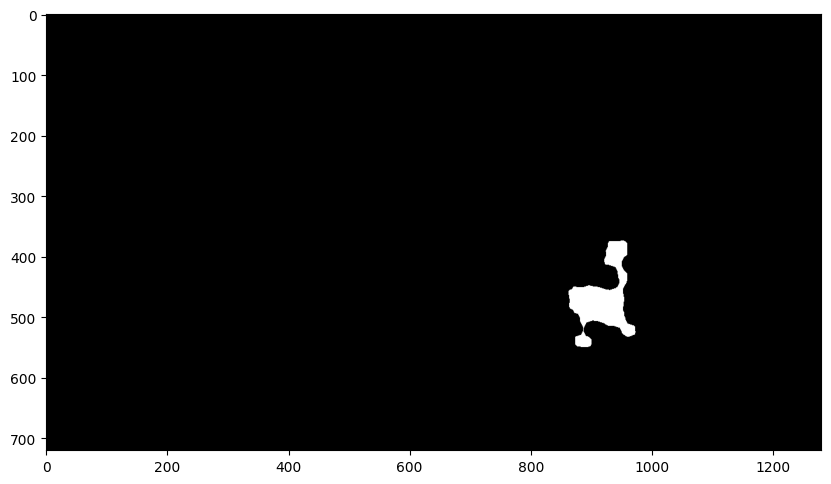

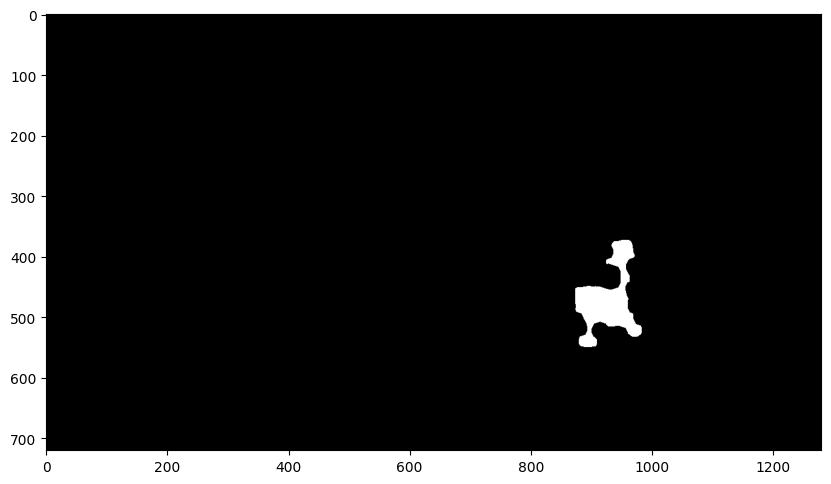

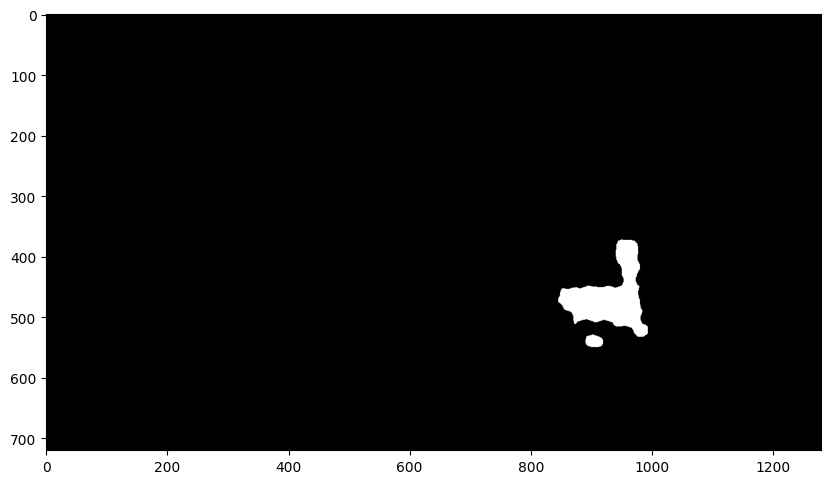

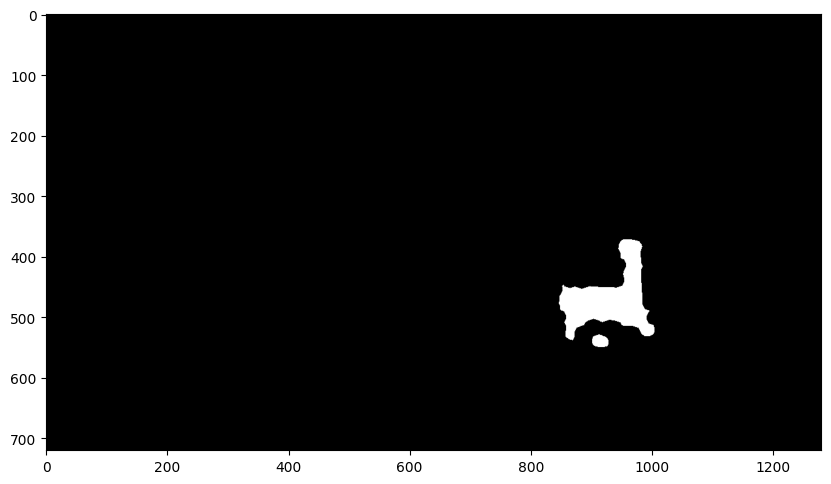

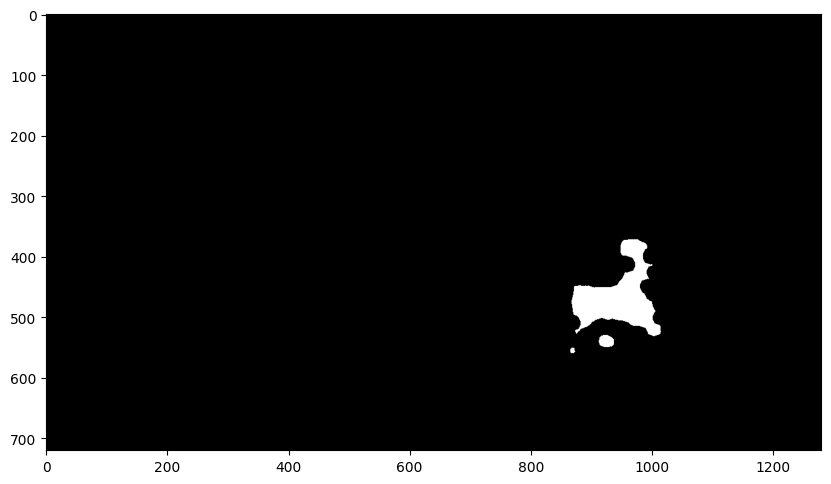

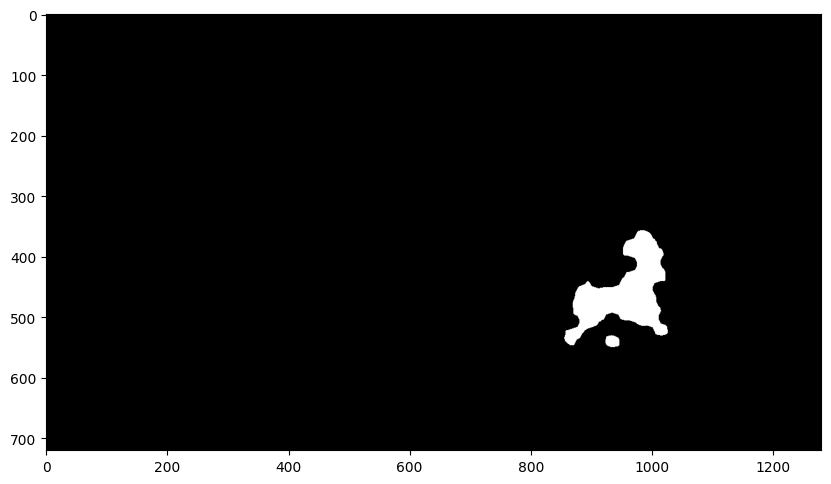

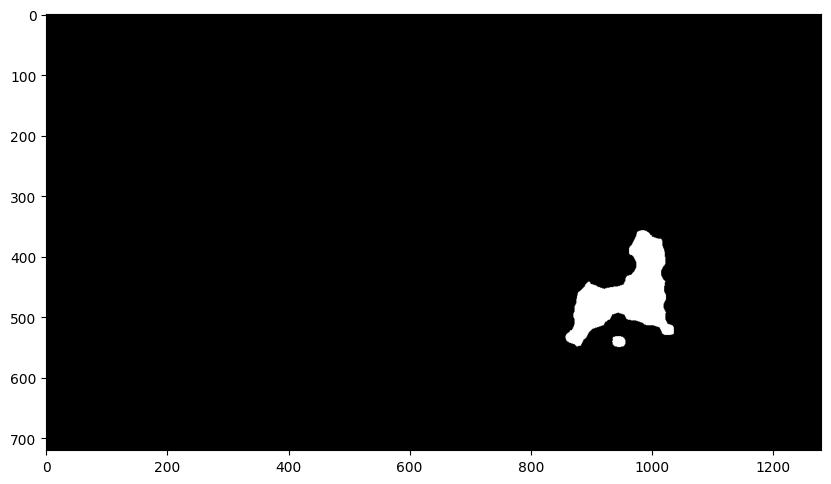

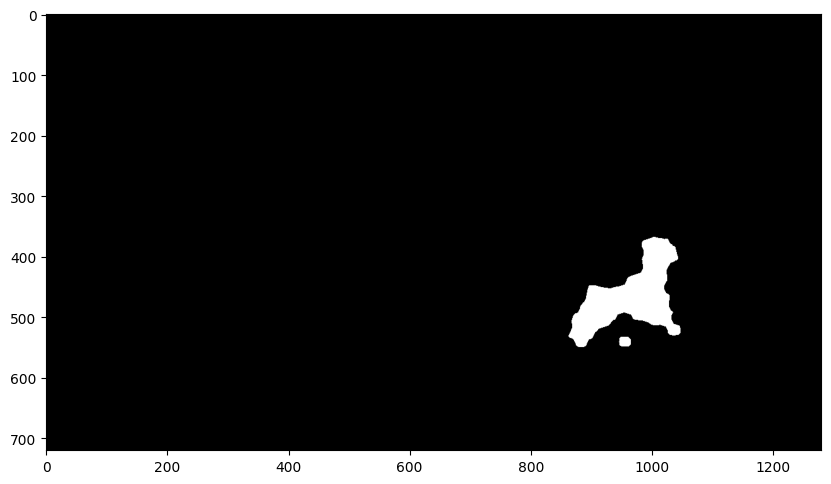

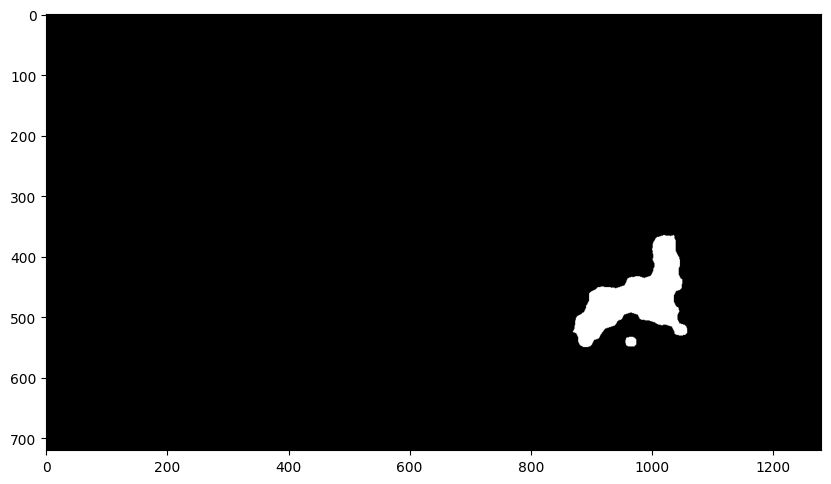

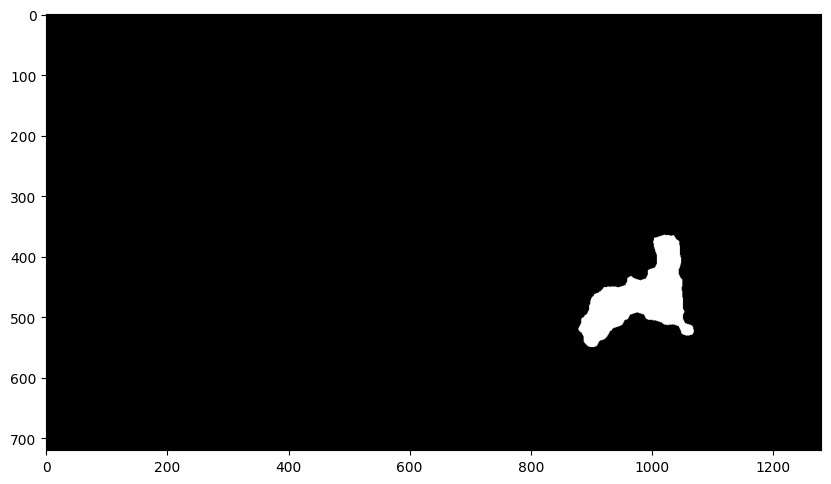

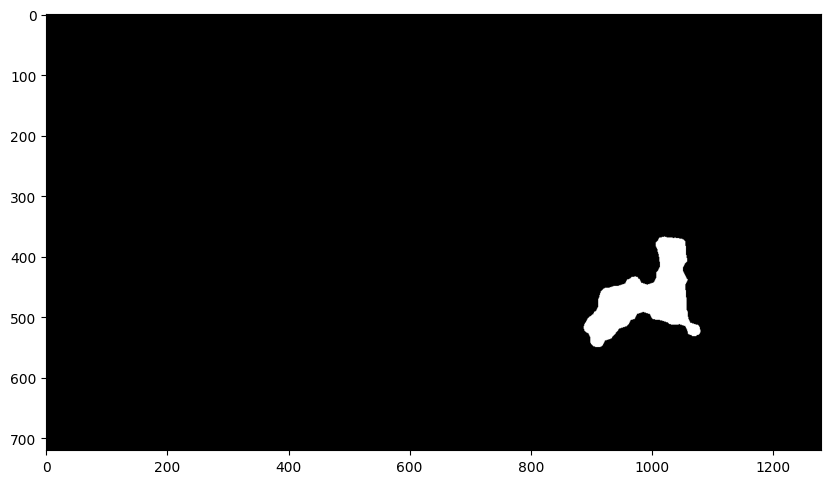

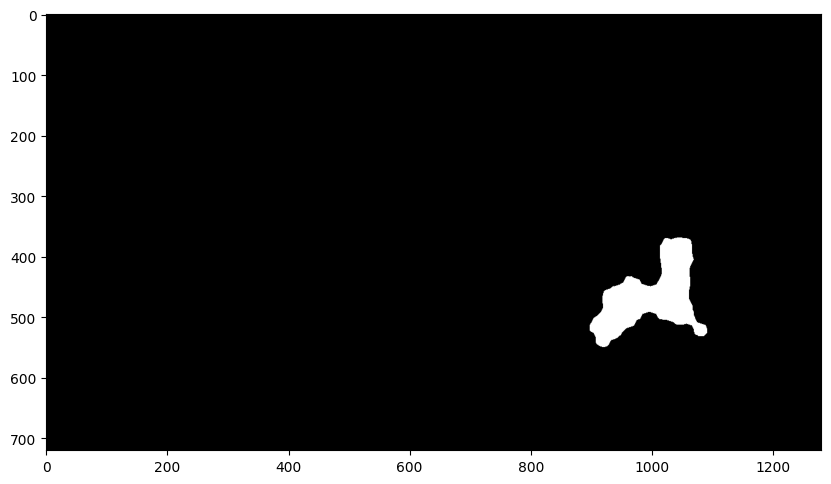

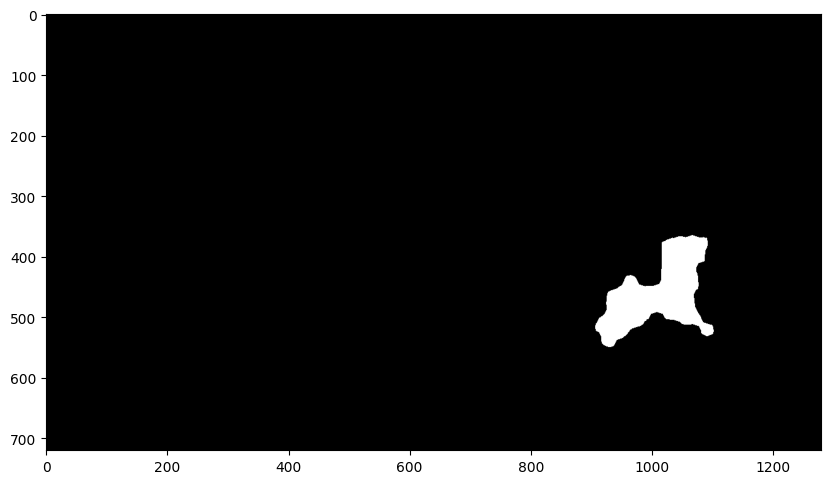

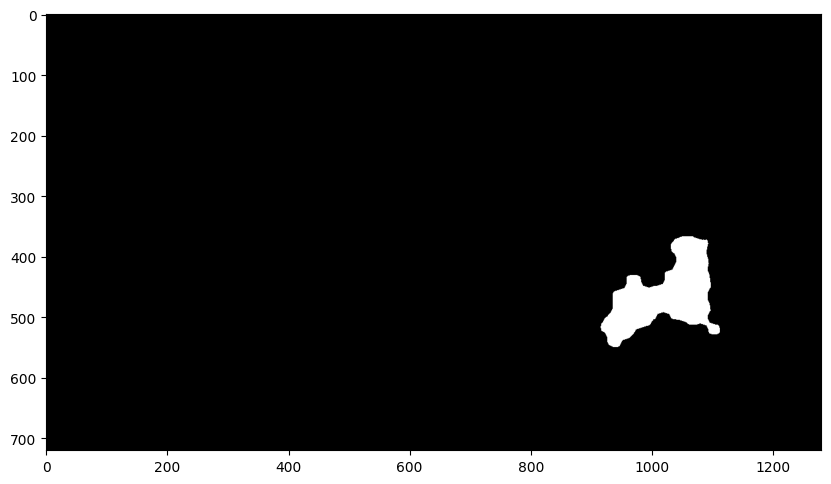

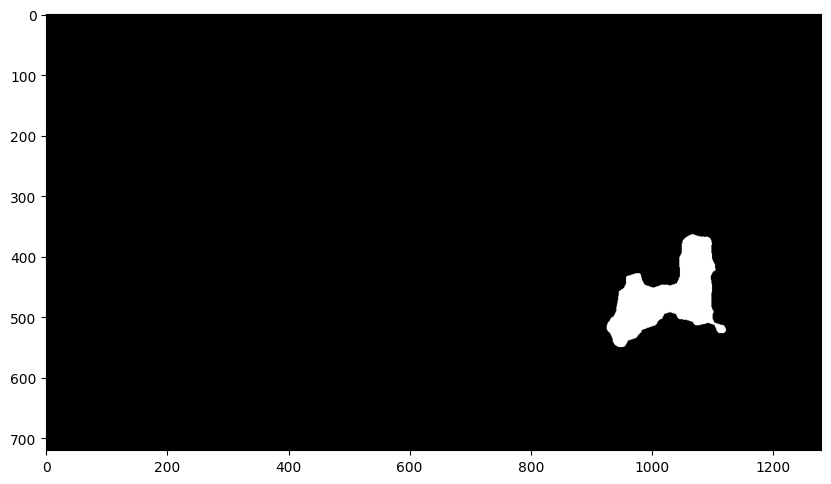

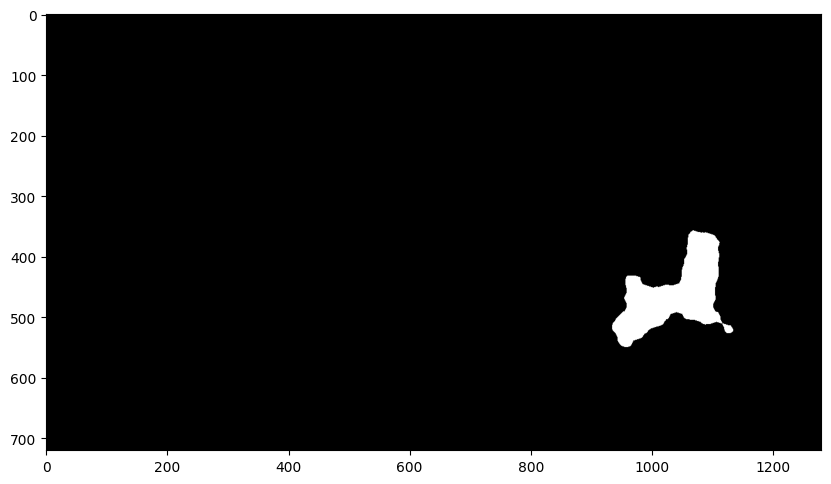

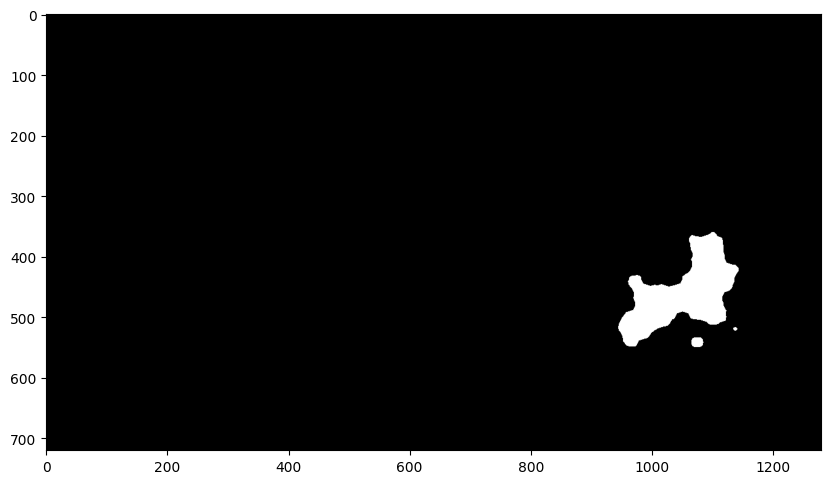

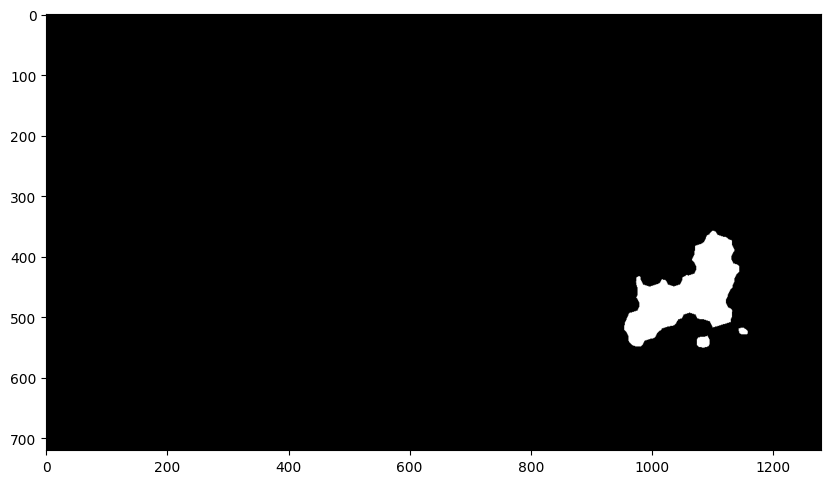

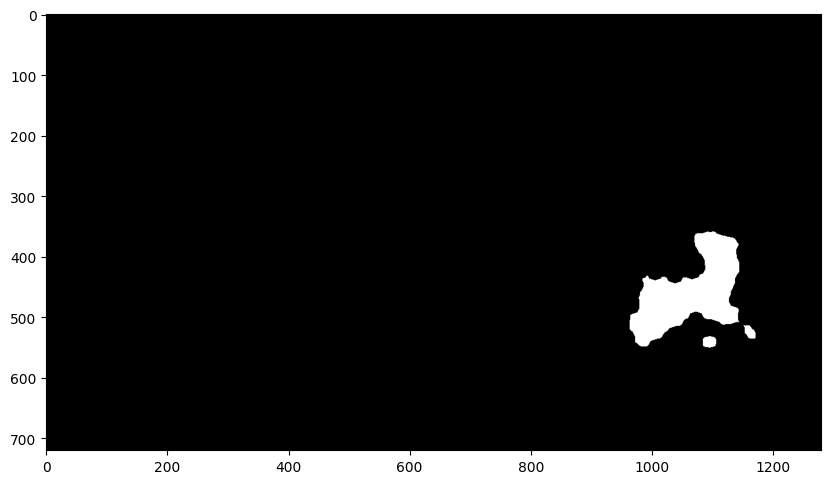

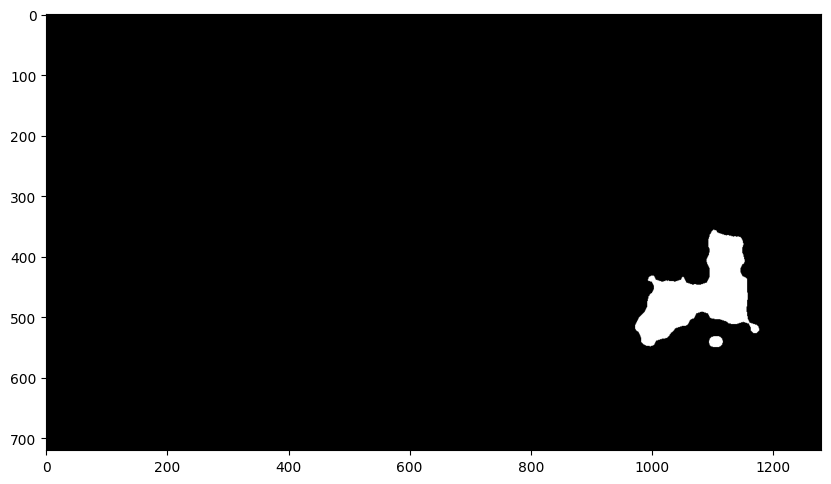

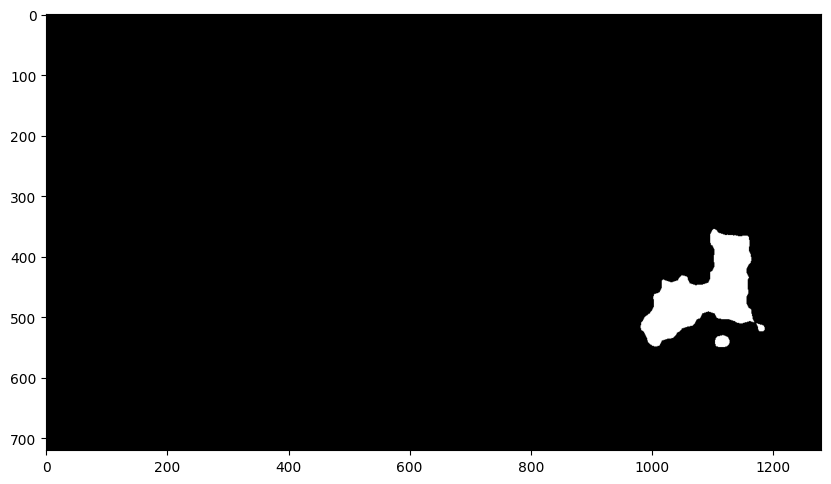

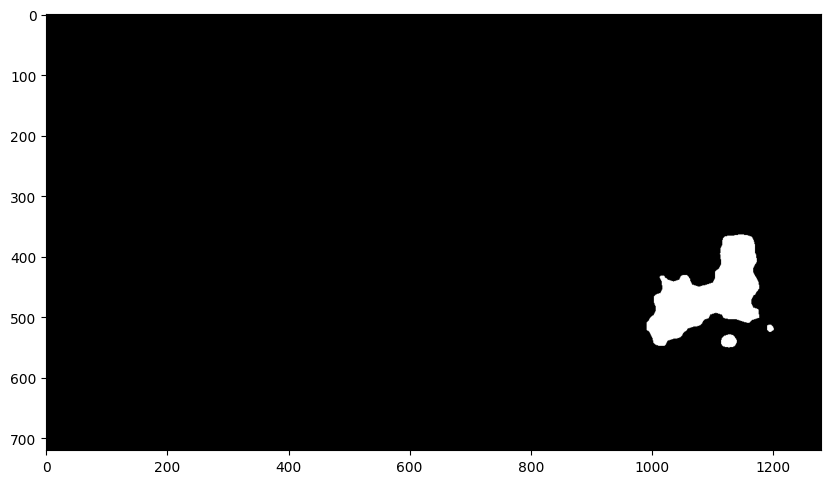

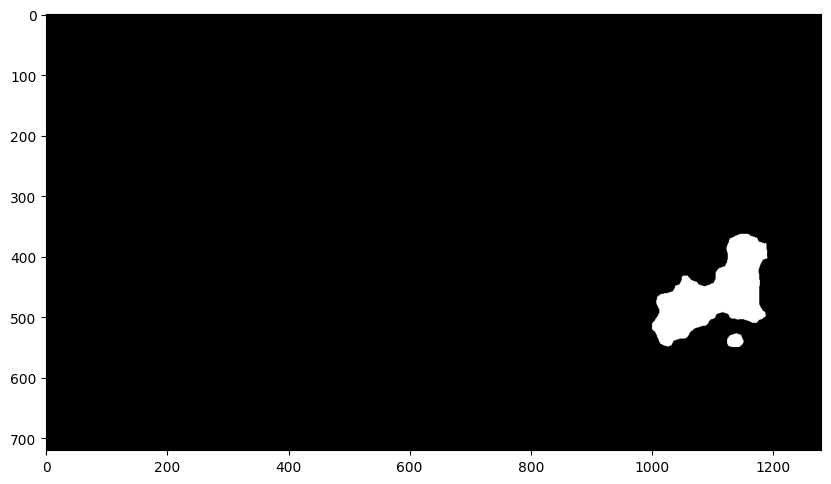

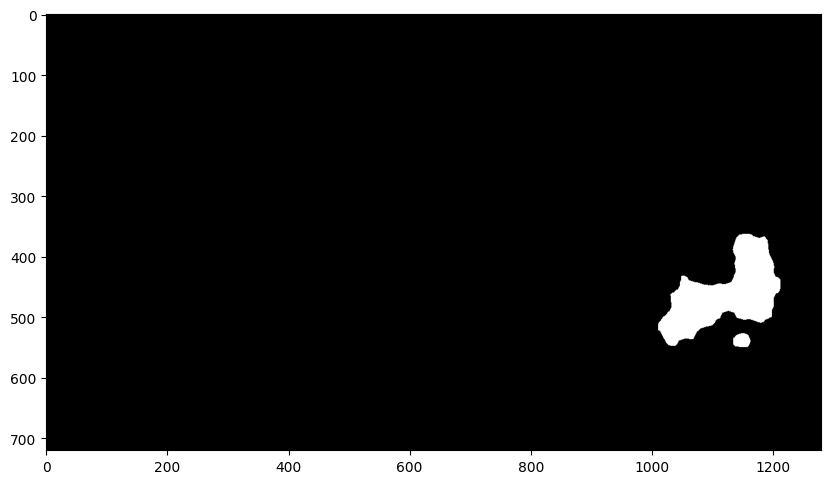

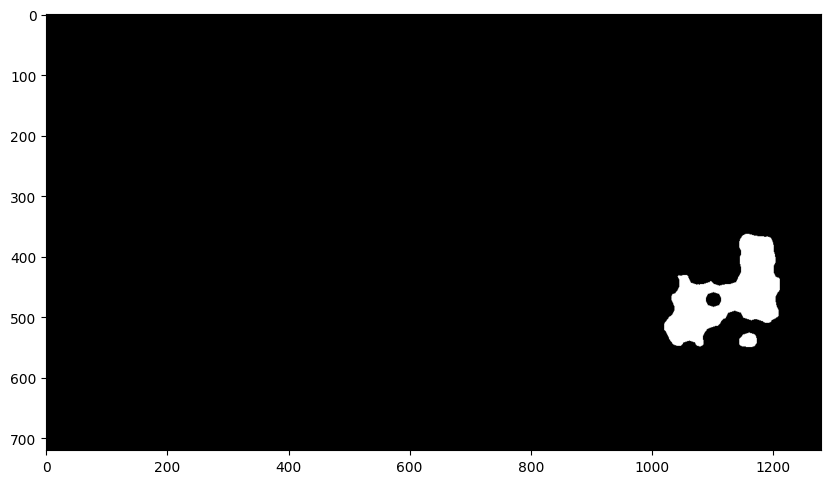

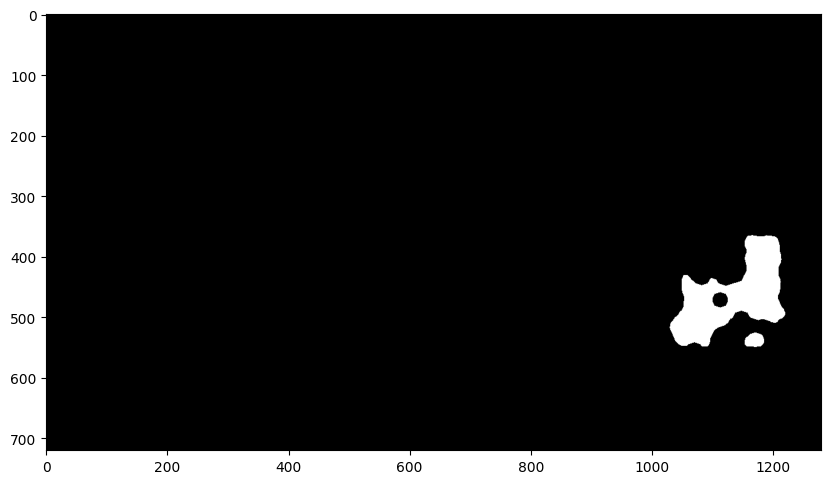

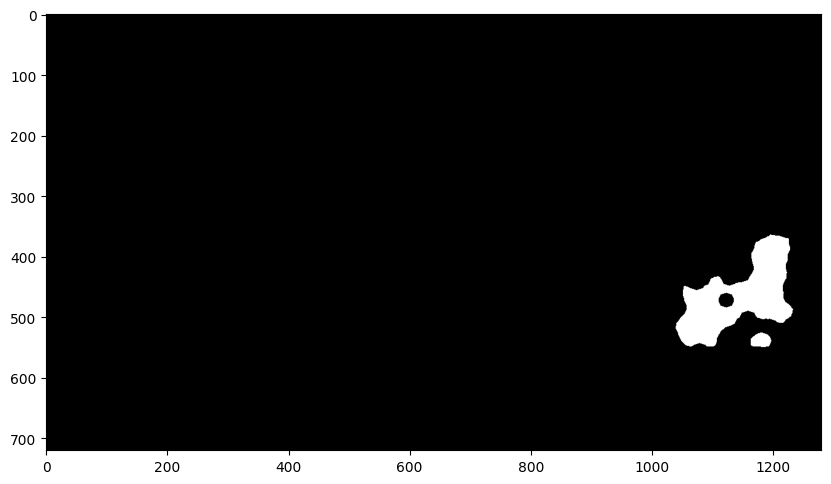

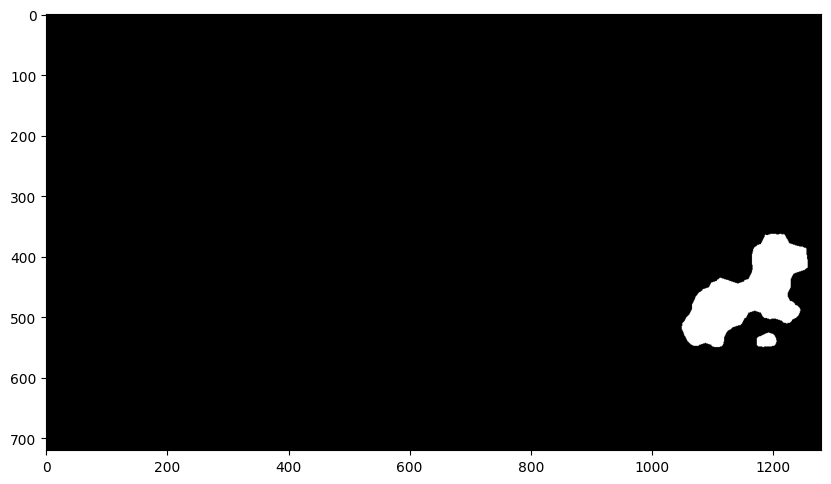

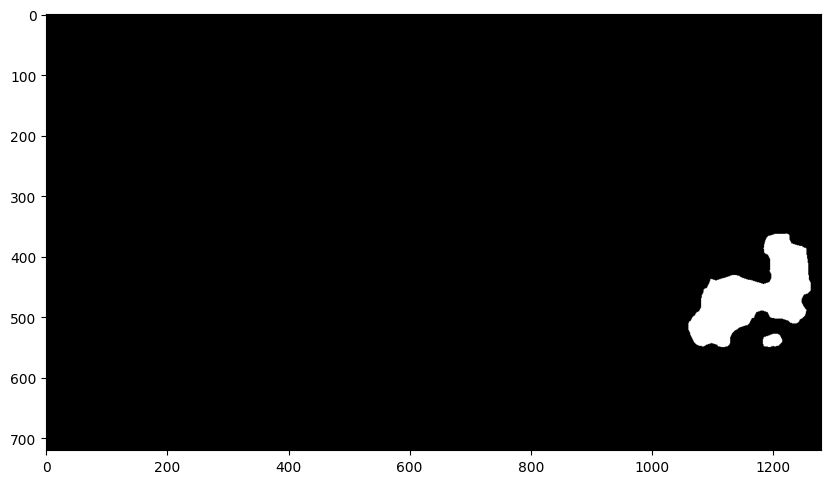

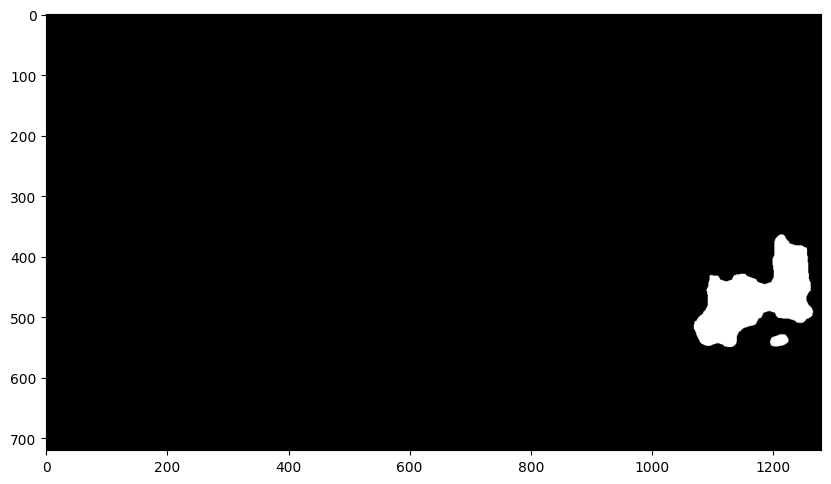

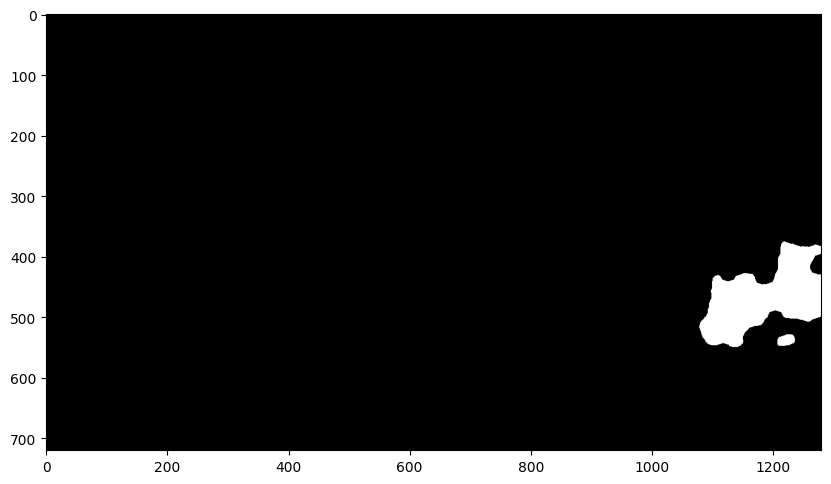

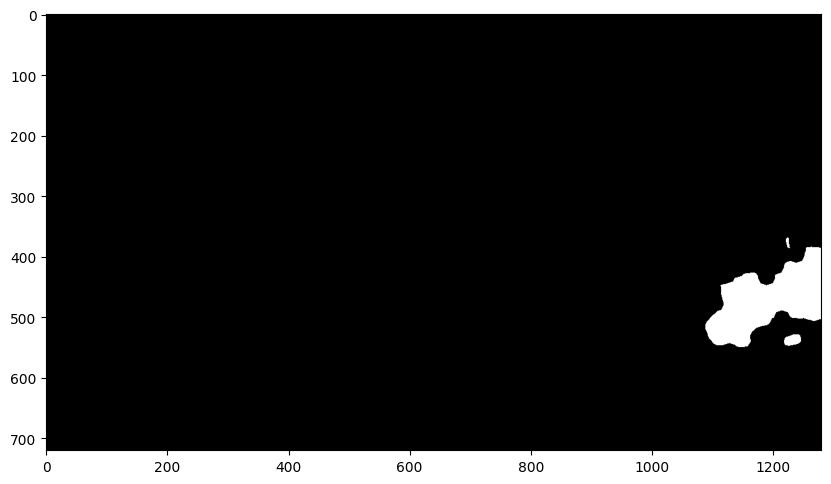

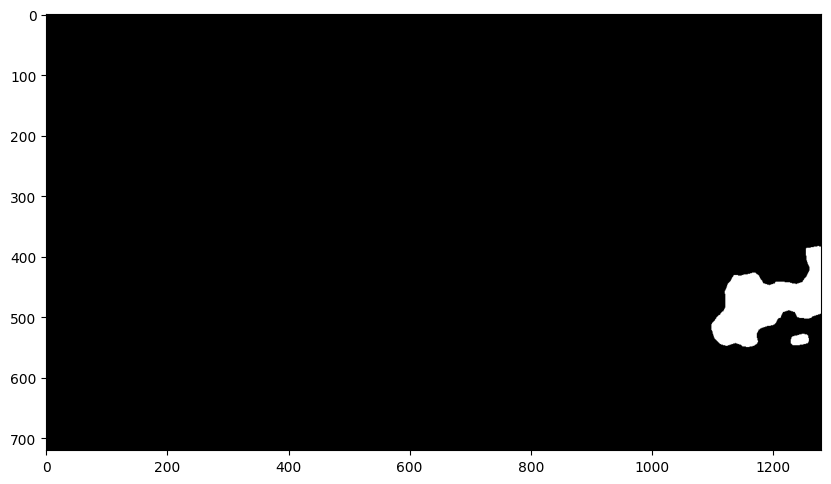

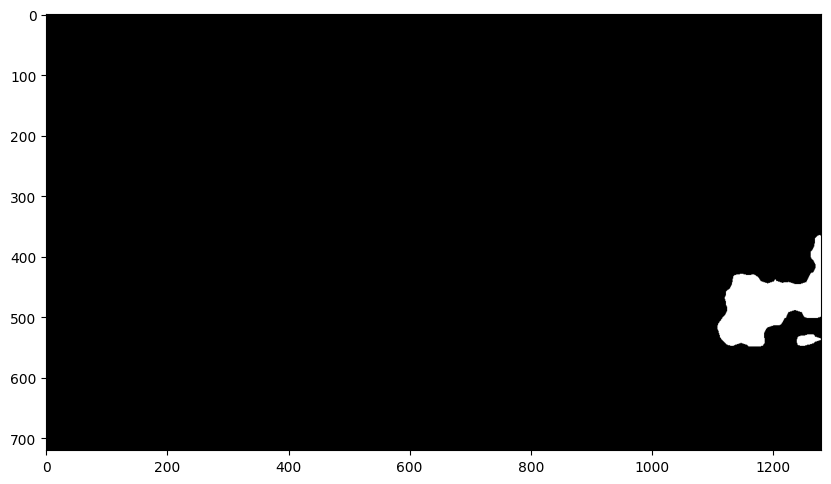

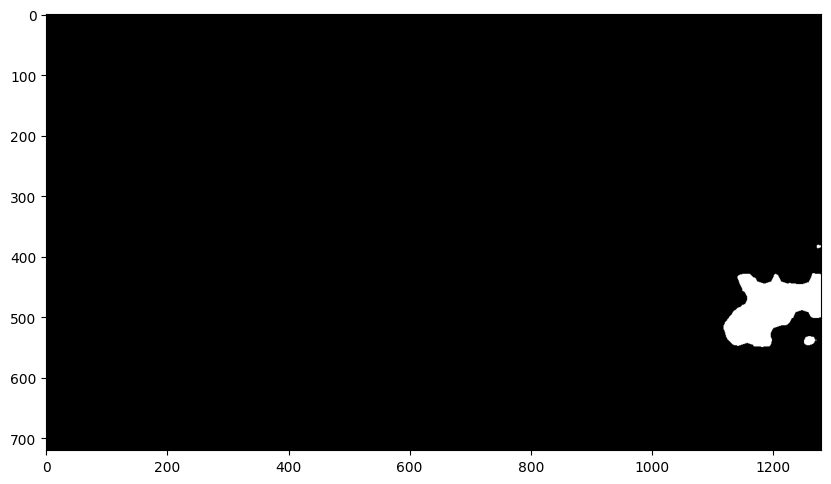

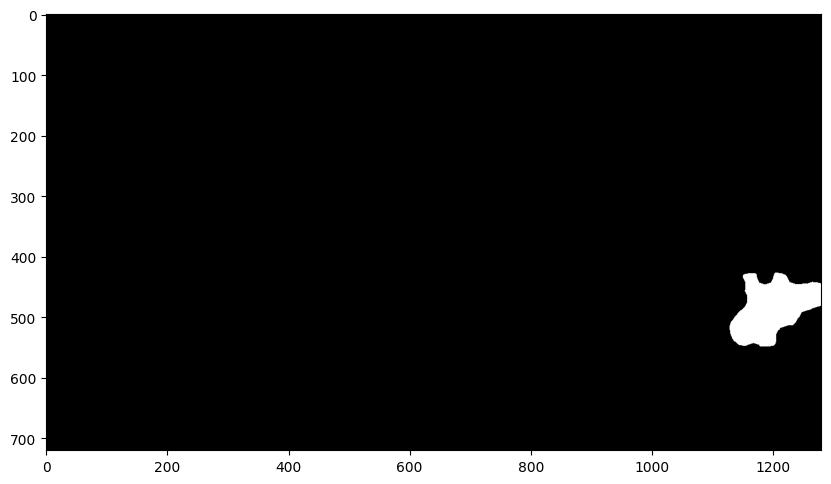

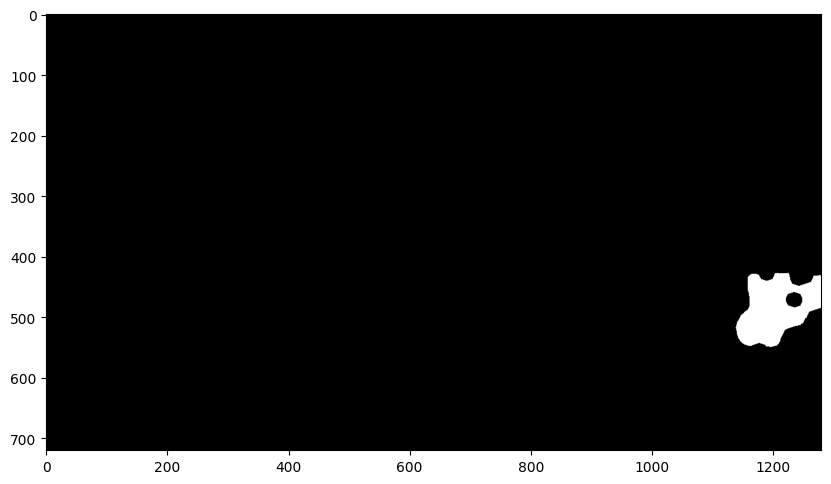

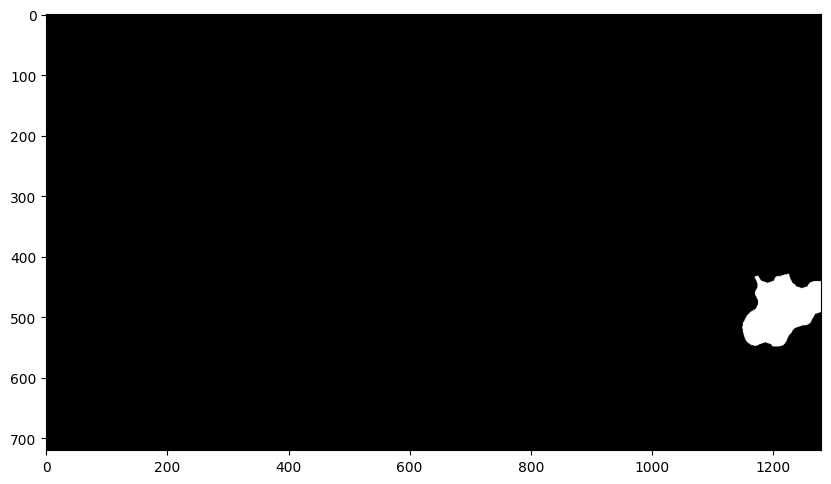

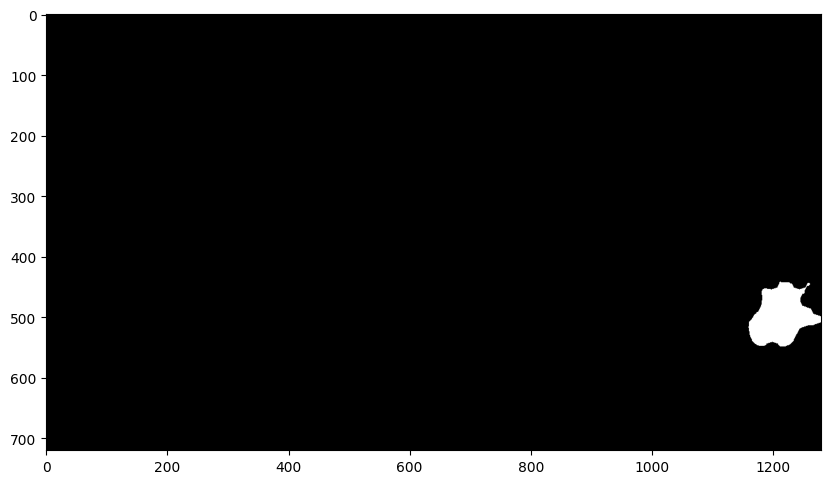

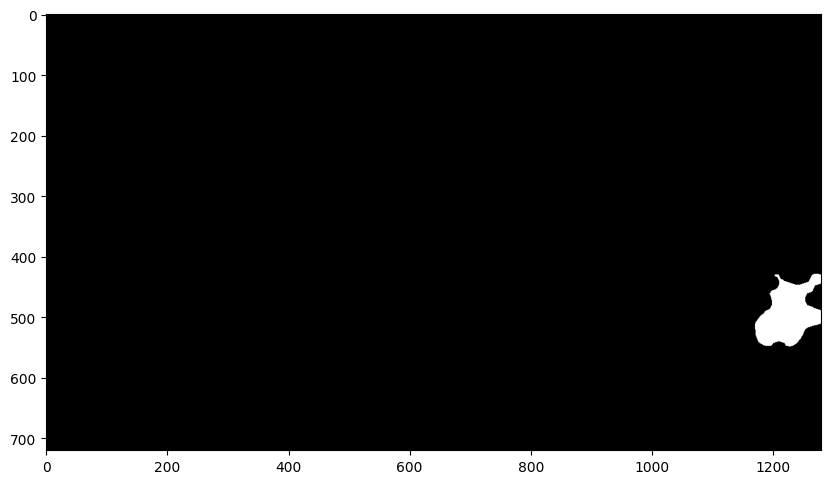

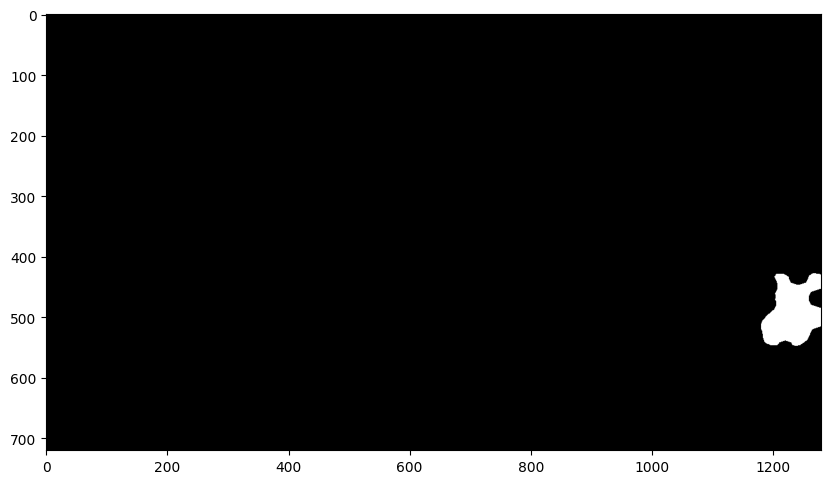

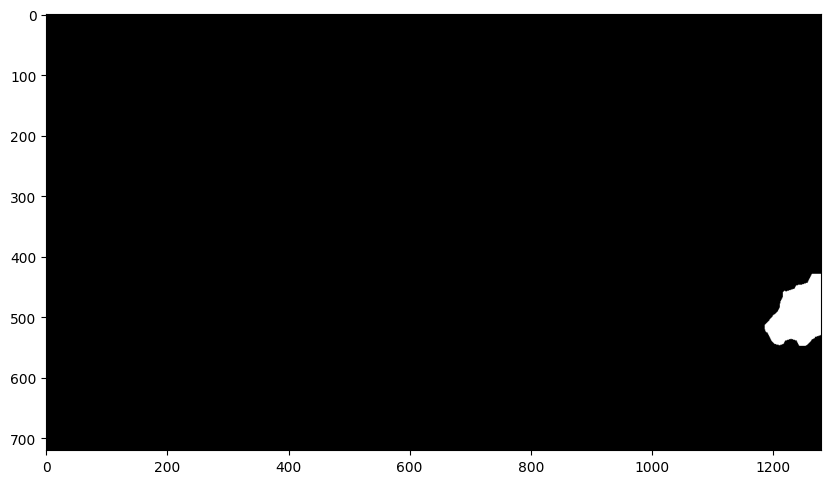

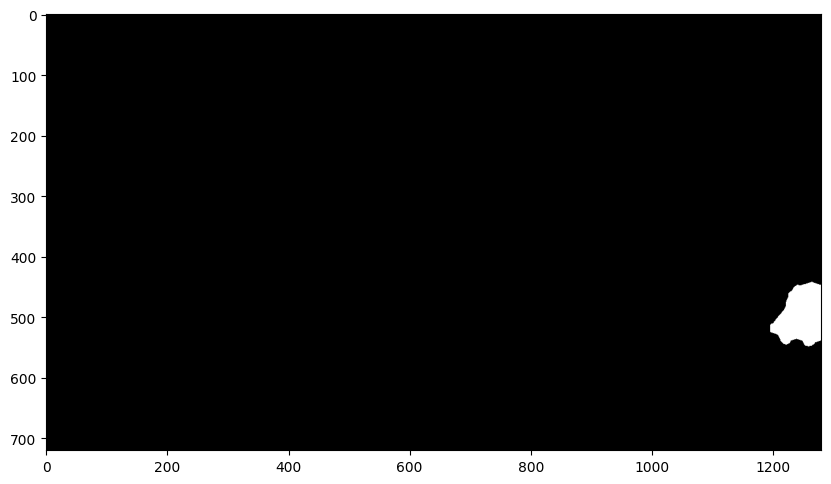

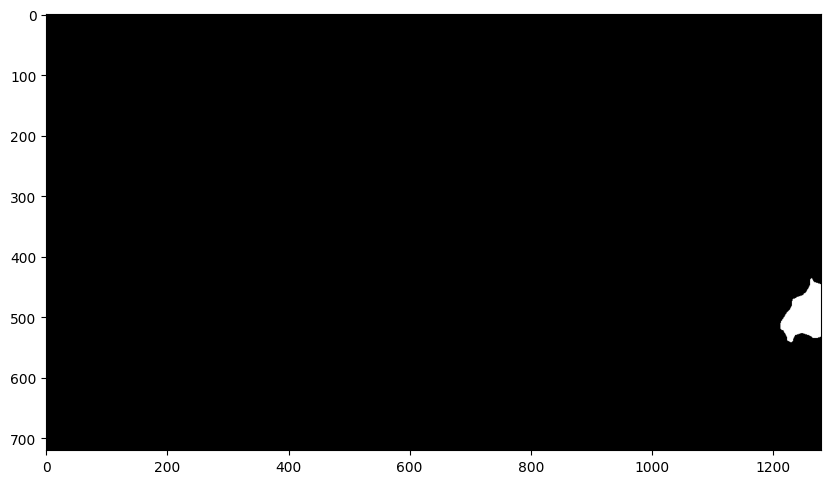

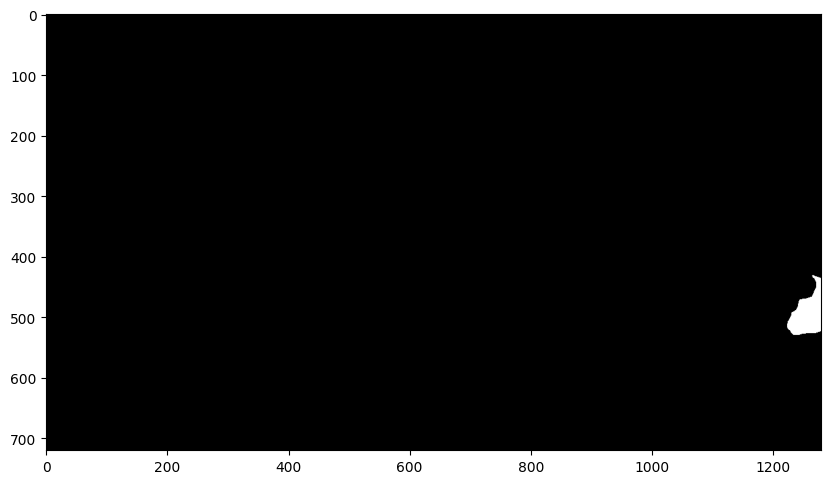

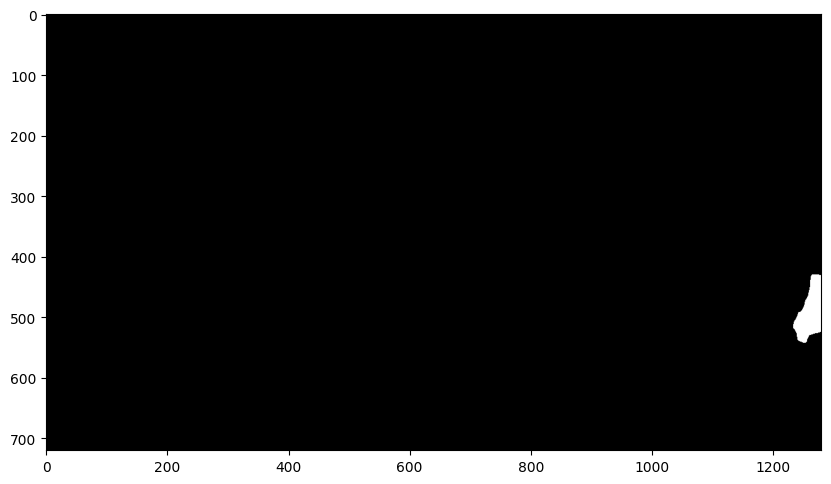

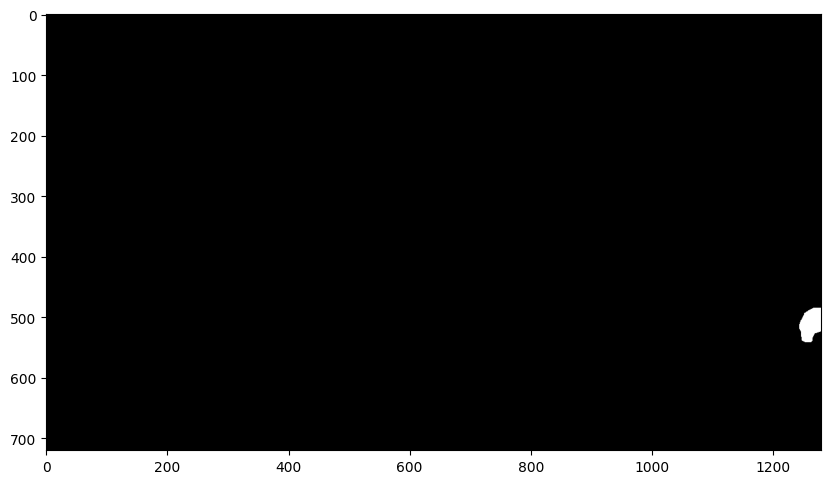

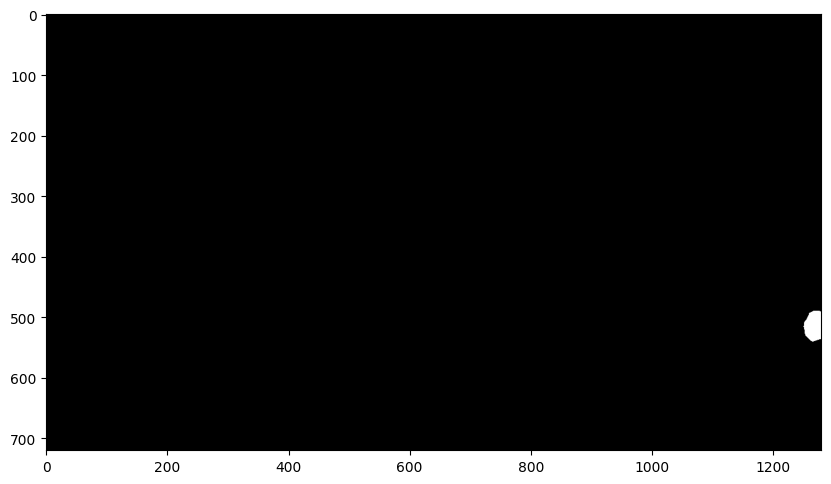

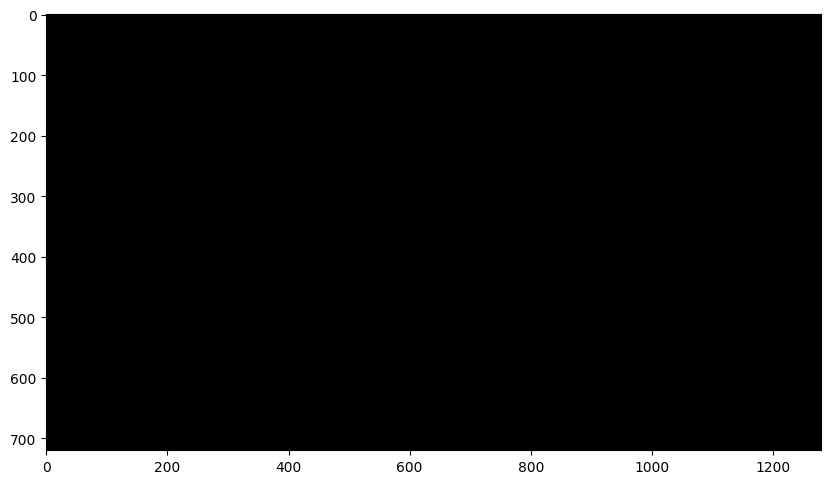

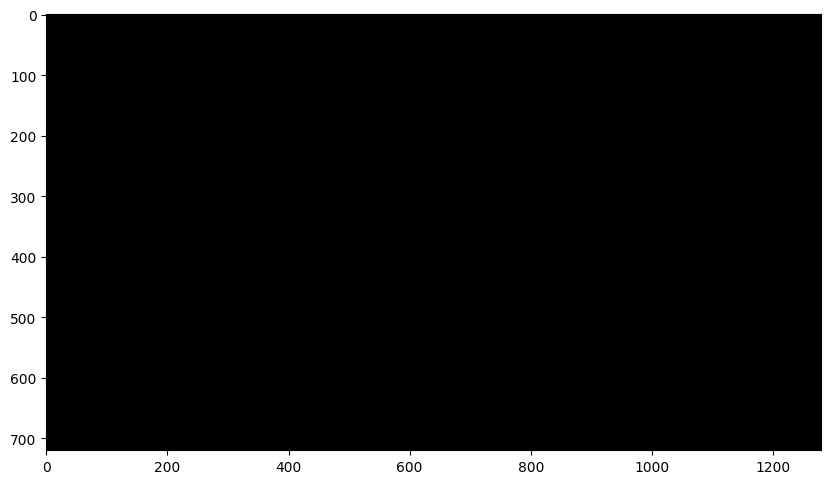

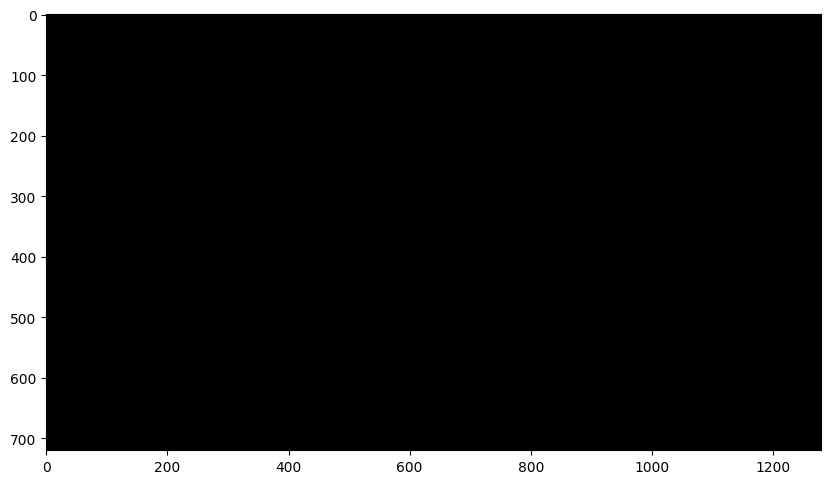

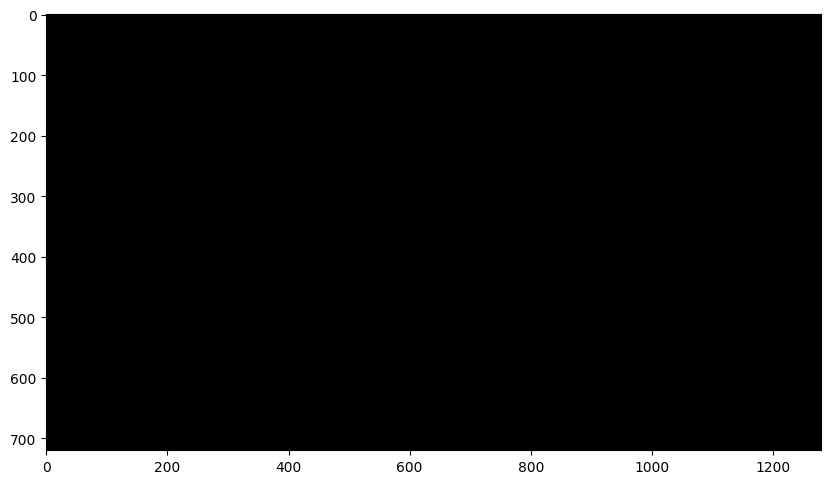

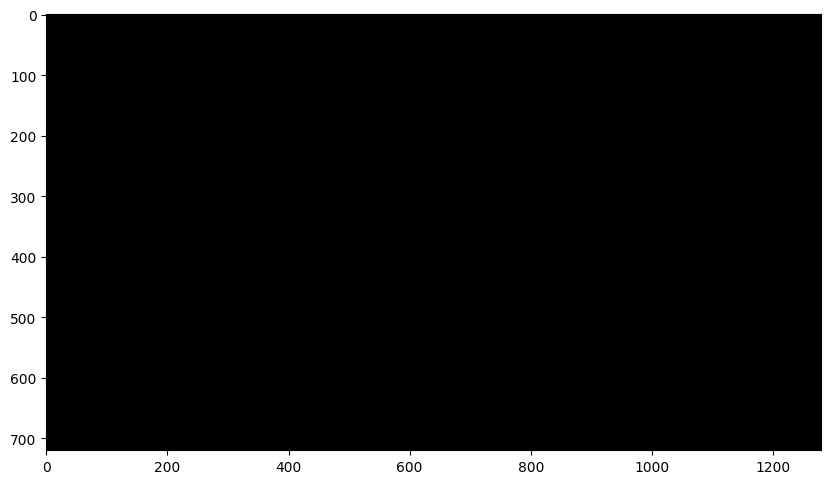

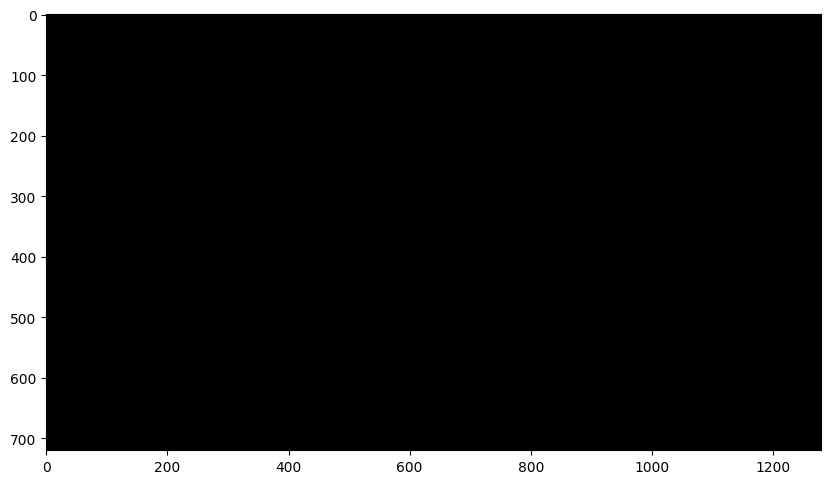

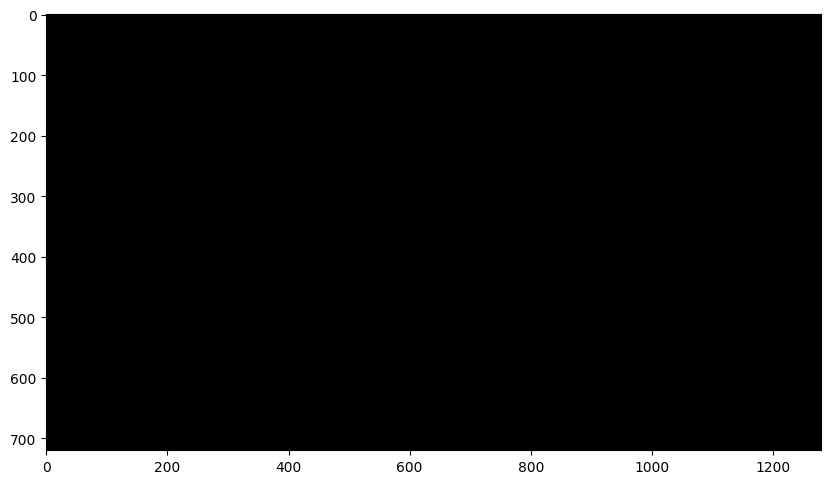

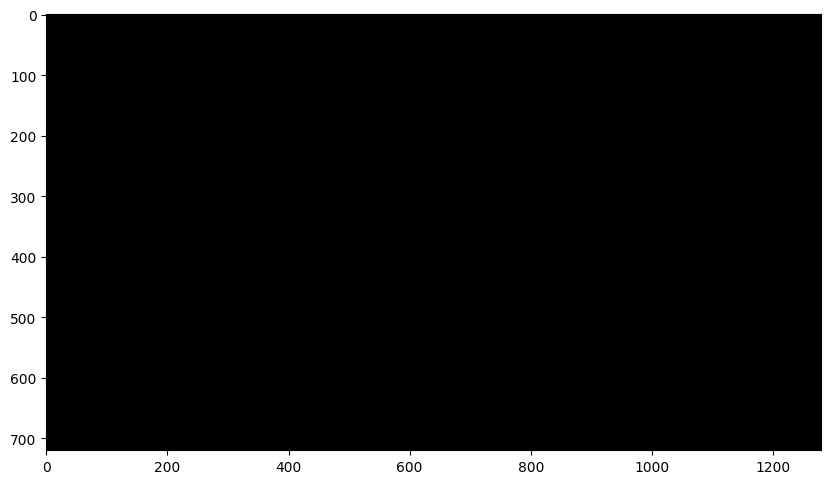

In [75]:
Masks = detect_robot_dense_optical(undistL, undistLg, undistR, undistRg)
for i in range(len(Masks)):
    plt.figure(figsize=(10, 6))
    plt.imshow(Masks[i], cmap='gray')

In [ ]:

    outputs = []
    
    for i, mask in enumerate(masks):

        # Find contours
        cnts = cv2.findContours(
            mask.copy(),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cnts = imutils.grab_contours(cnts)

        # Filter small contours
        large_contours = [
            contour for contour in cnts
            if cv2.contourArea(contour) > 10000
        ]

        # Corresponding original frame
        output = undistL[i + 1].copy()

        # Draw bounding boxes
        for contour in large_contours:
            x, y, w, h = cv2.boundingRect(contour)

            cv2.rectangle(
                output,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

        cv2.imshow("Motion Detection", output)
        if cv2.waitKey(20) & 0xFF == ord('q'):
            break
        outputs.append(output)

    cv2.destroyAllWindows()
    cv2.waitKey(1)

    return True


### box

In [ ]:
flows = []
magnitudes = []

for i in range(len(undistLg) - 1):

    gray1 = undistLg[i]
    gray2 = undistLg[i + 1]

    # Optical flow
    flow = cv2.calcOpticalFlowFarneback(
        gray1, gray2,
        None,
        0.5, 3, 15, 3, 5, 1.5, 0
    )

    mag,theta = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    flows.append(flow)
    magnitudes.append(mag)

threshold = 2.0
kernel2 = np.ones((11, 11), np.uint8)
masks = [
    (magnitude > threshold).astype(np.uint8) * 255
    for magnitude in magnitudes
]

masks = [cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel2)for mask in masks]
masks = [cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel2)for mask in masks]

In [ ]:
outputs = []

for i, mask in enumerate(masks):

    # Find contours
    cnts = cv2.findContours(
        mask.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cnts = imutils.grab_contours(cnts)

    # Filter small contours
    large_contours = [
        contour for contour in cnts
        if cv2.contourArea(contour) > 10000
    ]

    # Corresponding original frame
    output = undistL[i + 1].copy()

    # Draw bounding boxes
    for contour in large_contours:
        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

    cv2.imshow("Motion Detection", output)
    if cv2.waitKey(20) & 0xFF == ord('q'):
        break
    outputs.append(output)

cv2.destroyAllWindows()
cv2.waitKey(1)


-1

sparse gray

In [ ]:
idx = 0
gray1 = undistLg[idx]

while True:

    gray2 = undistLg[idx+1]

    # find features to track
    feat1 = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.2, minDistance=5)
    feat2, status, error = cv2.calcOpticalFlowPyrLK(gray1, gray2, feat1, None)

    # display moving features on video
    img_op = gray2.copy()
    threshold = 2
    for i in range(len(feat1)):
        f10=int(feat1[i][0][0])
        f11=int(feat1[i][0][1])
        f20=int(feat2[i][0][0])
        f21=int(feat2[i][0][1])
        if abs(f10-f20) >= threshold or abs(f11-f21) >= threshold:
            cv2.line(img_op, (f10,f11), (f20, f21), (0, 255, 0), 2)
            cv2.circle(img_op, (f10, f11), 5, (0, 255, 0), -1)

    # display image
    cv2.imshow('image', img_op)

    if cv2.waitKey(20) & 0xFF == ord('q'):
        break

    # done processing, update last frame
    gray1 = gray2
    idx += 1
    

cv2.destroyAllWindows()
cv2.waitKey(1)

IndexError: list index out of range

In [ ]:
# Sparse optical flow with static-feature filtering
last_frame = len(undistL) - 1
first_frame = undistL[0]
previous_gray = undistLg[0]

previous_points = cv2.goodFeaturesToTrack(
    previous_gray,
    maxCorners=200,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

if previous_points is None:
    raise RuntimeError("No trackable features were found.")

motion_threshold = 1.0
maximum_static_frames = 30

# One counter for each tracked feature
static_frame_counts = np.zeros(len(previous_points), dtype=int)

lk_parameters = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

idx = 1

while idx <= last_frame:
    frame = undistL[idx]
    current_gray = undistLg[idx]

    current_points, status, error = cv2.calcOpticalFlowPyrLK(
        previous_gray,
        current_gray,
        previous_points,
        None,
        **lk_parameters
    )

    # if current_points is None or status is None:
    #     break

    # Keep only successfully tracked points
    valid_mask = status.ravel() == 1

    valid_previous = previous_points[valid_mask].reshape(-1, 2)
    valid_current = current_points[valid_mask].reshape(-1, 2)
    valid_static_counts = static_frame_counts[valid_mask]

    # Calculate movement in pixels
    displacement = valid_current - valid_previous
    movement = np.linalg.norm(displacement, axis=1)

    # Increase the counter if movement is less than 1 pixel.
    # Reset it when the feature moves at least 1 pixel.
    valid_static_counts = np.where(
        movement < motion_threshold,
        valid_static_counts + 1,
        0
    )

    # Remove features static for 30 consecutive frames
    keep_mask = valid_static_counts < maximum_static_frames

    kept_previous = valid_previous[keep_mask]
    kept_current = valid_current[keep_mask]
    kept_static_counts = valid_static_counts[keep_mask]
    kept_movement = movement[keep_mask]

    # Display only features that moved at least 1 pixel
    for previous_point, current_point, movement_value in zip(
        kept_previous,
        kept_current,
        kept_movement
    ):
        if movement_value >= motion_threshold:
            x_previous, y_previous = previous_point.astype(int)
            x_current, y_current = current_point.astype(int)

            cv2.line(
                frame,
                (x_previous, y_previous),
                (x_current, y_current),
                (0, 255, 0),
                2
            )

            cv2.circle(
                frame,
                (x_current, y_current),
                4,
                (0, 0, 255),
                -1
            )

    cv2.imshow("Sparse optical flow", frame)

    # Press q to stop
    if cv2.waitKey(20) & 0xFF == ord("q"):
        break

    previous_gray = current_gray
    idx += 1

    # Detect new features if too few tracked features remain
    if len(kept_current) < 30:
        previous_points = cv2.goodFeaturesToTrack(
            previous_gray,
            maxCorners=200,
            qualityLevel=0.3,
            minDistance=7,
            blockSize=7
        )

        if previous_points is None:
            break

        static_frame_counts = np.zeros(len(previous_points), dtype=int)

    else:
        previous_points = kept_current.reshape(-1, 1, 2)
        static_frame_counts = kept_static_counts

cv2.destroyAllWindows()
cv2.waitKey(1)

-1

In [ ]:
def KalmanPredict(x, P, F, u, Q):
    """
    Kalman prediction step — project the state forward one timestep using
    the motion model F and control input u.

    Steps:
      x = F·x + u    Apply physics: advance position by current velocity
      P = F·P·Fᵀ     Propagate uncertainty (grows because we're extrapolating)

    Note: a full implementation would add process noise Q here (P = F·P·Fᵀ + Q),
    but Q=0 is assumed (perfect motion model).
    """
    x = F@x + u          # Predict next state
    P = F@P@ F.T +Q # Predict next covariance
    return [x, P]

def KalmanUpdate(x, P, Z, H, R):
    """
    Kalman measurement update — fuse a new observation Z into the current
    state estimate x and covariance P.

    Steps:
      y = z - H·x        Innovation: how far off was our prediction?
      S = H·P·Hᵀ + R     Innovation covariance (uncertainty of the prediction in measurement space)
      K = P·Hᵀ·S⁻¹       Kalman gain: how much to trust the measurement vs. the model
      x = x + K·y        Nudge state toward the measurement, weighted by K
      P = (I - K·H)·P    Reduce uncertainty — we've gained information
    """
    y = Z - H @ x                          # Innovation
    S = H @ P @ H.T + R             # Innovation covariance
    K = P @ H.T @ np.linalg.pinv(S) # Kalman gain
    x = x + K @ y                          # State update
    P = (I - K @ H) @ P             # Covariance update
    return [x, P]

In [ ]:
def filter_robot_positions_jerk(
    robot_positions,
    dt,
    measurement_std,
    jerk_std,
    initial_velocity_std,
    initial_acceleration_std
):
    measurements = np.asarray(robot_positions, dtype=float)
    filtered = np.full_like(measurements, np.nan)

    I = np.eye(3)
    kf = cv2.KalmanFilter(9, 3, 0, cv2.CV_64F)

    F = np.eye(9)
    F[0:3, 3:6] = dt * I
    F[0:3, 6:9] = 0.5 * dt**2 * I
    F[3:6, 6:9] = dt * I
    kf.transitionMatrix = F

    # Measurements still contain position only: x, y, z.
    H = np.zeros((3, 9))
    H[:, :3] = I
    kf.measurementMatrix = H

    # Measurement uncertainty.
    R = measurement_std**2 * np.eye(3)
    kf.measurementNoiseCov = R  

    G = np.vstack([
        (dt**3 / 6) * I,
        (dt**2 / 2) * I,
        dt * I,
    ])

    kf.processNoiseCov = jerk_std**2 * (G @ G.T)

    initialized = False

    for i, position in enumerate(measurements):
        valid = np.isfinite(position).all()

        if not initialized:
            if not valid:
                continue

            kf.statePost = np.concatenate([
                position, np.zeros(6)
            ]).reshape(9, 1)

            kf.errorCovPost = np.diag(
                [measurement_std**2] * 3
                + [initial_velocity_std**2] * 3
                + [initial_acceleration_std**2] * 3
            )

            filtered[i] = position
            initialized = True
            continue

        prediction = kf.predict()

        if valid:
            estimate = kf.correct(position.reshape(3, 1))
        else:
            estimate = prediction

        filtered[i] = estimate[:3, 0]

    return filtered

In [ ]:
def pipeline(left_images,right_images,left_images_gray,right_images_gray,fps):    
### pipeline 
    # Construct stereo matchers
    left_matcher, right_matcher, wls = create_stereo_matchers()

    # Disparity map calculation
    disparity_map = calculate_disparity_map(left_matcher, right_matcher, wls, left_images_gray[0], right_images_gray[0])

    # Construct the scene point cloud from disparity map
    scene_pcd = point_cloud_from_disparity(disparity_map, left_images[0], Q)

    # Construct robot foreground masks.
    robot_foreground_masks = robot_masking_MOG2(left_images)

    # Reconstruct the robot and its trajectory.
    robot_pcds, robot_positions = reconstruct_robot_trajectory(
        left_images,
        left_images_gray,
        right_images_gray,
        robot_foreground_masks,
        left_matcher,
        right_matcher,
        wls,
        Q,
    )

    filtered_positions = filter_robot_positions_jerk(
        robot_positions,
        dt=1 / fps,                         # Actual frame interval in seconds
        measurement_std=0.5,
        jerk_std = 5.0,
        initial_velocity_std = 10,
        initial_acceleration_std = 10.0,
    )

    return scene_pcd, robot_positions, filtered_positions

In [23]:
pcd, robot_positions, filtered_positions = pipeline(*load_and_undistort_images("2_obstacle"),30)
visualize_robot_trajectory(pcd, filtered_positions)